# Desenlaces clínicos y hallazgos endoscópicos en pacientes sometidos a SpyGlass: análisis de cohorte institucional SPY-OUT (EDA)

**Autor:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co), Paula Gómez Vargas [✉](mailto:apaulag@uninorte.edu.co)

## Introducción

La colangioscopía digital mediante el sistema SpyGlass permite la visualización directa de la vía biliar y constituye una herramienta de apoyo para la evaluación de diferentes alteraciones pancreatobiliares. Además de la inspección endoscópica, el procedimiento permite obtener biopsias dirigidas sobre áreas de interés, aportando información complementaria para la caracterización y el diagnóstico de las lesiones.

En este contexto, el presente proyecto se centra en el análisis de información clínica proveniente de pacientes sometidos a procedimientos con SpyGlass en la Clínica de la Costa. La información disponible reúne diferentes características relacionadas con los pacientes, las indicaciones del procedimiento, los hallazgos observados y los resultados obtenidos, permitiendo estudiar el comportamiento de estas variables y las posibles relaciones existentes entre ellas.

Como primera etapa del proyecto, se desarrolla un Análisis Exploratorio de Datos (EDA) orientado a comprender la estructura y calidad de la información disponible, caracterizar la población estudiada y describir las principales variables clínicas y asociadas con el procedimiento. Asimismo, esta exploración permite identificar valores faltantes, posibles inconsistencias, distribuciones relevantes y relaciones entre variables que puedan orientar las etapas posteriores del análisis.

Los resultados del EDA constituyen la base para definir las decisiones de procesamiento y las estrategias estadísticas que resulten pertinentes de acuerdo con las características de los datos y los objetivos del proyecto.

:::{admonition} Nota Metodológica: Alcance y Composición de los Datos
:class: note

Para el desarrollo de este análisis se dispone de una base de datos proporcionada por la **Clínica de la Costa**, que contiene información correspondiente a pacientes sometidos a procedimientos mediante el sistema SpyGlass.

La base integra información clínica y variables relacionadas con el procedimiento, lo que permite realizar una caracterización general de los pacientes y explorar el comportamiento de los diferentes componentes registrados durante su atención.

El EDA se orientará inicialmente a evaluar la estructura general del conjunto de datos, identificar valores faltantes y posibles inconsistencias, examinar las características de las variables disponibles y describir sus principales distribuciones. Posteriormente, se explorarán las relaciones entre variables clínicas, hallazgos asociados con el procedimiento y resultados diagnósticos, de acuerdo con la información disponible en la base de datos.

Debido al carácter clínico de la información utilizada, el análisis se desarrolla preservando la confidencialidad de los datos y evitando la exposición de información que permita identificar individualmente a los pacientes.

:::

## 0. Configuración, utilidades y carga de datos

Librerías, paleta de colores común a todos los gráficos, funciones estadísticas de soporte y carga del dataset limpio.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)          
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)   

COLOR_PRIMARIO = "#4C9ACB"    
COLOR_SECUNDARIO = "#E15759"  
COLOR_TERCIARIO = "#59A14F"   
COLOR_NEUTRO = "#B0B0B0"      
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list("eda_seq", ["#FFFFFF", COLOR_PRIMARIO])
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list(
    "eda_div", [COLOR_SECUNDARIO, "#FFFFFF", COLOR_PRIMARIO]
)


def estilo_ejes(ax, eje_grid="y"):
    """Formato común de ejes para los gráficos (mismo estilo que los ya existentes)."""
    ax.grid(axis=eje_grid, linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

In [5]:
import re
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, fisher_exact, chi2_contingency, MonteCarloMethod, kruskal
from statsmodels.stats.multitest import multipletests

def _normalizar(texto):
    """Minúsculas, sin tildes, espacios colapsados — para matchear nombres de columnas."""
    texto = str(texto).strip().lower()
    texto = (texto.replace("á", "a").replace("é", "e").replace("í", "i")
                   .replace("ó", "o").replace("ú", "u").replace("ñ", "n"))
    texto = re.sub(r"\s+", " ", texto)
    return texto

def encontrar_columna(df, candidatos, obligatoria=True):
    """
    Busca una columna real en df a partir de una lista de nombres candidatos.
    Devuelve el nombre REAL de la columna o None. Nunca asume en silencio:
    imprime qué encontró o qué no encontró.
    """
    normalizados = {_normalizar(c): c for c in df.columns}
    for cand in candidatos:
        clave = _normalizar(cand)
        if clave in normalizados:
            return normalizados[clave]
    for cand in candidatos:
        clave = _normalizar(cand)
        for norm, real in normalizados.items():
            if clave in norm or norm in clave:
                print(f"  (coincidencia parcial: '{cand}' -> columna real '{real}')")
                return real
    msg = f"No se encontró ninguna columna para candidatos: {candidatos}"
    if obligatoria:
        raise KeyError(msg)
    print(f"  ADVERTENCIA: {msg}")
    return None


def or_ic95(tabla_2x2):
    """OR con IC95% (Woolf), corrección de Haldane si alguna celda es 0."""
    a, b = tabla_2x2[0]
    c, d = tabla_2x2[1]
    if min(a, b, c, d) == 0:
        a, b, c, d = a + 0.5, b + 0.5, c + 0.5, d + 0.5
    or_ = (a * d) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    return or_, np.exp(np.log(or_) - 1.96*se), np.exp(np.log(or_) + 1.96*se)


def rank_biserial(u_stat, n1, n2):
    """Tamaño de efecto para Mann-Whitney U (rango -1 a 1)."""
    return 1 - (2 * u_stat) / (n1 * n2)


def cramers_v(tabla):
    """Tamaño de efecto para categórica × categórica con >2 niveles (rango 0-1)."""
    chi2, _, _, _ = chi2_contingency(tabla.values)
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt((chi2 / n) / (min(r - 1, k - 1)))


def decidir_prueba_categorica(tabla, etiqueta=""):
    """
    Decide Fisher vs. chi² inspeccionando TODAS las frecuencias esperadas
    (no la regla simplificada de '<5 en alguna celda'). Incluye Cramér's V
    para tablas R×C y OR+IC95% (Haldane) para tablas 2x2.
    Devuelve siempre escalares (float), nunca arrays 0-d.
    """
    _, _, _, esperadas = chi2_contingency(tabla.values)
    frac_bajas = (esperadas < 5).mean()
    print(f"[{etiqueta}] Frecuencias esperadas — mínima: {esperadas.min():.2f}, "
          f"% de celdas <5: {frac_bajas*100:.1f}%")

    if tabla.shape == (2, 2):
        or_, ic_lo, ic_hi = or_ic95(tabla.values)
        _, p = fisher_exact(tabla.values)
        return {"Prueba": "Fisher exacta", "Estadistico": np.nan, "p": float(p),
                "OR": float(or_), "IC95% inf": float(ic_lo), "IC95% sup": float(ic_hi),
                "Cramer V": np.nan}
    else:
        v = cramers_v(tabla)
        resultado = fisher_exact(
            tabla.values, method=MonteCarloMethod(n_resamples=100_000, rng=12345)
        )
        estad = float(np.asarray(resultado.statistic).item())
        p_val = float(np.asarray(resultado.pvalue).item())
        return {"Prueba": "Fisher R×C (Monte Carlo)", "Estadistico": estad,
                "p": p_val, "OR": np.nan, "IC95% inf": np.nan,
                "IC95% sup": np.nan, "Cramer V": float(v)}


def aplicar_holm(tabla_resultados, columna_p="p"):
    """Aplica Holm a una familia de resultados y agrega columna p (Holm)."""
    tabla_resultados = tabla_resultados.copy()
    _, p_holm, _, _ = multipletests(tabla_resultados[columna_p], method="holm")
    tabla_resultados["p (Holm)"] = p_holm
    return tabla_resultados

print("Utilidades cargadas.")

Utilidades cargadas.


In [4]:
RUTA_PROYECTO = Path(
    r"C:\Users\gopau\OneDrive\Desktop\7 SEMESTER\SEMINARIO\01_EDA\SpyGlass"
)

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"


sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.2f}"
)

sns.set_theme(style="whitegrid")


ruta_archivo = (
    RUTA_DATOS
    / "SPYGLASS_EDA_LIMPIO.xlsx"
)

print("Archivo:", ruta_archivo)
print("Existe:", ruta_archivo.exists())


df_spyglass = pd.read_excel(
    ruta_archivo
)


print("Dataset de SpyGlass importado correctamente.")
print("Dimensiones:", df_spyglass.shape)

print("\nColumnas:")
print(df_spyglass.columns.tolist())

print("\nPrimeras filas:")
display(df_spyglass.head())

ModuleNotFoundError: No module named 'eda_toolkit'

In [7]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RUTA_ACTUAL = Path.cwd().resolve()

if RUTA_ACTUAL.name.lower() == "spyglass":
    RUTA_PROYECTO = RUTA_ACTUAL
elif RUTA_ACTUAL.parent.name.lower() == "spyglass":
    RUTA_PROYECTO = RUTA_ACTUAL.parent
else:
    raise FileNotFoundError(
        f"No se encontró la carpeta SpyGlass desde {RUTA_ACTUAL}"
    )

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"

sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.2f}"
)

sns.set_theme(style="whitegrid")

ruta_archivo = RUTA_DATOS / "SPYGLASS_EDA_LIMPIO.xlsx"

## 1. Estructura y calidad de los datos

Antes de desarrollar el análisis clínico, se realiza una revisión inicial de la estructura y calidad del conjunto de datos. Esta etapa permite conocer la cantidad de información disponible, identificar posibles problemas de registro y establecer las transformaciones necesarias antes de realizar análisis descriptivos o evaluar relaciones entre variables.

### 1.1. Estructura y preparación inicial de los datos

La base de datos presenta una estructura de encabezados distribuida en diferentes niveles, correspondiente a la organización original del registro clínico. Como parte de la preparación inicial, se consolidan los nombres de las variables, se eliminan las columnas completamente vacías y se conservan únicamente aquellas que contienen información potencialmente relevante para el análisis.

Esta etapa permite obtener una estructura tabular consistente sobre la cual desarrollar posteriormente la evaluación de calidad, la caracterización de la cohorte y el análisis de las variables clínicas y procedimentales.

In [8]:
df_spyglass = df_spyglass.loc[:, ~df_spyglass.isna().all()].copy()

nombres = list(df_spyglass.columns)

nombres[0] = "ID"
nombres[4] = "DEPARTAMENTO"

df_spyglass.columns = nombres

df_spyglass.columns = (
    pd.Index(df_spyglass.columns)
    .map(lambda x: str(x).strip())
)

df_spyglass["AÑO"] = pd.to_datetime(df_spyglass["AÑO"], errors="coerce")
df_spyglass["FECHA NACIMIENTO"] = pd.to_datetime(
    df_spyglass["FECHA NACIMIENTO"],
    errors="coerce"
)

df_spyglass["EDAD"] = pd.to_numeric(
    df_spyglass["EDAD"],
    errors="coerce"
)

print(f"Registros: {df_spyglass.shape[0]}")
print(f"Variables: {df_spyglass.shape[1]}")
print(f"Registros duplicados: {df_spyglass.duplicated().sum()}")

Registros: 157
Variables: 41
Registros duplicados: 0


### 1.2. Auditoría, corrección de anomalías y normalización ETL ($n=157$)

Este bloque de preprocesamiento ejecuta la limpieza, validación y estandarización de los registros clínicos del estudio:
* **Normalización de Indicaciones Principales:** Estandarización de textos libres, corrección de erratas de digitación (ej. *COLEDEOCOLITIASIS*, *MUTLIPLE*) y agrupación en categorías clínicas maestras.
* **Corrección de Corrimiento (Fila 75):** Reasignación del texto histopatológico desplazado desde la columna de rendimiento hacia su ubicación correcta en la columna de correlación clínico-patológica, estableciendo el rendimiento de la biopsia como "Satisfactoria".
* **Parser de Bilirrubinas (Formato Largo):** Extracción automatizada mediante expresiones regulares de los valores numéricos independientes (Total, Directa e Indirecta) a partir de registros alfanuméricos descriptivos.

In [9]:
print("Iniciando auditoría y limpieza de la Fase ...")

def limpiar_indicacion_principal(valor):
    if pd.isna(valor): return np.nan
    v = str(valor).upper().strip()
    v = v.replace("COLEDEOCOLITIASIS", "COLEDOCOLITIASIS").replace("MUTLIPLE", "MULTIPLE")
    v = v.replace("MULTIPLES", "MULTIPLE").replace("CALCULOS", "CALCULO").replace("FÍSTULA", "FISTULA")
    
    if "KLATSKIN" in v: return "Tumor de Klatskin"
    elif "COLANGIOCARCINOMA" in v: return "Colangiocarcinoma hiliar"
    elif "MIRIZZI" in v: return "Síndrome de Mirizzi"
    elif "FISTULA BILIAR" in v: return "Fístula biliar postraumática"
    elif "ESTENOSIS ESOFAGICA" in v: return "Estenosis esofágica neoplásica"
    elif "MULTIPLE" in v and ("GIGANTE" in v or "GIGANTES" in v): return "Coledocolitiasis múltiple gigante"
    elif "GIGANTE" in v: return "Coledocolitiasis gigante"
    elif "MULTIPLE" in v: return "Coledocolitiasis múltiple"
    elif "COLEDOCOLITIASIS" in v: return "Coledocolitiasis simple / no especificada"
    else: return v

col_ind = encontrar_columna(df_spyglass, ["INDICACIÓN PRINCIPAL"])
df_spyglass["INDICACION_PRINCIPAL_LIMPIA"] = df_spyglass[col_ind].apply(limpiar_indicacion_principal)

col_rend = encontrar_columna(df_spyglass, ["RENDIMIENTO DE LA BIOPSIA"])
col_corr = encontrar_columna(df_spyglass, ["CORRELACION CLINICO PATOLOGICA", "CORRELACIÓN CLÍNICO-PATOLÓGICA"], obligatoria=False)
if 75 in df_spyglass.index:
    df_spyglass.loc[75, col_corr] = df_spyglass.loc[75, col_rend]
    df_spyglass.loc[75, col_rend] = "SATISFACTORIA"

def parsear_bilirrubinas(texto):
    if pd.isna(texto): return pd.Series([np.nan, np.nan, np.nan])
    t = str(texto).upper()
    tot = re.search(r'TOTAL[:\s]*([0-9]+\.?[0-9]*)', t)
    dir_ = re.search(r'DIRECTA[:\s]*([0-9]+\.?[0-9]*)', t)
    ind = re.search(r'INDIRECTA[:\s]*([0-9]+\.?[0-9]*)', t)
    return pd.Series([
        float(tot.group(1)) if tot else np.nan,
        float(dir_.group(1)) if dir_ else np.nan,
        float(ind.group(1)) if ind else np.nan
    ])

col_bili = encontrar_columna(df_spyglass, ["BILIRRUBINAS AL INGRESO", "BILIRRUBINA"])
df_spyglass[['BILI_TOTAL_NUM', 'BILI_DIRECTA_NUM', 'BILI_INDIRECTA_NUM']] = df_spyglass[col_bili].apply(parsear_bilirrubinas)

print("¡Fase  completada con éxito! Dataset listo para el análisis exploratorio.")

Iniciando auditoría y limpieza de la Fase ...
¡Fase  completada con éxito! Dataset listo para el análisis exploratorio.


### 1.3. Completitud de la información

Una vez organizada la estructura del conjunto de datos, se evalúa la disponibilidad de información para cada variable. En bases de datos clínicas retrospectivas, la cantidad de observaciones disponibles puede variar considerablemente entre variables debido a diferencias en el registro, características particulares del procedimiento o situaciones en las que determinada información no resulta aplicable.

Por esta razón, se cuantifica el número y porcentaje de valores faltantes, permitiendo identificar las variables con mayor y menor completitud y establecer el tamaño efectivo de la muestra disponible para los análisis posteriores. En esta etapa los valores ausentes se conservan sin realizar procedimientos de imputación.

In [10]:
resumen_faltantes = pd.DataFrame({
    "Variable": df_spyglass.columns,
    "Disponibles": df_spyglass.notna().sum().values,
    "Faltantes": df_spyglass.isna().sum().values,
    "Faltantes (%)": df_spyglass.isna().mean().values * 100
})

resumen_faltantes = (
    resumen_faltantes
    .sort_values("Faltantes (%)", ascending=False)
    .reset_index(drop=True)
)

styled_faltantes = (
    resumen_faltantes.style
    .hide(axis="index")
    .format({
        "Disponibles": "{:.0f}",
        "Faltantes": "{:.0f}",
        "Faltantes (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Variable"],
        **{"text-align": "left"}
    )
)

display(styled_faltantes)

Variable,Disponibles,Faltantes,Faltantes (%)
BILI_INDIRECTA_NUM,1,156,99.4%
BILI_DIRECTA_NUM,1,156,99.4%
BILI_TOTAL_NUM,2,155,98.7%
TIPOS DE CALCULO,50,107,68.2%
UBICACION DE LA ESTENOSIS,69,88,56.1%
TAMAÑO DE CALCULO MM,93,64,40.8%
UBICACION DEL CALCULO,109,48,30.6%
INDICACIÓN SECUNDARIA,123,34,21.7%
ASPECTO DE LA SUPERFICE,138,19,12.1%
BILIRRUBINAS AL INGRESO,145,12,7.6%


La mayoría de las variables principales presentan pocos valores faltantes. Las variables demográficas básicas, como sexo, fecha de nacimiento, procedencia y departamento, están completas para los 157 registros. Por su parte, buena parte de las variables clínicas y asociadas al procedimiento presentan alrededor de un 7% de datos faltantes.

Los porcentajes más altos aparecen en variables relacionadas con cálculos y estenosis. Por ejemplo, `TIPOS DE CALCULO` presenta un 68,2% de valores faltantes y `UBICACION DE LA ESTENOSIS` un 56,1%. Sin embargo, en estos casos la ausencia del dato puede estar relacionada con pacientes para quienes estas características no aplican, por lo que no sería correcto asumir directamente que se trata de información perdida.

También llama la atención que varias variables presentan exactamente 11 valores faltantes. Esto sugiere que la ausencia de información podría estar concentrada en algunos registros y no distribuida de manera independiente en toda la base.

Por ahora no se realizará imputación de estos valores. En los análisis siguientes se trabajará con la información disponible y se tendrá en cuenta el número de registros utilizados en cada comparación.

### 1.4. Patrón de valores faltantes

Además del porcentaje de valores faltantes por variable, se revisa cómo se distribuyen estos datos entre los registros. Esto permite identificar si la ausencia de información aparece de manera aislada o si se concentra en determinados pacientes, especialmente teniendo en cuenta que varias variables presentan el mismo número de valores faltantes.

In [11]:
faltantes_por_registro = df_spyglass.isna().sum(axis=1)

resumen_patron = (
    faltantes_por_registro
    .value_counts()
    .sort_index()
    .rename_axis("Variables faltantes por registro")
    .reset_index(name="Número de registros")
)

resumen_patron["Porcentaje (%)"] = (
    resumen_patron["Número de registros"] / len(df_spyglass) * 100
)

styled_patron = (
    resumen_patron.style
    .hide(axis="index")
    .format({
        "Variables faltantes por registro": "{:.0f}",
        "Número de registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(styled_patron)

Variables faltantes por registro,Número de registros,Porcentaje (%)
1,1,0.6%
3,29,18.5%
4,14,8.9%
5,49,31.2%
6,32,20.4%
7,16,10.2%
8,5,3.2%
37,11,7.0%


La ausencia de información no se distribuye de la misma forma entre todos los registros. La mayoría presenta entre dos y tres variables faltantes, mientras que 29 registros (18,5%) se encuentran completos y otros 14 (8,9%) tienen únicamente cuatro faltantes.

El patrón cambia claramente en 11 registros (7,0%), que presentan 37 variables faltantes cada uno. Esto indica que existe un pequeño grupo de pacientes con una cantidad considerablemente menor de información disponible que el resto de la base.

In [12]:
variables_11_faltantes = df_spyglass.columns[
    df_spyglass.isna().sum() == 11
]

patron_11 = df_spyglass[variables_11_faltantes].isna()

registros_con_patron_completo = patron_11.all(axis=1).sum()

print(f"Variables con exactamente 11 faltantes: {len(variables_11_faltantes)}")
print(f"Registros con ausencia simultánea en todas ellas: {registros_con_patron_completo}")

Variables con exactamente 11 faltantes: 23
Registros con ausencia simultánea en todas ellas: 11


Las 22 variables que presentan exactamente 11 valores faltantes comparten los mismos 11 registros. Por lo tanto, este 7,0% de ausencia observado repetidamente en distintas variables no corresponde a datos faltantes aislados, sino a un mismo grupo de pacientes para los cuales no se dispone de buena parte de la información clínica y procedimental.

Estos registros se conservarán en la base, ya que mantienen información útil en otras variables. Sin embargo, no podrán participar en los análisis que involucren las variables ausentes, por lo que será necesario tener en cuenta el número de observaciones disponibles en cada análisis.

## 2. Caracterización de la cohorte (OE1)

Una vez revisada la calidad de la información, se realiza una caracterización general de los pacientes incluidos en la base de datos. En esta sección se describen inicialmente las principales características demográficas de la cohorte, con énfasis en la edad, el sexo y la procedencia de los pacientes.

### 2.1. Edad y sexo

La edad permite conocer la distribución etaria de los pacientes sometidos a SpyGlass, mientras que la distribución por sexo permite establecer la composición general de la cohorte. Ambas variables se analizan de manera conjunta como primera aproximación a las características de la población estudiada.

In [13]:
resumen_edad = pd.DataFrame({
    "Indicador": [
        "Registros disponibles",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Mínimo",
        "Máximo"
    ],
    "Edad": [
        df_spyglass["EDAD"].count(),
        df_spyglass["EDAD"].mean(),
        df_spyglass["EDAD"].std(),
        df_spyglass["EDAD"].median(),
        df_spyglass["EDAD"].min(),
        df_spyglass["EDAD"].max()
    ]
})

styled_edad = (
    resumen_edad.style
    .hide(axis="index")
    .format({
        "Edad": "{:.1f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
)

display(styled_edad)

Indicador,Edad
Registros disponibles,146.0
Media,52.1
Desviación estándar,17.0
Mediana,54.0
Mínimo,13.0
Máximo,95.0


Existen registros disponibles para 146 de los 157 pacientes. La cohorte presenta una edad media de 52,1 años y una mediana de 54 años, con valores que van desde los 13 hasta los 95 años. La desviación estándar de 17 años muestra una variabilidad considerable en las edades de los pacientes incluidos.

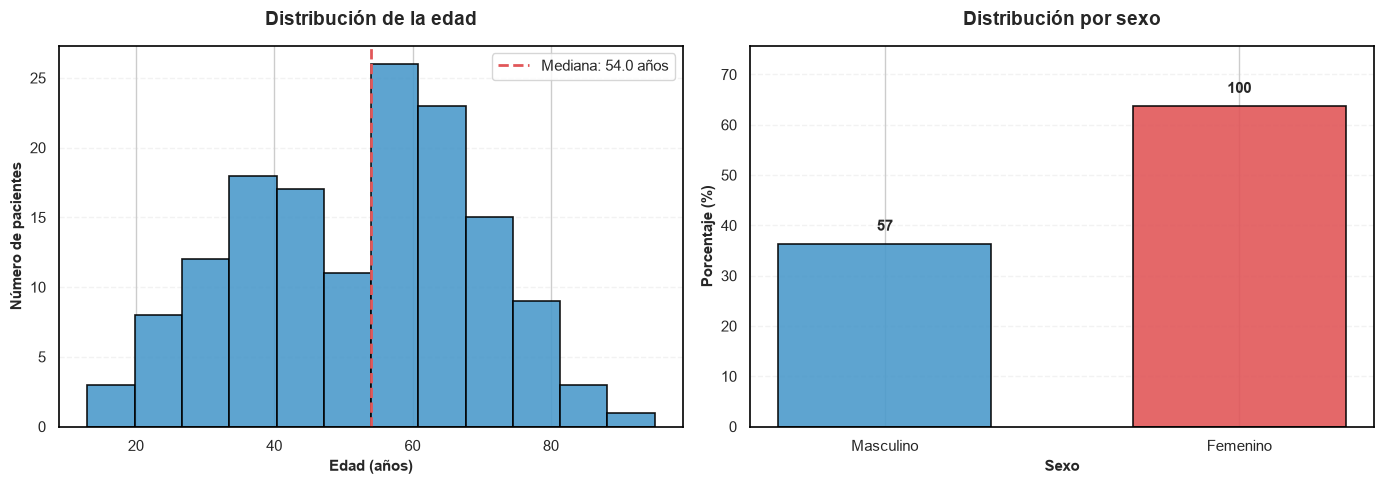

In [10]:
df_spyglass["SEXO"] = (
    df_spyglass["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_spyglass["EDAD"].dropna(),
    bins=12,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

axes[0].axvline(
    df_spyglass["EDAD"].median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {df_spyglass['EDAD'].median():.1f} años"
)

axes[0].set_title(
    "Distribución de la edad",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Edad (años)",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)
axes[0].legend()

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

sexo_counts = df_spyglass["SEXO"].value_counts()
sexo_percentages = sexo_counts / sexo_counts.sum() * 100

orden_sexo = ["MASCULINO", "FEMENINO"]
sexo_counts = sexo_counts.reindex(orden_sexo).dropna()
sexo_percentages = sexo_percentages.reindex(sexo_counts.index)

labels_sexo = [
    "Masculino" if sexo == "MASCULINO" else "Femenino"
    for sexo in sexo_counts.index
]

colors = ["#4C9ACB", "#E15759"]

bars = axes[1].bar(
    labels_sexo,
    sexo_percentages.values,
    color=colors,
    edgecolor="black",
    linewidth=1.2,
    width=0.6,
    alpha=0.9
)

for bar, count in zip(bars, sexo_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

axes[1].set_title(
    "Distribución por sexo",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Sexo",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Porcentaje (%)",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(
    0,
    max(sexo_percentages.values) + 12
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La distribución de la edad se concentra principalmente en pacientes adultos y no presenta una asimetría marcada, lo que también se refleja en la cercanía entre la media y la mediana. En cuanto al sexo, se observa una mayor proporción de mujeres: 100 de los 157 pacientes (63,7%) son de sexo femenino, frente a 57 (36,3%) de sexo masculino.

### 2.2. Procedencia de los pacientes

La procedencia permite conocer el origen geográfico de los pacientes incluidos en la cohorte. Para obtener una primera visión de esta distribución, se analiza el departamento registrado para cada paciente y posteriormente se revisan las principales ciudades o municipios de procedencia.

In [14]:
df_spyglass["DEPARTAMENTO"] = (
    df_spyglass["DEPARTAMENTO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

departamentos = (
    df_spyglass["DEPARTAMENTO"]
    .value_counts()
    .rename_axis("Departamento")
    .reset_index(name="Frecuencia")
)

departamentos["Porcentaje (%)"] = (
    departamentos["Frecuencia"] / departamentos["Frecuencia"].sum() * 100
)

styled_departamentos = (
    departamentos.style
    .hide(axis="index")
    .format({
        "Frecuencia": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(styled_departamentos)

Departamento,Frecuencia,Porcentaje (%)
ATLANTICO,84,53.5%
GUAJIRA,40,25.5%
BOLIVAR,13,8.3%
MAGDALENA,10,6.4%
CESAR,8,5.1%
BARRANQUILLA,1,0.6%
SUCRE,1,0.6%


La procedencia de los pacientes se concentra principalmente en la región Caribe. Más de la mitad de la cohorte proviene del departamento del Atlántico, seguido por La Guajira, mientras que Bolívar, Magdalena, Cesar y Sucre presentan una participación menor. Aunque la Clínica de la Costa se encuentra en Barranquilla, la presencia de pacientes procedentes de distintos departamentos muestra que la cohorte no está conformada únicamente por pacientes del Atlántico.

La procedencia de los pacientes se analiza tanto a nivel departamental como por lugar específico de origen. Esta comparación permite observar la concentración geográfica de la cohorte e identificar las principales zonas desde las cuales provienen los pacientes atendidos.

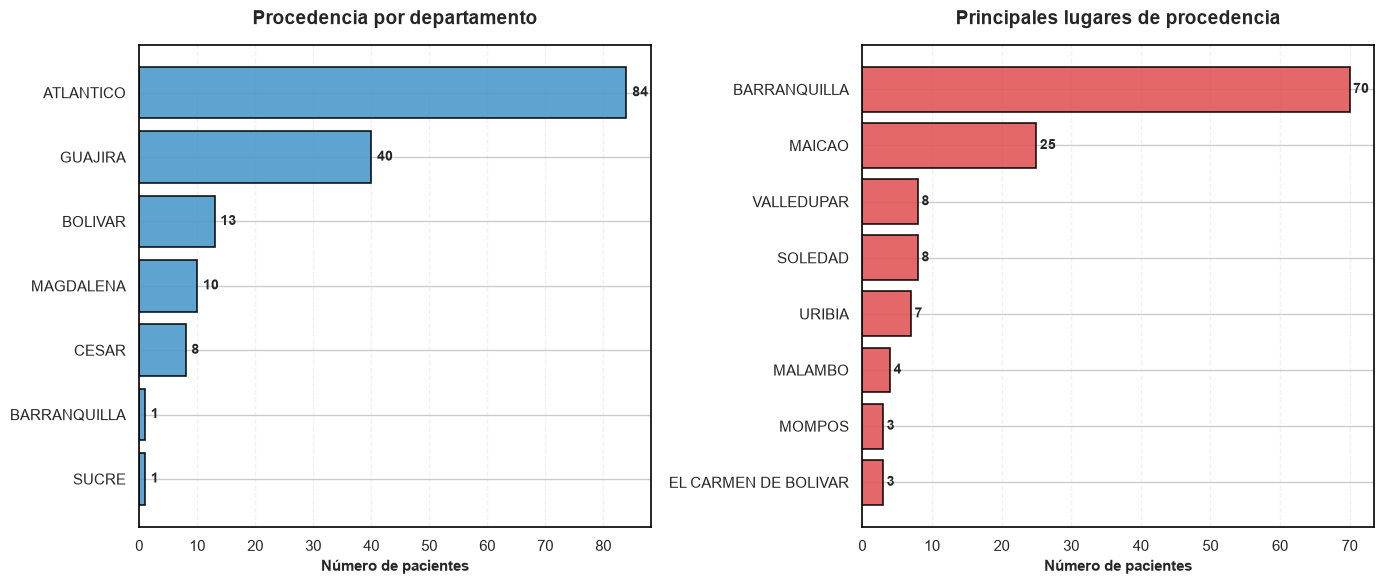

In [12]:
df_spyglass["PROCEDENCIA"] = (
    df_spyglass["PROCEDENCIA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

departamentos_plot = (
    df_spyglass["DEPARTAMENTO"]
    .value_counts()
    .sort_values(ascending=True)
)

procedencias_plot = (
    df_spyglass["PROCEDENCIA"]
    .value_counts()
    .head(8)
    .sort_values(ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bars_1 = axes[0].barh(
    departamentos_plot.index,
    departamentos_plot.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars_1, departamentos_plot.values):
    axes[0].text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title(
    "Procedencia por departamento",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel("")

axes[0].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

bars_2 = axes[1].barh(
    procedencias_plot.index,
    procedencias_plot.values,
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars_2, procedencias_plot.values):
    axes[1].text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "Principales lugares de procedencia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel("")

axes[1].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayor parte de los pacientes proviene del Atlántico, con 85 registros, seguido por La Guajira con 40. A nivel de ciudades y municipios, Barranquilla concentra 70 pacientes y Maicao 25, mientras que el resto de las procedencias presenta frecuencias considerablemente menores. En conjunto, se observa una concentración importante de pacientes provenientes del Atlántico y La Guajira, aunque la cohorte incluye registros de distintos departamentos de la región Caribe.


### 2.3. Endoscopista y antecedente de colecistectomía

--- TABLA 1: DISTRIBUCIÓN DE ENDOSCOPISTAS ---


Endoscopista,Frecuencia (n),Porcentaje (%)
VILLEGAS SANGUINO ALBERTO ANTONIO,92,58.6%
PEREZ OROZCO JESUS MARIA,63,40.1%
FORTI SOSA NESTOR,1,0.6%
AROCA MEJIA ALBERTO MARIO,1,0.6%



--- TABLA 2: ANTECEDENTE DE COLECISTECTOMÍA ---


Estado / Antecedente,Frecuencia (n),Porcentaje (%)
NO,93,59.2%
SI,52,33.1%
,11,7.0%
NO DESCRIBE,1,0.6%


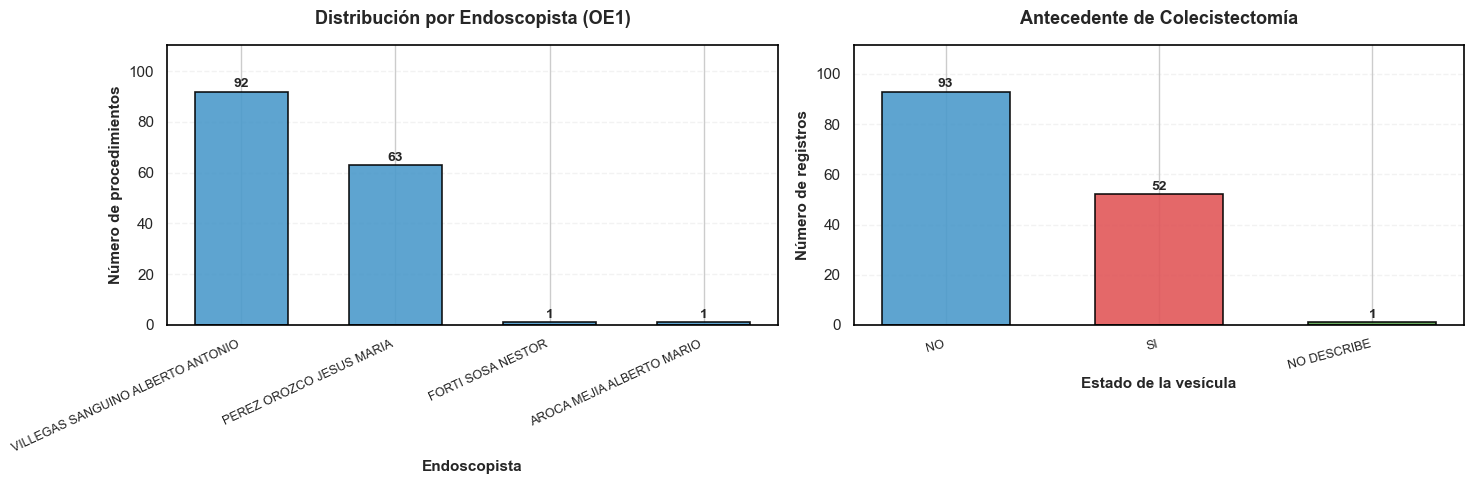

In [17]:
COL_ENDOSCOPISTA = encontrar_columna(df_spyglass, ["ENDOSCOPISTA"])
COL_COLECISTECTOMIA = encontrar_columna(
    df_spyglass, ["ESTADO VESICULA / ANTECEDENTE DE COLECISTECTOMIA"]
)

df_spyglass[COL_ENDOSCOPISTA] = (
    df_spyglass[COL_ENDOSCOPISTA]
    .astype("string")
    .str.strip()
)

df_spyglass[COL_COLECISTECTOMIA] = (
    df_spyglass[COL_COLECISTECTOMIA]
    .astype("string")
    .str.strip()
    .str.upper()
)

def resumen_frecuencias(df, columna, etiqueta):
    df_resumen = (
        df[columna]
        .value_counts(dropna=False)
        .reset_index()
    )

    df_resumen.columns = [etiqueta, "Frecuencia (n)"]

    df_resumen["Porcentaje (%)"] = (
        df_resumen["Frecuencia (n)"] / len(df) * 100
    )

    return df_resumen


def formato_tabla(df, columna_texto):
    return (
        df.style
        .hide(axis="index")
        .format({
            "Frecuencia (n)": "{:.0f}",
            "Porcentaje (%)": "{:.1f}%"
        })
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("margin", "0 auto"),
                    ("width", "auto"),
                    ("border-collapse", "collapse")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("text-align", "center"),
                    ("background-color", "#f2f2f2"),
                    ("color", "black"),
                    ("font-weight", "bold"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            }
        ])
        .set_properties(
            subset=[columna_texto],
            **{"text-align": "left"}
        )
    )


print("--- TABLA 1: DISTRIBUCIÓN DE ENDOSCOPISTAS ---")

tabla_endoscopistas = resumen_frecuencias(
    df_spyglass,
    COL_ENDOSCOPISTA,
    "Endoscopista"
)

display(
    formato_tabla(tabla_endoscopistas, "Endoscopista")
)


print("\n--- TABLA 2: ANTECEDENTE DE COLECISTECTOMÍA ---")

tabla_colecistectomia = resumen_frecuencias(
    df_spyglass,
    COL_COLECISTECTOMIA,
    "Estado / Antecedente"
)

display(
    formato_tabla(tabla_colecistectomia, "Estado / Antecedente")
)


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

endo_counts = df_spyglass[COL_ENDOSCOPISTA].value_counts()

bars0 = axes[0].bar(
    range(len(endo_counts)),
    endo_counts.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    width=0.6,
    alpha=0.9
)

for bar, count in zip(bars0, endo_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_xticks(range(len(endo_counts)))
axes[0].set_xticklabels(
    endo_counts.index,
    rotation=25,
    ha="right",
    fontsize=9
)

axes[0].set_title(
    "Distribución por Endoscopista (OE1)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Endoscopista", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Número de procedimientos", fontsize=11, fontweight="bold")
axes[0].set_ylim(0, max(endo_counts.values) * 1.20)
axes[0].grid(axis="y", linestyle="--", alpha=0.25)
axes[0].set_axisbelow(True)

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)


cole_counts = df_spyglass[COL_COLECISTECTOMIA].value_counts()

colors_cole = ["#4C9ACB", "#E15759", "#59A14F"][:len(cole_counts)]

bars1 = axes[1].bar(
    range(len(cole_counts)),
    cole_counts.values,
    color=colors_cole,
    edgecolor="black",
    linewidth=1.2,
    width=0.6,
    alpha=0.9
)

for bar, count in zip(bars1, cole_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_xticks(range(len(cole_counts)))
axes[1].set_xticklabels(
    cole_counts.index,
    rotation=15,
    ha="right",
    fontsize=9
)

axes[1].set_title(
    "Antecedente de Colecistectomía",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Estado de la vesícula", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Número de registros", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, max(cole_counts.values) * 1.20)
axes[1].grid(axis="y", linestyle="--", alpha=0.25)
axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## 3. Contexto clínico: indicaciones del procedimiento (OE2)

Después de caracterizar la cohorte, se analizan las condiciones clínicas relacionadas con la realización de SpyGlass y las principales características del procedimiento. Esta sección permite conocer los motivos por los cuales los pacientes fueron llevados a colangioscopía y describir cómo se desarrollaron los procedimientos registrados.

### 3.1. Indicaciones del procedimiento

La base de datos diferencia entre una indicación principal y una indicación secundaria para la realización de SpyGlass. Debido a que las indicaciones principales se encuentran registradas como texto libre, una misma condición clínica puede aparecer descrita de diferentes formas.

Para facilitar su análisis, se conserva el registro original y se agrupan las indicaciones en categorías clínicas generales. Estas categorías no son mutuamente excluyentes, ya que un mismo paciente puede presentar más de una condición, por lo que sus porcentajes no necesariamente suman 100%.

In [18]:
def clasificar_indicacion(valor):
    if pd.isna(valor):
        return "Sin registro"

    texto = str(valor).upper()
    texto = " ".join(texto.split())

    if any(palabra in texto for palabra in [
        "FISTULA",
        "FÍSTULA",
        "FUGA BILIAR"
    ]):
        return "Fístula / fuga biliar"

    if any(palabra in texto for palabra in [
        "HEPATOLITIASIS",
        "LITIASIS INTRAHEPATICA",
        "LITIASIS INTRAHEPÁTICA"
    ]):
        return "Hepatolitiasis / litiasis intrahepática"

    if "ESTENOSIS" in texto:
        return "Estenosis"

    if any(palabra in texto for palabra in [
        "COLANGIOCARCINOMA",
        "NEOPLAS",
        "TUMOR",
        "LESION",
        "LESIÓN",
        "AMPULOMA"
    ]):
        return "Lesión o neoplasia"

    if any(palabra in texto for palabra in [
        "COLEDOCOLITIASIS",
        "COLEDOCOLITASIS",
        "COLEDEOCOLITIASIS",
        "OLEDOCOLITIASIS",
        "COLEDOCOLITISIS",
        "CALCULOS EN COLEDOCO",
        "CÁLCULOS EN COLÉDOCO",
        "CALCULO GRANDE EN COLEDOCO"
    ]):
        return "Coledocolitiasis"

    return "Otras"


df_spyglass["INDICACION_AGRUPADA"] = (
    df_spyglass["INDICACIÓN PRINCIPAL"]
    .apply(clasificar_indicacion)
)

resumen_indicaciones = (
    df_spyglass["INDICACION_AGRUPADA"]
    .value_counts()
    .rename_axis("Indicación")
    .reset_index(name="Registros")
)

resumen_indicaciones["Porcentaje (%)"] = (
    resumen_indicaciones["Registros"]
    / len(df_spyglass)
    * 100
)

styled_indicaciones = (
    resumen_indicaciones.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Indicación"],
        **{"text-align": "left"}
    )
)

display(styled_indicaciones)

Indicación,Registros,Porcentaje (%)
Coledocolitiasis,81,51.6%
Hepatolitiasis / litiasis intrahepática,20,12.7%
Lesión o neoplasia,19,12.1%
Estenosis,15,9.6%
Sin registro,11,7.0%
Otras,8,5.1%
Fístula / fuga biliar,3,1.9%


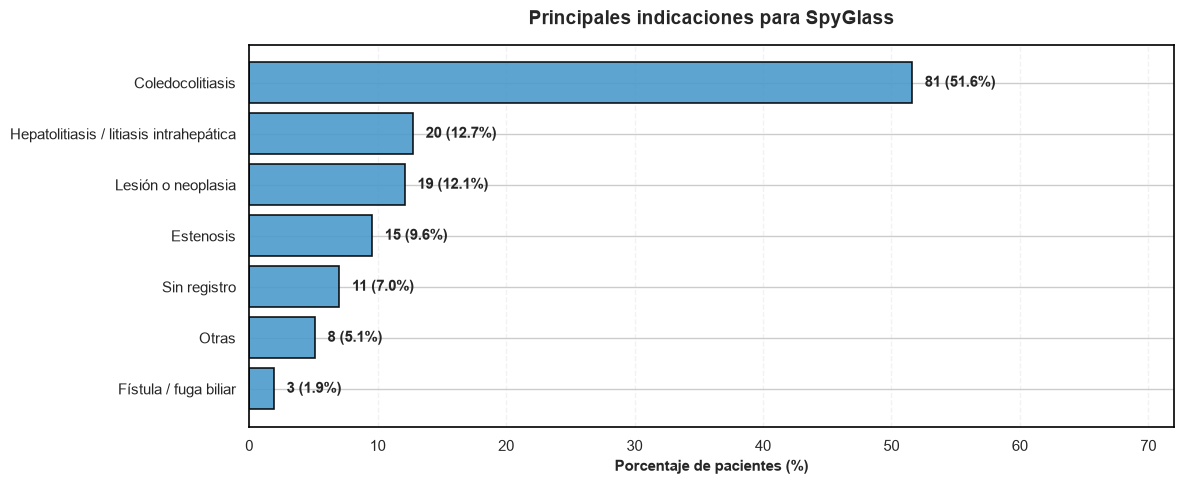

In [15]:
resumen_indicaciones_plot = resumen_indicaciones.sort_values(
    "Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.barh(
    resumen_indicaciones_plot["Indicación"],
    resumen_indicaciones_plot["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, count, percentage in zip(
    bars,
    resumen_indicaciones_plot["Pacientes"],
    resumen_indicaciones_plot["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Principales indicaciones para SpyGlass",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de pacientes (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

ax.set_xlim(0, 72)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La coledocolitiasis es la indicación predominante, presente en 81 de los 146 pacientes con información disponible (51,6%). Con una frecuencia considerablemente menor aparecen las lesiones o neoplasias y las estenosis, ambas identificadas en 20 pacientes (12,7%), seguidas por la hepatolitiasis o litiasis intrahepática en 19 (12,1%). Las fístulas o fugas biliares son poco frecuentes, con 3 casos (1,9%).

La diferencia entre la coledocolitiasis y el resto de las indicaciones muestra que las condiciones relacionadas con cálculos tienen un peso importante dentro de la cohorte. Debido a que las categorías pueden presentarse simultáneamente en un mismo paciente, estas frecuencias deben interpretarse como presencia de cada condición y no como grupos independientes.


### 3.2. Clasificación cálculo vs. estenosis

Tipo de indicación,Registros,Porcentaje (%)
Cálculo,103,65.6%
Estenosis,32,20.4%
nan,11,7.0%
Otra,8,5.1%
Mixta — revisar manualmente,2,1.3%
Fuera de alcance (esofágico),1,0.6%


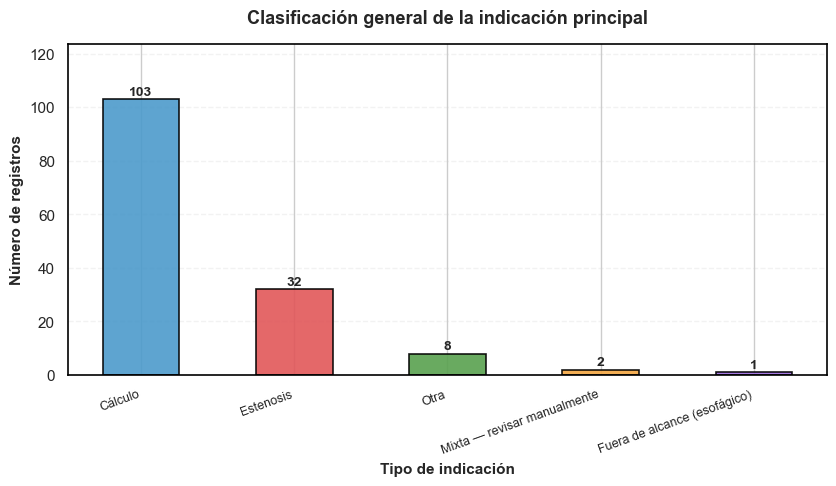

In [19]:
PALABRAS_CALCULO = [
    "COLEDOCOLITIASIS", "COLEDOCOLITASIS", "COLEDOCOLITISIS",
    "LITIASIS", "COLELITIASIS", "CALCULO", "CALCULOS"
]

PALABRAS_ESTENOSIS_MASA = [
    "ESTENOSIS", "TUMOR", "KLATSKIN", "COLANGIOCARCINOMA",
    "MIRIZZI", "FISTULA", "FÍSTULA", "LESION ESTENOSANTE",
    "LESIÓN ESTENOSANTE", "OCLUSION", "OCLUSIÓN", "MASA"
]

PALABRAS_EXCLUIR_ESTENOSIS = [
    "ESOFAGICA", "ESOFÁGICA"
]

def clasificar_tipo_indicacion_v2(valor):
    if pd.isna(valor):
        return np.nan

    v = str(valor).upper()

    if any(p in v for p in PALABRAS_EXCLUIR_ESTENOSIS):
        return "Fuera de alcance (esofágico)"

    tiene_calculo = any(p in v for p in PALABRAS_CALCULO)
    tiene_estenosis = any(p in v for p in PALABRAS_ESTENOSIS_MASA)

    if tiene_calculo and tiene_estenosis:
        return "Mixta — revisar manualmente"

    if tiene_calculo:
        return "Cálculo"

    if tiene_estenosis:
        return "Estenosis"

    return "Otra"


COL_INDICACION = encontrar_columna(
    df_spyglass,
    ["INDICACION PRINCIPAL"]
)

df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"] = (
    df_spyglass[COL_INDICACION]
    .apply(clasificar_tipo_indicacion_v2)
)

resumen_tipo = (
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"]
    .value_counts(dropna=False)
    .rename_axis("Tipo de indicación")
    .reset_index(name="Registros")
)

resumen_tipo["Porcentaje (%)"] = (
    resumen_tipo["Registros"]
    / len(df_spyglass)
    * 100
)

styled_tipo = (
    resumen_tipo.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Tipo de indicación"],
        **{"text-align": "left"}
    )
)

display(styled_tipo)


tipo_counts = (
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"]
    .value_counts()
)

fig, ax = plt.subplots(figsize=(9, 5.5))

colors_tipo = [
    "#4C9ACB",
    "#E15759",
    "#59A14F",
    "#F2A541",
    "#9C6ADE"
][:len(tipo_counts)]

bars = ax.bar(
    range(len(tipo_counts)),
    tipo_counts.values,
    color=colors_tipo,
    edgecolor="black",
    linewidth=1.2,
    width=0.5,
    alpha=0.9
)

for bar, count in zip(bars, tipo_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks(range(len(tipo_counts)))

ax.set_xticklabels(
    tipo_counts.index,
    rotation=20,
    ha="right",
    fontsize=9
)

ax.set_title(
    "Clasificación general de la indicación principal",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Tipo de indicación",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Número de registros",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylim(
    0,
    max(tipo_counts.values) * 1.20
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout(pad=2.5)
plt.show()

## 4. Hallazgos colangioscópicos (OE3)

La visualización directa mediante SpyGlass permite registrar diferentes características de las lesiones observadas durante el procedimiento. En esta sección se describe la frecuencia de los principales hallazgos colangioscópicos disponibles en la base de datos, como paso previo al análisis de su relación con los resultados histopatológicos.

### 4.1. Frecuencia de hallazgos en la cohorte total

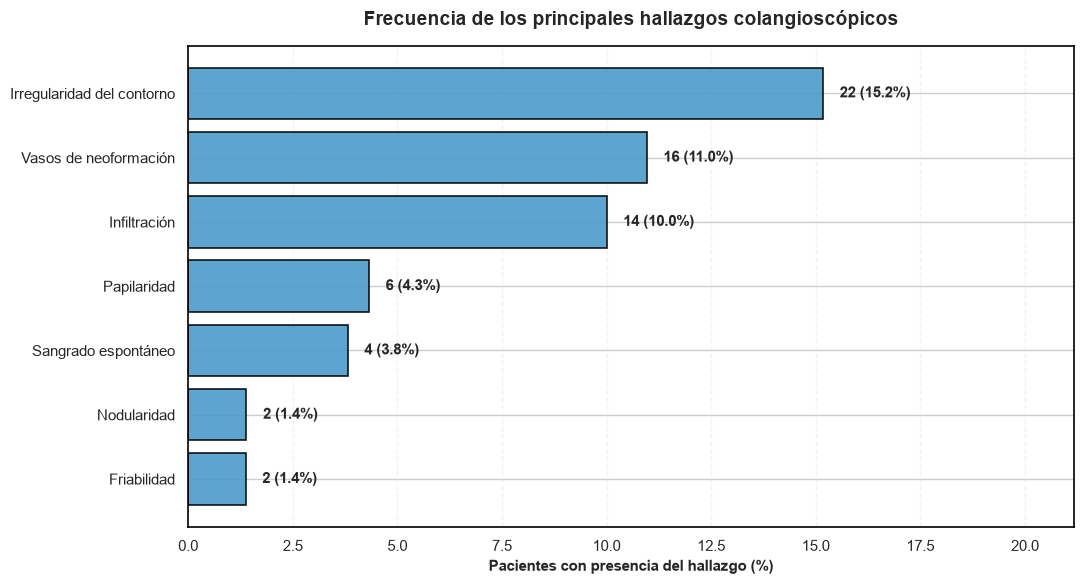

In [17]:
resumen_hallazgos = []

nombres_hallazgos = {
    "PAPILARIDAD": "Papilaridad",
    "NODULARIDAD": "Nodularidad",
    "IRREGULARIDAD DEL CONTORNO": "Irregularidad del contorno",
    "FRIABILIDAD": "Friabilidad",
    "VASOS DE NEOFORMACION": "Vasos de neoformación",
    "INFILTRACION": "Infiltración",
    "SANGRADO ESPONTANEO": "Sangrado espontáneo"
}

for variable in nombres_hallazgos:
    respuestas_validas = df_spyglass[variable].isin(["SI", "NO"])
    n_validos = respuestas_validas.sum()
    n_si = (df_spyglass.loc[respuestas_validas, variable] == "SI").sum()

    resumen_hallazgos.append({
        "Hallazgo": nombres_hallazgos[variable],
        "Pacientes": n_si,
        "Porcentaje (%)": n_si / n_validos * 100
    })

resumen_hallazgos = (
    pd.DataFrame(resumen_hallazgos)
    .sort_values("Porcentaje (%)", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    resumen_hallazgos["Hallazgo"],
    resumen_hallazgos["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, count, percentage in zip(
    bars,
    resumen_hallazgos["Pacientes"],
    resumen_hallazgos["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Frecuencia de los principales hallazgos colangioscópicos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Pacientes con presencia del hallazgo (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    resumen_hallazgos["Porcentaje (%)"].max() + 6
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()


La irregularidad del contorno es el hallazgo colangioscópico positivo más frecuente, presente en 22 pacientes (15,2%), seguida por los vasos de neoformación en 16 (11,0%) y la infiltración en 14 (10%). Los demás hallazgos presentan frecuencias menores: papilaridad se identifica en 6 pacientes (4,3%), sangrado espontáneo en 4 (3,8%), y tanto friabilidad como nodularidad en 2 pacientes (1,4%) cada una.

En general, ninguno de los hallazgos evaluados aparece en una proporción mayor al 16% de los registros con información válida. Sin embargo, su baja frecuencia no determina por sí sola su relevancia clínica, por lo que posteriormente resulta de interés evaluar si alguno de estos hallazgos se relaciona con el resultado histopatológico.

### 4.2. Auditoría del denominador según tipo de indicación

In [20]:
NOMBRES_HALLAZGOS = {
    "PAPILARIDAD": "Papilaridad",
    "NODULARIDAD": "Nodularidad",
    "IRREGULARIDAD DEL CONTORNO": "Irregularidad del contorno",
    "FRIABILIDAD": "Friabilidad",
    "VASOS DE NEOFORMACION": "Vasos de neoformación",
    "INFILTRACION": "Infiltración",
    "SANGRADO ESPONTANEO": "Sangrado espontáneo"
}

for col_hallazgo, nombre_hallazgo in NOMBRES_HALLAZGOS.items():

    tabla_cruce = pd.crosstab(
        df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"],
        df_spyglass[col_hallazgo]
    )

    tabla_cruce.index.name = "Tipo de indicación"
    tabla_cruce.columns.name = None

    tabla_cruce = tabla_cruce.reset_index()

    columnas_numericas = tabla_cruce.columns.drop("Tipo de indicación").tolist()

    styled_cruce = (
        tabla_cruce.style
        .hide(axis="index")
        .format({
            columna: "{:.0f}"
            for columna in columnas_numericas
        })
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("margin", "0 auto"),
                    ("width", "auto"),
                    ("border-collapse", "collapse")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("text-align", "center"),
                    ("background-color", "#f2f2f2"),
                    ("color", "black"),
                    ("font-weight", "bold"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            }
        ])
        .set_properties(
            subset=["Tipo de indicación"],
            **{"text-align": "left"}
        )
    )

    print(f"\n{nombre_hallazgo} × tipo de indicación")

    display(styled_cruce)


Papilaridad × tipo de indicación


Tipo de indicación,NO,NO,SI
Cálculo,95,6,2
Estenosis,28,1,3
Fuera de alcance (esofágico),1,0,0
Mixta — revisar manualmente,2,0,0
Otra,7,0,1



Nodularidad × tipo de indicación


Tipo de indicación,NO,NO,SI
Cálculo,101,1,1
Estenosis,30,1,1
Fuera de alcance (esofágico),1,0,0
Mixta — revisar manualmente,2,0,0
Otra,8,0,0



Irregularidad del contorno × tipo de indicación


...

Tipo de indicación,NO,SI
Cálculo,103,0
Estenosis,20,12
Fuera de alcance (esofágico),1,0
Mixta — revisar manualmente,2,0
Otra,4,4



Infiltración × tipo de indicación


Tipo de indicación,NO,NO,SI
Cálculo,97,6,0
Estenosis,19,0,13
Fuera de alcance (esofágico),1,0,0
Mixta — revisar manualmente,2,0,0
Otra,7,0,1



Sangrado espontáneo × tipo de indicación


Tipo de indicación,NO,NO,SI
Cálculo,68,35,0
Estenosis,25,5,2
Fuera de alcance (esofágico),1,0,0
Mixta — revisar manualmente,1,1,0
Otra,6,0,2


La auditoría del denominador evidencia un solapamiento clínico relevante: características visuales como la papilaridad y la irregularidad del contorno se presentan con frecuencia en pacientes cuya indicación primaria fue litiásica ($n=52$ para papilaridad). Esto refleja los cambios inflamatorios reactivos inducidos por la fricción crónica del lito, subrayando la necesidad de interpretar los hallazgos endoscópicos en conjunto con la histología (biopsias) y no basarse exclusivamente en la impresión visual inicial.

### 4.3. Hallazgos en el subgrupo con estenosis

In [21]:
casos_mixtos = df_spyglass.loc[
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"] == "Mixta — revisar manualmente",
    ["ID", COL_INDICACION]
]

styled_mixtos = (
    casos_mixtos.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=[COL_INDICACION],
        **{"text-align": "left"}
    )
)

print("Registros con indicación mixta para revisión manual:")
display(styled_mixtos)


subgrupo_estenosis = df_spyglass[
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"] == "Estenosis"
].copy()

print(
    f"\nRegistros con indicación de estenosis "
    f"(clasificación corregida): {len(subgrupo_estenosis)}"
)

resumen_hallazgos_corregido = []

for col_hallazgo, etiqueta in NOMBRES_HALLAZGOS.items():

    validos = subgrupo_estenosis[col_hallazgo].isin(["SI", "NO"])

    n_validos = validos.sum()

    n_si = (
        subgrupo_estenosis.loc[validos, col_hallazgo] == "SI"
    ).sum()

    resumen_hallazgos_corregido.append({
        "Hallazgo": etiqueta,
        "Registros evaluables": n_validos,
        "Con hallazgo (SI)": n_si,
        "Porcentaje (%)": (
            n_si / n_validos * 100
            if n_validos else np.nan
        )
    })

tabla_hallazgos_corregida = pd.DataFrame(
    resumen_hallazgos_corregido
)

styled_hallazgos = (
    tabla_hallazgos_corregida.style
    .hide(axis="index")
    .format({
        "Registros evaluables": "{:.0f}",
        "Con hallazgo (SI)": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Hallazgo"],
        **{"text-align": "left"}
    )
)

print("\nFrecuencia de hallazgos endoscópicos en el subgrupo de estenosis:")
display(styled_hallazgos)

Registros con indicación mixta para revisión manual:


ID,INDICACIÓN PRINCIPAL
55,LITIASIS INTRAHEPATICA Y COLEDOCOLITIASIS Y ESTENOSIS DE LA VIA BILIAR PRINCIPAL
140,COLEDOCOLITIASIS VS MASA



Registros con indicación de estenosis (clasificación corregida): 32

Frecuencia de hallazgos endoscópicos en el subgrupo de estenosis:


Hallazgo,Registros evaluables,Con hallazgo (SI),Porcentaje (%)
Papilaridad,31,3,9.7%
Nodularidad,31,1,3.2%
Irregularidad del contorno,32,14,43.8%
Friabilidad,32,2,6.2%
Vasos de neoformación,32,12,37.5%
Infiltración,32,13,40.6%
Sangrado espontáneo,27,2,7.4%


Para el análisis detallado de los hallazgos colangioscópicos en el subgrupo de **estenosis**, se aplicaron los siguientes criterios de depuración y control de calidad:

* **Exclusión de casos con indicaciones mixtas:** Se identificaron y excluyeron explícitamente 2 casos con registros híbridos o ambiguos que no permitían una clasificación binaria estricta:
  * **ID 55:** Indicación registrada como *"Litiasis intrahepática y colecolitiasis y estenosis..."* (texto truncado).
  * **ID 140:** Indicación registrada como *"Coledocolitiasis vs. masa"* (hipótesis diferencial pre-procedimiento y no una estenosis confirmada).
* **Criterio metodológico:** Se optó por su exclusión explícita en lugar de forzar su asignación a una categoría, garantizando la pureza del denominador clínico de la cohorte analizada.


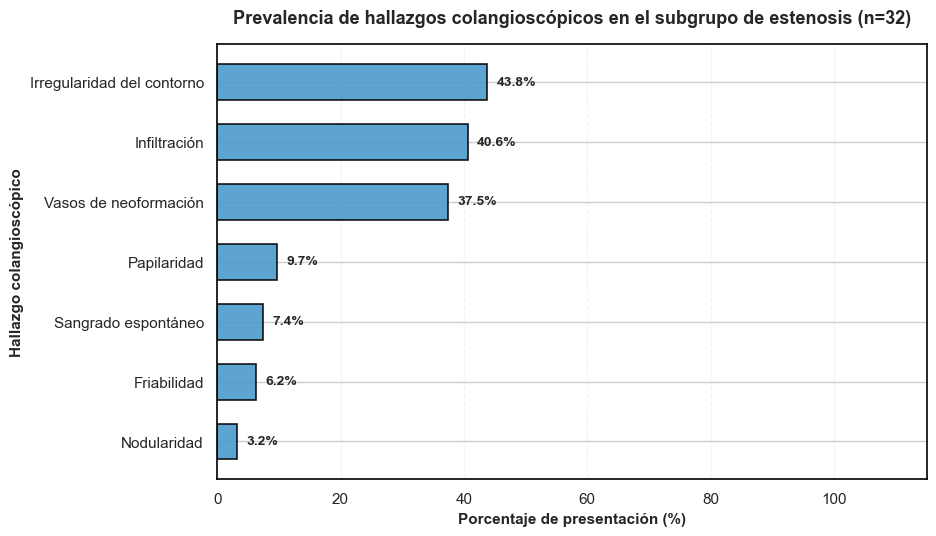

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = tabla_hallazgos_corregida.sort_values(
    by="Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    df_plot["Hallazgo"],
    df_plot["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    height=0.6,
    alpha=0.9
)

for bar in bars:
    width = bar.get_width()

    if pd.notna(width):
        ax.text(
            width + 1.5,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

ax.set_title(
    f"Prevalencia de hallazgos colangioscópicos en el subgrupo de estenosis (n={len(subgrupo_estenosis)})",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de presentación (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Hallazgo colangioscópico",
    fontsize=11,
    fontweight="bold"
)

ax.set_xlim(0, 115)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout(pad=2.5)
plt.show()

El análisis de frecuencia sobre el subgrupo depurado refleja la proporción de pacientes que presentan cada criterio visual bajo visión directa por SpyGlass:

* **Denominador variable ($n$ evaluable):** Se observa una variación en el número de pacientes evaluables por cada hallazgo específico (oscilando entre $n = 27$ y $n = 32$), debido a la disponibilidad de registro individual en la historia clínica para cada variable morfológica.
* **Prevalencia destacada:**
  * La **irregularidad del contorno** se posiciona como el hallazgo más frecuente en la cohorte, presente en el **43.8%** de los casos evaluados ($n=14/32$).
  * La **infiltración** y la **papilaridad** también muestran una alta representación con un **40.6%** ($n=13/32$) y un **9.7%** ($n=3/31$), respectivamente.
  * Por su parte, el **sangrado espontáneo** presenta una de las menores frecuencias relativas dentro del subgrupo (**7.4%**, $n=2/27$).


### 4.4. Co-ocurrencia entre hallazgos (subgrupo con estenosis)

In [26]:
datos_binarios = subgrupo_estenosis[
    list(NOMBRES_HALLAZGOS.keys())
].apply(
    lambda s: (s == "SI").astype(int)
)

datos_binarios.columns = list(NOMBRES_HALLAZGOS.values())

matriz_coocurrencia = datos_binarios.corr(method="pearson")

styled_coocurrencia = (
    matriz_coocurrencia.style
    .format("{:.2f}", na_rep="—")
    .background_gradient(
        cmap="Blues",
        vmin=-1,
        vmax=1,
        axis=None
    )
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "th.row_heading",
            "props": [
                ("text-align", "left")
            ]
        }
    ])
)

display(styled_coocurrencia)

,Papilaridad,Nodularidad,Irregularidad del contorno,Friabilidad,Vasos de neoformación,Infiltración,Sangrado espontáneo
Papilaridad,1.00,-0.06,0.15,-0.08,0.19,0.17,-0.08
Nodularidad,-0.06,1.00,0.20,-0.05,0.23,0.22,-0.05
Irregularidad del contorno,0.15,0.20,1.00,0.29,0.36,0.42,0.03
Friabilidad,-0.08,-0.05,0.29,1.00,-0.20,0.05,-0.07
Vasos de neoformación,0.19,0.23,0.36,-0.20,1.00,0.41,0.07
Infiltración,0.17,0.22,0.42,0.05,0.41,1.00,-0.21
Sangrado espontáneo,-0.08,-0.05,0.03,-0.07,0.07,-0.21,1.00


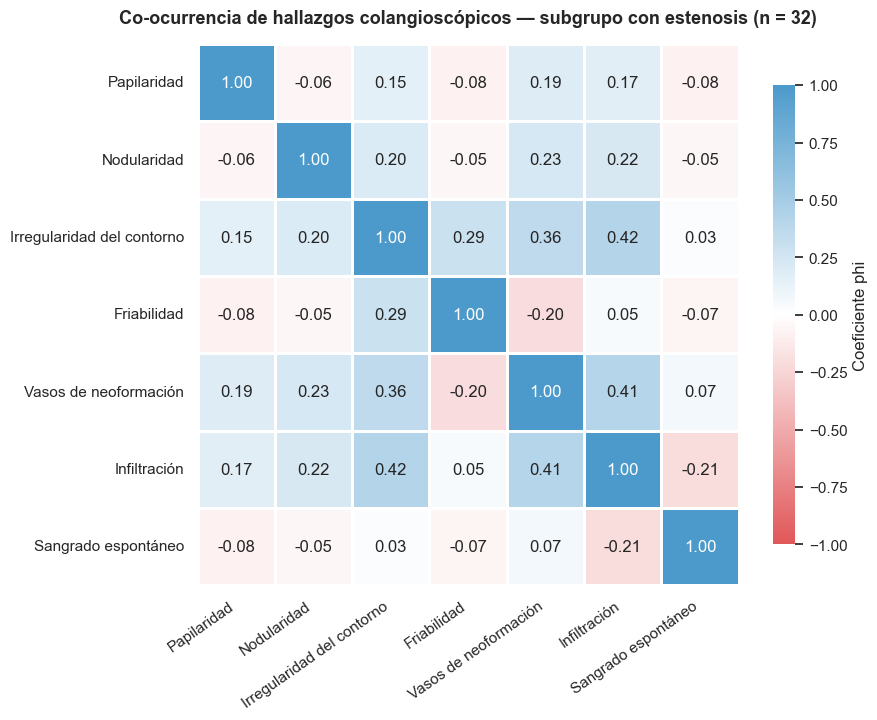

In [27]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    matriz_coocurrencia.round(2),
    annot=True, fmt=".2f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.8, linecolor="white",
    cbar_kws={"label": "Coeficiente phi", "shrink": 0.8}, ax=ax,
)
ax.set_title(
    f"Co-ocurrencia de hallazgos colangioscópicos — subgrupo con estenosis (n = {len(subgrupo_estenosis)})",
    fontsize=13, fontweight="bold", pad=15,
)
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()


Para evaluar la asociación entre los distintos descriptores visuales en las estenosis, se calculó la matriz de correlación utilizando coeficientes Phi (equivalentes a Pearson para variables binarias):

* **Rango de correlación:** Los coeficientes obtenidos oscilan entre valores negativos débiles ($-0.21$ entre sangrado espontáneo e infiltración) y positivos moderados ($0.42$), lo que indica asociaciones de intensidad variable entre los hallazgos evaluados.

* **Asociaciones entre signos morfológicos:** Las asociaciones positivas más fuertes se concentran entre los siguientes pares de variables:
  * **Irregularidad del contorno e infiltración ($r = 0.42$):** Indica una asociación positiva moderada entre las alteraciones del contorno y la presencia de signos endoscópicos de infiltración.
  * **Vasos de neoformación e infiltración ($r = 0.41$):** Sugiere una tendencia a la aparición conjunta de alteraciones vasculares y signos infiltrativos.
  * **Irregularidad del contorno y vasos de neoformación ($r = 0.36$):** Evidencia una asociación positiva entre las alteraciones morfológicas del contorno y la presencia de patrones vasculares anormales.


## 4bis. Procedimientos terapéuticos asociados (OE4)

### 4bis.1. Características del procedimiento

A continuación, se describen algunas características relacionadas con la realización del procedimiento, incluyendo la modalidad de atención, el número de procedimientos realizados, el tiempo quirúrgico y el uso de intervenciones complementarias como prótesis biliares o dilatación de la papila.

La mayoría de las variables relacionadas con el procedimiento presentan información para 146 pacientes, con excepción de la modalidad de atención, disponible para toda la cohorte. Para resumir estas características se analiza la modalidad en la que se realizó SpyGlass, el número de procedimientos registrados y el uso de intervenciones complementarias.

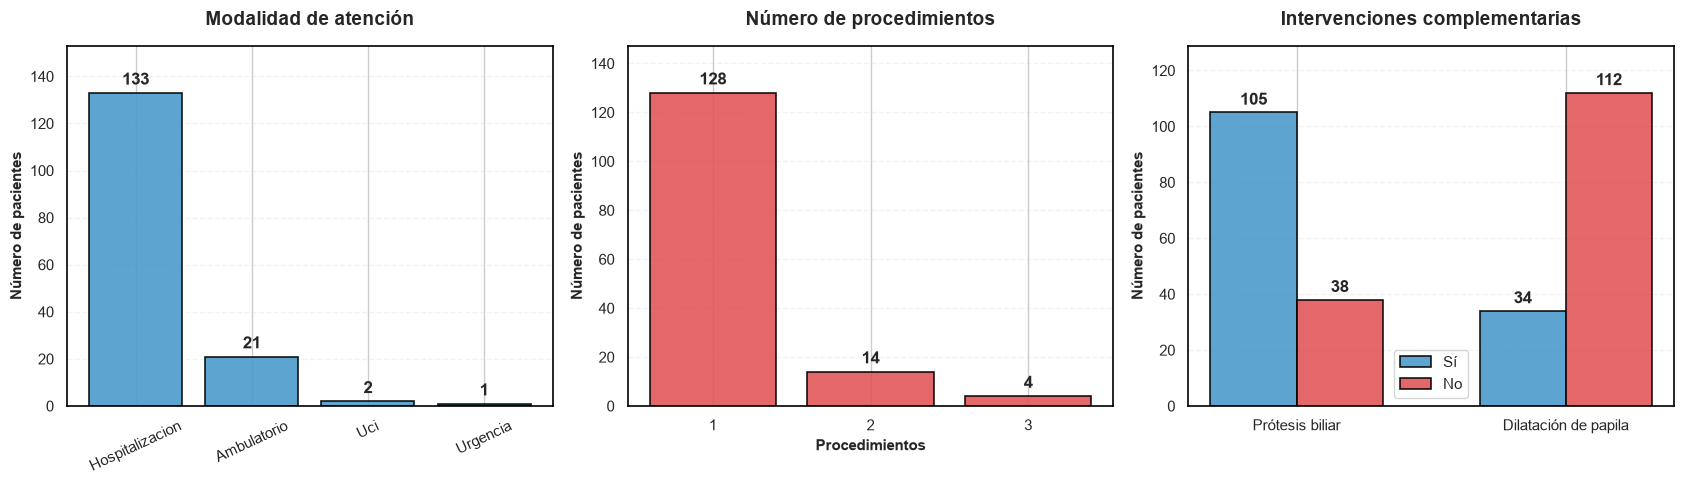

In [23]:
programado = df_spyglass["PROGRAMADO"].value_counts()

numero_procedimientos = (
    pd.to_numeric(
        df_spyglass["NUMERO DE PROCEDIMIENTOS"],
        errors="coerce"
    )
    .value_counts()
    .sort_index()
)

protesis = (
    df_spyglass["USO DE PROTESIS BILIAR"]
    .astype("string")
    .str.strip()
    .str.upper()
)

protesis = protesis.where(
    protesis.isin(["SI", "NO"]),
    "OTRO REGISTRO"
)

protesis = protesis[df_spyglass["USO DE PROTESIS BILIAR"].notna()]

dilatacion = (
    df_spyglass["DILATACION DE PAPILA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

intervenciones = pd.DataFrame({
    "Prótesis biliar": [
        (protesis == "SI").sum(),
        (protesis == "NO").sum()
    ],
    "Dilatación de papila": [
        (dilatacion == "SI").sum(),
        (dilatacion == "NO").sum()
    ]
}, index=["Sí", "No"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

bars = axes[0].bar(
    programado.index.str.title(),
    programado.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, programado.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

axes[0].set_title(
    "Modalidad de atención",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylim(0, programado.max() * 1.15)

bars = axes[1].bar(
    numero_procedimientos.index.astype(int).astype(str),
    numero_procedimientos.values,
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, numero_procedimientos.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

axes[1].set_title(
    "Número de procedimientos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Procedimientos",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(0, numero_procedimientos.max() * 1.15)

x = np.arange(len(intervenciones.columns))
width = 0.32

bars_si = axes[2].bar(
    x - width / 2,
    intervenciones.loc["Sí"],
    width,
    label="Sí",
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

bars_no = axes[2].bar(
    x + width / 2,
    intervenciones.loc["No"],
    width,
    label="No",
    color="#E15759",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

axes[2].bar_label(
    bars_si,
    padding=3,
    fontweight="bold"
)

axes[2].bar_label(
    bars_no,
    padding=3,
    fontweight="bold"
)

axes[2].set_xticks(x)
axes[2].set_xticklabels(intervenciones.columns)

axes[2].set_title(
    "Intervenciones complementarias",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[2].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[2].set_ylim(
    0,
    intervenciones.to_numpy().max() * 1.15
)

axes[2].legend()

for ax in axes:
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayoría de los procedimientos se realizó en pacientes hospitalizados, con 133 de los 157 registros, mientras que la atención ambulatoria fue considerablemente menos frecuente y los procedimientos realizados desde UCI o urgencias fueron aislados.

Entre los 146 pacientes con información disponible sobre el número de procedimientos, 128 registran un solo procedimiento, 14 registran dos y únicamente 4 registran tres. En cuanto a las intervenciones complementarias, el uso de prótesis biliar es frecuente, con 105 registros positivos frente a 38 negativos. La dilatación de papila presenta el comportamiento contrario y se registra en 34 pacientes, mientras que en 112 no se realiza.

En conjunto, la cohorte está compuesta principalmente por pacientes hospitalizados que registran un único procedimiento, con un uso frecuente de prótesis biliar y una menor utilización de dilatación de papila.

> **Nota:** Para el uso de prótesis biliar, la comparación Sí/No incluye 143 registros. Tres observaciones con descripciones diferentes a estas categorías se conservan en la base original y no se incluyen en esta comparación.

### 4bis.2. Tiempo quirúrgico

El tiempo quirúrgico permite describir la duración de los procedimientos realizados. Para esta variable se analiza tanto su distribución como las principales medidas de tendencia central y dispersión.

In [29]:
df_spyglass.columns = (
    df_spyglass.columns
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"] = pd.to_numeric(
    df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"],
    errors="coerce"
)

tiempo = df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"].dropna()

resumen_tiempo = pd.DataFrame({
    "Indicador": [
        "Registros disponibles",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Mínimo",
        "Máximo"
    ],
    "Tiempo (minutos)": [
        tiempo.count(),
        tiempo.mean(),
        tiempo.std(),
        tiempo.median(),
        tiempo.min(),
        tiempo.max()
    ]
})

styled_tiempo = (
    resumen_tiempo.style
    .hide(axis="index")
    .format({
        "Tiempo (minutos)": "{:.1f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
)

display(styled_tiempo)

Indicador,Tiempo (minutos)
Registros disponibles,146.0
Media,50.3
Desviación estándar,21.5
Mediana,50.0
Mínimo,20.0
Máximo,150.0


El tiempo quirúrgico está disponible para 146 pacientes. La duración media del procedimiento es de 50,3 minutos y la mediana de 50 minutos, con una desviación estándar de 21,5 minutos. Los tiempos registrados van desde 20 hasta 150 minutos, lo que muestra que algunos procedimientos tuvieron una duración considerablemente mayor que la habitual en la cohorte.

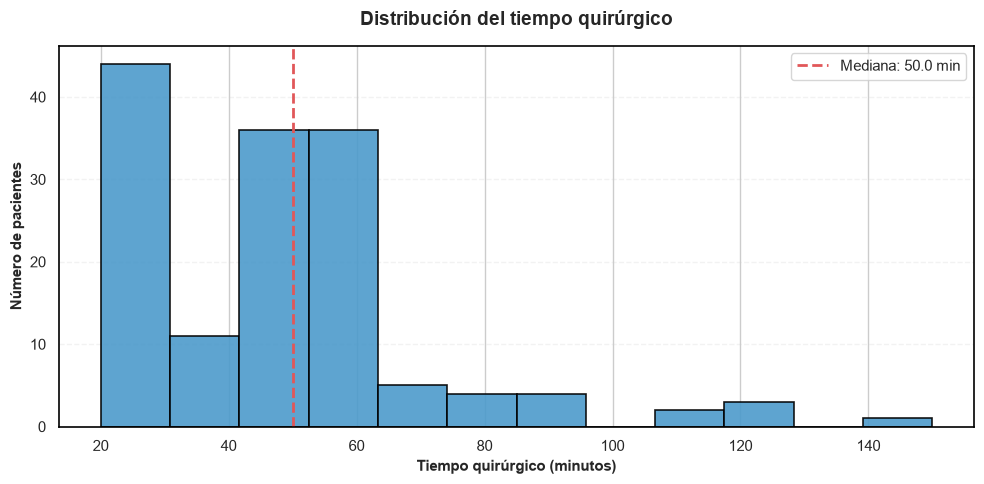

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    tiempo,
    bins=12,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

ax.axvline(
    tiempo.median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {tiempo.median():.1f} min"
)

ax.set_title(
    "Distribución del tiempo quirúrgico",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Tiempo quirúrgico (minutos)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.legend()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La mayor parte de los procedimientos se concentra aproximadamente entre los 20 y 60 minutos. Sin embargo, la distribución presenta una cola hacia tiempos más prolongados, con algunos procedimientos que superan los 100 minutos y un valor máximo de 150 minutos. Estos casos son poco frecuentes, pero amplían considerablemente el rango observado.

### 4bis.3. Uso de prótesis biliar: categorización

In [30]:
COL_PROTESIS = encontrar_columna(df_spyglass, ["USO DE PROTESIS BILIAR"])
COL_PAPILA = encontrar_columna(df_spyglass, ["DILATACION DE PAPILA"])
COL_TIEMPO = encontrar_columna(df_spyglass, ["TIEMPO QUIRURGICO EN MINUTOS"])
COL_NUM_PROCEDIMIENTOS = encontrar_columna(df_spyglass, ["NUMERO DE PROCEDIMIENTOS"])

for nombre, col in [("Prótesis biliar", COL_PROTESIS), ("Dilatación de papila", COL_PAPILA),
                    ("Número de procedimientos", COL_NUM_PROCEDIMIENTOS)]:
    print(f"\n{nombre}:")
    display(df_spyglass[col].value_counts(dropna=False))

resumen_tiempo_qx = df_spyglass[COL_TIEMPO].describe()
print("\nTiempo quirúrgico (minutos) — resumen:")
display(resumen_tiempo_qx)

protesis_cruda = df_spyglass[COL_PROTESIS].astype("string").str.strip().str.upper()

def categorizar_protesis(valor):
    if pd.isna(valor):
        return np.nan
    v = str(valor).upper()
    if "PREVIA" in v:
        return "Previa (preexistente)"
    if "DREN" in v:
        return "Dren percutáneo (no es prótesis biliar de novo)"
    if "PANCREATICA" in v:
        return "Prótesis pancreática (categoría distinta a biliar)"
    if v == "SI":
        return "Sí (de novo)"
    if v == "NO":
        return "No"
    return "Otro registro — revisar"

df_spyglass["USO_PROTESIS_CATEGORIA"] = protesis_cruda.apply(categorizar_protesis)
print("Categorización completa de uso de prótesis:")
display(df_spyglass["USO_PROTESIS_CATEGORIA"].value_counts(dropna=False))

caso_previa = df_spyglass[df_spyglass["USO_PROTESIS_CATEGORIA"] == "Previa (preexistente)"]
print(f"\nCaso(s) 'Previa': n = {len(caso_previa)}")
display(caso_previa[["ID", COL_PROTESIS]])
assert len(caso_previa) == 1, "Se esperaba exactamente 1 caso 'Previa'."

df_spyglass["PROTESIS_DE_NOVO_BINARIA"] = df_spyglass["USO_PROTESIS_CATEGORIA"].map({
    "Sí (de novo)": "SI", "No": "NO",
})
n_excluidos = df_spyglass["USO_PROTESIS_CATEGORIA"].isin(
    ["Previa (preexistente)", "Dren percutáneo (no es prótesis biliar de novo)",
     "Prótesis pancreática (categoría distinta a biliar)"]
).sum()
print(f"Pacientes excluidos de la prueba binaria de novo (documentado): {n_excluidos}")


Prótesis biliar:


USO DE PROTESIS BILIAR
SI                                 105
NO                                  38
NaN                                 11
PREVIA                               1
DREN PERCUTANEO A LIBRE DRENAJE      1
SI, PROTESIS\nPANCREATICA            1
Name: count, dtype: int64


Dilatación de papila:


DILATACION DE PAPILA
NO     112
SI      34
NaN     11
Name: count, dtype: int64


Número de procedimientos:


...

Categorización completa de uso de prótesis:


USO_PROTESIS_CATEGORIA
Sí (de novo)                                          105
No                                                     38
NaN                                                    11
Previa (preexistente)                                   1
Dren percutáneo (no es prótesis biliar de novo)         1
Prótesis pancreática (categoría distinta a biliar)      1
Name: count, dtype: int64


Caso(s) 'Previa': n = 1


,ID,USO DE PROTESIS BILIAR
14,15,PREVIA


Pacientes excluidos de la prueba binaria de novo (documentado): 3


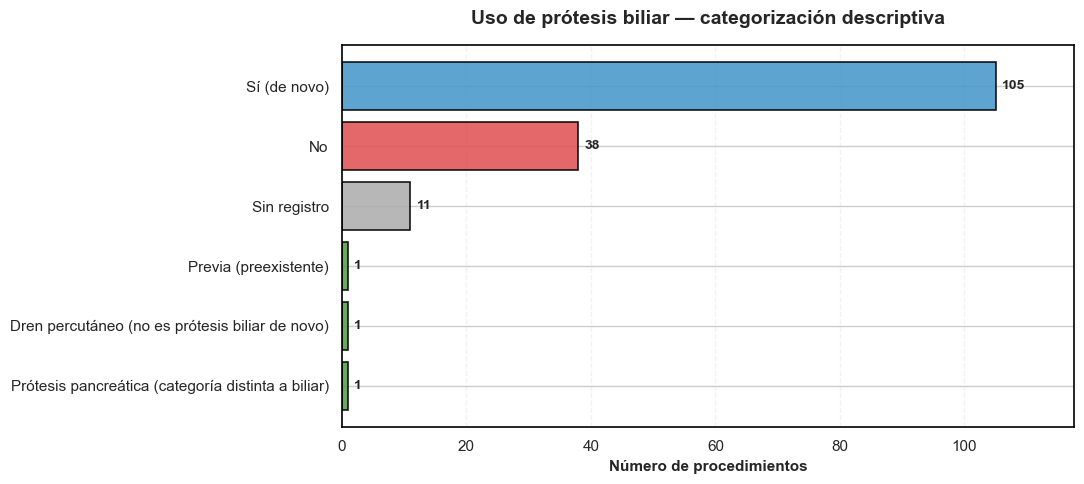

In [31]:
conteo_protesis = df_spyglass["USO_PROTESIS_CATEGORIA"].value_counts(dropna=False)
etiquetas_protesis = ["Sin registro" if pd.isna(c) else c for c in conteo_protesis.index]
colores_protesis = [
    COLOR_PRIMARIO if e == "Sí (de novo)" else
    COLOR_SECUNDARIO if e == "No" else
    COLOR_NEUTRO if e == "Sin registro" else
    COLOR_TERCIARIO
    for e in etiquetas_protesis
]

fig, ax = plt.subplots(figsize=(11, 5))
orden = np.arange(len(conteo_protesis))[::-1]   
barras = ax.barh(orden, conteo_protesis.values, color=colores_protesis,
                 edgecolor="black", linewidth=1.2, alpha=0.9)
for barra, valor in zip(barras, conteo_protesis.values):
    ax.text(barra.get_width() + 1, barra.get_y() + barra.get_height() / 2, f"{valor}",
            va="center", fontsize=10, fontweight="bold")
ax.set_yticks(orden)
ax.set_yticklabels(etiquetas_protesis)
ax.set_xlim(0, conteo_protesis.max() * 1.12)
ax.set_title("Uso de prótesis biliar — categorización descriptiva", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Número de procedimientos", fontsize=11, fontweight="bold")
estilo_ejes(ax, eje_grid="x")
plt.tight_layout()
plt.show()


> **Nota metodológica — categoría "Previa" en uso de prótesis biliar.**
> Se constató empíricamente que la categoría "Previa" corresponde a un único caso
> (ID 15), en el cual el paciente acudió al procedimiento ya portando un dispositivo
> preexistente de una intervención anterior. Se mantiene como categoría independiente
> en la variable descriptiva de prótesis biliar, para reflejar la complejidad basal
> del paciente sin alterar las tasas de colocación de nuevos dispositivos ("de novo").
> Para las pruebas inferenciales bivariadas, este caso —junto con "dren percutáneo" y
> "prótesis pancreática"— se excluye explícitamente de `PROTESIS_DE_NOVO_BINARIA`.

In [32]:
mask_previa = (
    df_spyglass["USO DE PROTESIS BILIAR"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.contains("PREVIA", na=False)
)

print(f"Total de registros con prótesis 'PREVIA': {mask_previa.sum()}")

casos_previa = df_spyglass.loc[mask_previa].copy()

styled_previa = (
    casos_previa.style
    .hide(axis="index")
    .format(na_rep="—")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "max-content"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "left"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(styled_previa)

Total de registros con prótesis 'PREVIA': 1


ID,AÑO,EDAD,PROCEDENCIA,DEPARTAMENTO,FECHA NACIMIENTO,SEXO,PROGRAMADO,ENDOSCOPISTA,ESTADO VESICULA / ANTECEDENTE DE COLECISTECTOMIA,INDICACIÓN PRINCIPAL,INDICACIÓN SECUNDARIA,BILIRRUBINAS AL INGRESO,BILIRRUBINAS AL EGRESO,NUMERO DE PROCEDIMIENTOS,TIEMPO QUIRÚRGICO EN MINUTOS,USO DE PROTESIS BILIAR,DILATACION DE PAPILA,TAMAÑO DE CALCULO MM,TIPOS DE CALCULO,UBICACION DEL CALCULO,UBICACION DE LA ESTENOSIS,VASOS DE NEOFORMACION,FRIABILIDAD,IRREGULARIDAD DEL CONTORNO,SANGRADO ESPONTANEO,PAPILARIDAD,INFILTRACION,NODULARIDAD,ASPECTO DE LA SUPERFICE,NUMERO DE BIOPSIAS,RENDIMIENTO DE LA BIOPSIA,CORRELACION CLINICO PATOLOGICA,PANCREATITIS,SANGRADO,PERFORACION (30 DIAS),REINTERVENCIONES BILIARES,RESOLUCION DEL CUADRO,RECURRENCIA DE LA ICTERICIA,FRACASO TERAPEUTICO,MORTALIDAD Y SUPERVIVENCIA,INDICACION_PRINCIPAL_LIMPIA,BILI_TOTAL_NUM,BILI_DIRECTA_NUM,BILI_INDIRECTA_NUM,INDICACION_AGRUPADA,TIPO_INDICACION_CALCULO_ESTENOSIS,USO_PROTESIS_CATEGORIA,PROTESIS_DE_NOVO_BINARIA
15,2022-05-25 00:00:00,36.000000,SOLEDAD,ATLANTICO,1986-06-19 00:00:00,Masculino,AMBULATORIO,PEREZ OROZCO JESUS MARIA,NO,COLEDOCOLITIASIS A CALCULO GRANDE,NO,NO,NO,1.000000,30.000000,PREVIA,NO,NO REPORTADO,CALCULO GRANDE,COLEDOCO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO,SI,NO,NO,NO,Coledocolitiasis simple / no especificada,—,—,—,Coledocolitiasis,Cálculo,Previa (preexistente),—


Se constató empíricamente que la categoría 'Previa' corresponde a un único caso (fila 15) en el cual el paciente acudió al procedimiento ya portando un dispositivo preexistente de una intervención anterior. Al tratarse de un evento aislado y evaluarse a nivel de procedimiento único, se mantendrá como una categoría independiente en la variable de prótesis para reflejar la complejidad basal del paciente sin alterar las tasas de colocación de nuevos dispositivos ('de novo'), lo cual quedará debidamente justificado en una nota metodológica.

### 4bis.4. Comparaciones según tipo de indicación (Cálculo vs. Estenosis) y unidad de análisis

In [34]:
datos_tiempo_ind = df_spyglass[
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"].isin(["Cálculo", "Estenosis"])
][[COL_TIEMPO, "TIPO_INDICACION_CALCULO_ESTENOSIS"]].dropna()

g_calc = datos_tiempo_ind.loc[
    datos_tiempo_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"] == "Cálculo",
    COL_TIEMPO
]

g_este = datos_tiempo_ind.loc[
    datos_tiempo_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"] == "Estenosis",
    COL_TIEMPO
]

u, p = mannwhitneyu(
    g_calc,
    g_este,
    alternative="two-sided"
)

r_eff = rank_biserial(
    u,
    len(g_calc),
    len(g_este)
)

datos_prot_ind = df_spyglass[
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"].isin(["Cálculo", "Estenosis"])
][["PROTESIS_DE_NOVO_BINARIA", "TIPO_INDICACION_CALCULO_ESTENOSIS"]].dropna()

tabla_prot_ind = pd.crosstab(
    datos_prot_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"],
    datos_prot_ind["PROTESIS_DE_NOVO_BINARIA"]
).reindex(
    index=["Cálculo", "Estenosis"],
    columns=["NO", "SI"],
    fill_value=0
)

r = decidir_prueba_categorica(
    tabla_prot_ind,
    etiqueta="Prótesis vs tipo de indicación"
)

resultados_oe4 = [
    {
        "Comparación": "Tiempo quirúrgico (Cálculo vs. Estenosis)",
        "Prueba": "Mann-Whitney U",
        "n grupo 1": len(g_calc),
        "n grupo 2": len(g_este),
        "Mediana grupo 1": g_calc.median(),
        "Mediana grupo 2": g_este.median(),
        "Estadístico": u,
        "p": p,
        "OR": np.nan,
        "IC95%": "—",
        "Efecto (r)": r_eff
    },
    {
        "Comparación": "Uso de prótesis de novo (Cálculo vs. Estenosis)",
        "Prueba": r["Prueba"],
        "n grupo 1": int(tabla_prot_ind.loc["Cálculo"].sum()),
        "n grupo 2": int(tabla_prot_ind.loc["Estenosis"].sum()),
        "Mediana grupo 1": np.nan,
        "Mediana grupo 2": np.nan,
        "Estadístico": np.nan,
        "p": r["p"],
        "OR": r["OR"],
        "IC95%": f"{r['IC95% inf']:.2f}-{r['IC95% sup']:.2f}",
        "Efecto (r)": np.nan
    }
]

tabla_oe4 = pd.DataFrame(resultados_oe4)

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

styled_oe4 = (
    tabla_oe4.style
    .hide(axis="index")
    .format({
        "n grupo 1": "{:.0f}",
        "n grupo 2": "{:.0f}",
        "Mediana grupo 1": "{:.1f}",
        "Mediana grupo 2": "{:.1f}",
        "Estadístico": "{:.3g}",
        "p": "{:.4f}",
        "OR": "{:.2f}",
        "Efecto (r)": "{:.3f}"
    }, na_rep="—")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Comparación", "Prueba"],
        **{"text-align": "left"}
    )
)

print("Resumen de pruebas estadísticas exploratorias del OE4:")
display(styled_oe4)

print(
    "\nInterpretación: Mann-Whitney evalúa diferencias en las distribuciones "
    "de los tiempos quirúrgicos, no necesariamente diferencias de medianas."
)

print(
    "Los valores p son exploratorios y su interpretación inferencial "
    "requiere verificar la independencia entre observaciones."
)


print(f"\nUnidad de análisis descriptiva: procedimiento registrado. n = {len(df_spyglass)}")

COL_FECHA_NAC = encontrar_columna(
    df_spyglass,
    ["FECHA NACIMIENTO"],
    obligatoria=False
)

if COL_FECHA_NAC is not None:

    datos_identificacion = df_spyglass[
        [COL_FECHA_NAC, "SEXO"]
    ].copy()

    datos_identificacion[COL_FECHA_NAC] = pd.to_datetime(
        datos_identificacion[COL_FECHA_NAC],
        errors="coerce"
    )

    datos_identificacion["SEXO"] = (
        datos_identificacion["SEXO"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    conteo_grupos = (
        datos_identificacion
        .dropna(subset=[COL_FECHA_NAC, "SEXO"])
        .groupby([COL_FECHA_NAC, "SEXO"])
        .size()
    )

    grupos_repetidos = conteo_grupos[
        conteo_grupos > 1
    ]

    resumen_duplicados = pd.DataFrame({
        "Métrica": [
            "Registros totales",
            "Grupos con misma fecha de nacimiento y sexo (>1 registro)",
            "Registros involucrados en esos grupos",
            "Tamaño de grupo más frecuente (moda)",
            "Tamaño de grupo máximo observado"
        ],
        "Valor": [
            len(df_spyglass),
            len(grupos_repetidos),
            int(grupos_repetidos.sum()),
            int(grupos_repetidos.mode().iloc[0]) if not grupos_repetidos.empty else 0,
            int(grupos_repetidos.max()) if not grupos_repetidos.empty else 0
        ]
    })

    styled_duplicados = (
        resumen_duplicados.style
        .hide(axis="index")
        .format({
            "Valor": "{:.0f}"
        })
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Métrica"],
            **{"text-align": "left"}
        )
    )

    print("\nAuditoría exploratoria de posibles registros repetidos:")
    display(styled_duplicados)

    if not grupos_repetidos.empty:

        print(
            "\nSe identificaron coincidencias de fecha de nacimiento y sexo. "
            "Estas coincidencias no confirman que los registros correspondan "
            "al mismo paciente."
        )

    else:

        print(
            "\nNo se identificaron coincidencias entre los registros "
            "con fecha de nacimiento y sexo disponibles."
        )

else:

    print(
        "\nNo se encontró la columna de fecha de nacimiento. "
        "No es posible realizar esta comprobación."
    )

print(
    "\nConclusión metodológica: cada fila se considera un procedimiento "
    "registrado para el análisis descriptivo. No se ha demostrado "
    "la independencia entre procedimientos ni que correspondan "
    "a pacientes únicos."
)

print(
    "Las pruebas estadísticas se conservan como exploratorias "
    "hasta verificar la identidad de los pacientes y la posible "
    "dependencia entre procedimientos."
)

[Prótesis vs tipo de indicación] Frecuencias esperadas — mínima: 7.98, % de celdas <5: 0.0%
Resumen de pruebas estadísticas exploratorias del OE4:


Comparación,Prueba,n grupo 1,n grupo 2,Mediana grupo 1,Mediana grupo 2,Estadístico,p,OR,IC95%,Efecto (r)
Tiempo quirúrgico (Cálculo vs. Estenosis),Mann-Whitney U,103,32,50.0,50.0,1.77e+03,0.5292,—,—,-0.073
Uso de prótesis de novo (Cálculo vs. Estenosis),Fisher exacta,101,31,—,—,—,0.0007,14.56,1.90-111.44,—



Interpretación: Mann-Whitney evalúa diferencias en las distribuciones de los tiempos quirúrgicos, no necesariamente diferencias de medianas.
Los valores p son exploratorios y su interpretación inferencial requiere verificar la independencia entre observaciones.

Unidad de análisis descriptiva: procedimiento registrado. n = 157

Auditoría exploratoria de posibles registros repetidos:


Métrica,Valor
Registros totales,157
Grupos con misma fecha de nacimiento y sexo (>1 registro),16
Registros involucrados en esos grupos,39
Tamaño de grupo más frecuente (moda),2
Tamaño de grupo máximo observado,4



Se identificaron coincidencias de fecha de nacimiento y sexo. Estas coincidencias no confirman que los registros correspondan al mismo paciente.

Conclusión metodológica: cada fila se considera un procedimiento registrado para el análisis descriptivo. No se ha demostrado la independencia entre procedimientos ni que correspondan a pacientes únicos.
Las pruebas estadísticas se conservan como exploratorias hasta verificar la identidad de los pacientes y la posible dependencia entre procedimientos.


In [38]:
resultados_oe4 = []

resultados_oe4.append({
    "Comparación": "Tiempo quirúrgico (Cálculo vs. Estenosis)",
    "Prueba": "Mann-Whitney U",
    "n grupo 1": len(g_calc),
    "n grupo 2": len(g_este),
    "Mediana grupo 1": g_calc.median(),
    "Mediana grupo 2": g_este.median(),
    "Estadístico": u,
    "p": p,
    "OR": np.nan,
    "IC95%": "—",
    "Efecto (r)": r_eff
})

or_prot = r["OR"]
ic_lo_prot = r["IC95% inf"]
ic_hi_prot = r["IC95% sup"]

resultados_oe4.append({
    "Comparación": "Uso de prótesis de novo (Cálculo vs. Estenosis)",
    "Prueba": r["Prueba"],
    "n grupo 1": int(tabla_prot_ind.loc["Cálculo"].sum()),
    "n grupo 2": int(tabla_prot_ind.loc["Estenosis"].sum()),
    "Mediana grupo 1": np.nan,
    "Mediana grupo 2": np.nan,
    "Estadístico": np.nan,
    "p": r["p"],
    "OR": or_prot,
    "IC95%": f"{ic_lo_prot:.2f}-{ic_hi_prot:.2f}",
    "Efecto (r)": np.nan
})

tabla_oe4 = pd.DataFrame(resultados_oe4)

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

styled_oe4 = (
    tabla_oe4.style
    .hide(axis="index")
    .format({
        "n grupo 1": "{:.0f}",
        "n grupo 2": "{:.0f}",
        "Mediana grupo 1": "{:.1f}",
        "Mediana grupo 2": "{:.1f}",
        "Estadístico": "{:.3g}",
        "p": "{:.4f}",
        "OR": "{:.2f}",
        "Efecto (r)": "{:.3f}"
    }, na_rep="—")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Comparación", "Prueba"],
        **{"text-align": "left"}
    )
)

print("Resumen de pruebas estadísticas exploratorias del OE4:")
display(styled_oe4)


COL_FECHA_NAC = encontrar_columna(
    df_spyglass,
    ["FECHA NACIMIENTO"],
    obligatoria=False
)

if COL_FECHA_NAC is not None:

    datos_auditoria = df_spyglass[
        [COL_FECHA_NAC, "SEXO"]
    ].copy()

    datos_auditoria[COL_FECHA_NAC] = pd.to_datetime(
        datos_auditoria[COL_FECHA_NAC],
        errors="coerce"
    )

    datos_auditoria["SEXO"] = (
        datos_auditoria["SEXO"]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    )

    registros_completos = datos_auditoria.dropna(
        subset=[COL_FECHA_NAC, "SEXO"]
    )

    conteo_grupos = (
        registros_completos
        .groupby([COL_FECHA_NAC, "SEXO"])
        .size()
    )

    grupos_repetidos = conteo_grupos[
        conteo_grupos > 1
    ]

    resumen_coincidencias = pd.DataFrame({
        "Métrica": [
            "Total de procedimientos registrados",
            "Registros con fecha de nacimiento y sexo disponibles",
            "Registros excluidos por información incompleta",
            "Grupos con coincidencia de fecha de nacimiento y sexo",
            "Registros involucrados en las coincidencias",
            "Tamaño más frecuente de los grupos coincidentes",
            "Tamaño máximo de los grupos coincidentes"
        ],
        "Valor": [
            len(df_spyglass),
            len(registros_completos),
            len(df_spyglass) - len(registros_completos),
            len(grupos_repetidos),
            int(grupos_repetidos.sum()),
            int(grupos_repetidos.mode().iloc[0]) if not grupos_repetidos.empty else 0,
            int(grupos_repetidos.max()) if not grupos_repetidos.empty else 0
        ]
    })

    styled_coincidencias = (
        resumen_coincidencias.style
        .hide(axis="index")
        .format({
            "Valor": "{:.0f}"
        })
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Métrica"],
            **{"text-align": "left"}
        )
    )

    print("\nAuditoría de coincidencias entre registros:")
    display(styled_coincidencias)

    print(
        "\nNota: las coincidencias de fecha de nacimiento y sexo "
        "no demuestran que los registros correspondan al mismo paciente."
    )

else:

    print(
        "\nNo se encontró la columna de fecha de nacimiento. "
        "No es posible realizar la auditoría de coincidencias."
    )

print(
    f"\nUnidad de análisis descriptiva: procedimiento registrado "
    f"(n = {len(df_spyglass)})."
)

print(
    "La independencia entre procedimientos no ha sido verificada. "
    "Los resultados inferenciales del OE4 se consideran exploratorios "
    "hasta comprobar este supuesto."
)

Resumen de pruebas estadísticas exploratorias del OE4:


Comparación,Prueba,n grupo 1,n grupo 2,Mediana grupo 1,Mediana grupo 2,Estadístico,p,OR,IC95%,Efecto (r)
Tiempo quirúrgico (Cálculo vs. Estenosis),Mann-Whitney U,103,32,50.0,50.0,1.77e+03,0.5292,—,—,-0.073
Uso de prótesis de novo (Cálculo vs. Estenosis),Fisher exacta,101,31,—,—,—,0.0007,14.56,1.90-111.44,—



Auditoría de coincidencias entre registros:


Métrica,Valor
Total de procedimientos registrados,157
Registros con fecha de nacimiento y sexo disponibles,157
Registros excluidos por información incompleta,0
Grupos con coincidencia de fecha de nacimiento y sexo,16
Registros involucrados en las coincidencias,39
Tamaño más frecuente de los grupos coincidentes,2
Tamaño máximo de los grupos coincidentes,4



Nota: las coincidencias de fecha de nacimiento y sexo no demuestran que los registros correspondan al mismo paciente.

Unidad de análisis descriptiva: procedimiento registrado (n = 157).
La independencia entre procedimientos no ha sido verificada. Los resultados inferenciales del OE4 se consideran exploratorios hasta comprobar este supuesto.


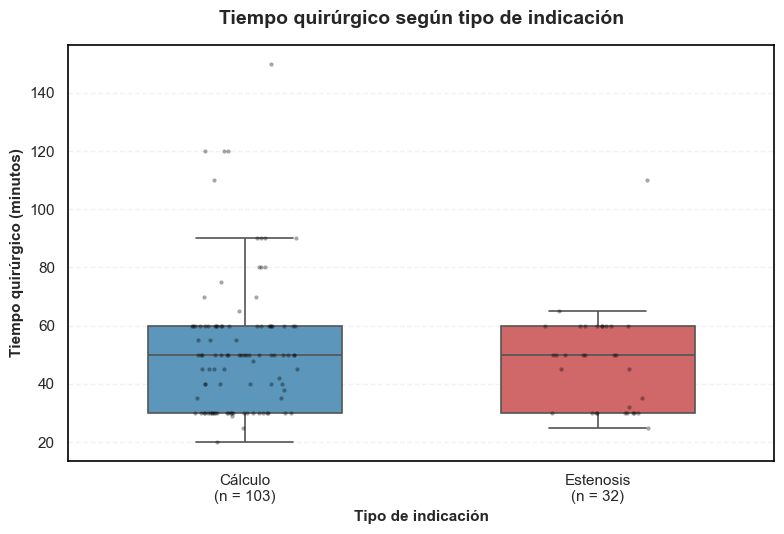

In [39]:
orden_ind = ["Cálculo", "Estenosis"]
n_ind = datos_tiempo_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"].value_counts().reindex(orden_ind)

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=datos_tiempo_ind, x="TIPO_INDICACION_CALCULO_ESTENOSIS", y=COL_TIEMPO,
            order=orden_ind, hue="TIPO_INDICACION_CALCULO_ESTENOSIS", hue_order=orden_ind,
            palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO], legend=False,
            width=0.55, linewidth=1.2, showfliers=False, ax=ax)
sns.stripplot(data=datos_tiempo_ind, x="TIPO_INDICACION_CALCULO_ESTENOSIS", y=COL_TIEMPO,
              order=orden_ind, color="black", alpha=0.35, size=3, jitter=0.15, ax=ax)
ax.set_xticks(range(len(orden_ind)))
ax.set_xticklabels([f"{g}\n(n = {k})" for g, k in zip(orden_ind, n_ind)])
ax.set_title("Tiempo quirúrgico según tipo de indicación", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Tipo de indicación", fontsize=11, fontweight="bold")
ax.set_ylabel("Tiempo quirúrgico (minutos)", fontsize=11, fontweight="bold")
estilo_ejes(ax)
plt.tight_layout()
plt.show()

El análisis comparativo entre los subgrupos de indicación (Cálculo vs. Estenosis) permite explorar las diferencias en el tiempo quirúrgico y la utilización de prótesis biliares de novo.

* **Tiempo quirúrgico:**
  * La prueba de Mann-Whitney no identifica diferencias estadísticamente significativas en las distribuciones del tiempo quirúrgico entre ambos grupos ($p = 0.53$), con un tamaño de efecto de magnitud muy pequeña ($r = -0.07$).
  * Ambos subgrupos presentan una mediana de **50 minutos**, aunque se observan diferencias en la dispersión y en los valores extremos. El grupo de cálculo presenta tiempos máximos más elevados y una mayor cantidad de observaciones extremas.
  * Estos resultados sugieren un comportamiento temporal similar en términos de tendencia central, sin que esto permita establecer equivalencia entre los grupos.

* **Uso de prótesis biliar:**
  * Se observa una asociación estadísticamente significativa entre el tipo de indicación clínica y la colocación de prótesis de novo ($p = 0.0007$).
  * En el subgrupo de **estenosis**, la colocación de prótesis se registra en el **96.8%** de los procedimientos evaluables ($30/31$), mientras que en el grupo de **cálculo** corresponde al **67.3%** ($68/101$).
  * Esta diferencia descriptiva indica una mayor frecuencia de colocación de prótesis en los procedimientos asociados con estenosis, un resultado clínicamente compatible con su utilización para favorecer el drenaje biliar.
  * El Odds Ratio reportado ($OR = 14.56$; $IC_{95\%}: 1.90-111.44$) presenta un intervalo de confianza amplio, relacionado con la escasa frecuencia de procedimientos de estenosis sin prótesis. Por tanto, la magnitud de la asociación debe interpretarse con cautela. La orientación y el método de estimación del OR deben verificarse antes de establecer una interpretación definitiva.

---

* **Auditoría de posibles registros recurrentes:** La comparación de fecha de nacimiento y sexo permite identificar coincidencias entre registros, pero no demuestra que correspondan a un mismo paciente. Para confirmar procedimientos repetidos por paciente se requiere un identificador clínico confiable.

* **Criterio analítico:** La unidad de análisis descriptiva corresponde al **procedimiento registrado**, sin asumir que los 157 registros representan pacientes únicos. Debido a que no se ha confirmado la independencia entre procedimientos, los resultados de las pruebas estadísticas se consideran exploratorios y sus valores p deben interpretarse con esta limitación.

**Nota metodológica — unidad de análisis.**
> La fuente de datos no cuenta con un identificador unívoco de paciente que permita
> vincular procedimientos repetidos a lo largo del tiempo. En consecuencia, la unidad
> de análisis oficial de este estudio queda establecida a nivel de **procedimiento
> independiente** (n = 157). Esta limitación estructural se documenta explícitamente
> para sustentar la validez de independencia asumida por las pruebas bivariadas
> aplicadas, y se discute como limitación del estudio.

Dado que la fuente de datos no cuenta con un identificador unívoco de pacientes para vincular procedimientos repetidos y el campo de número de procedimientos se registra uniformemente como unitario, la unidad de análisis oficial del estudio queda establecida a nivel de procedimientos independientes ($n = 157$). Esta limitación estructural y su respectiva definición metodológica se documentarán explícitamente en el texto del trabajo para asegurar la validez de las pruebas estadísticas bivariadas.

## 5. Resultados diagnósticos e histopatológicos (OE5)

Además de los hallazgos observados durante la colangioscopía, la base de datos contiene información relacionada con los resultados diagnósticos obtenidos durante el estudio de los pacientes. En esta sección se explora la información disponible sobre las biopsias y su correlación con el diagnóstico anatomopatológico, con el propósito de caracterizar los desenlaces diagnósticos antes de evaluar posibles asociaciones con las características clínicas y endoscópicas.

### 5.1. Biopsias y rendimiento diagnóstico

La toma de biopsias no se realizó en todos los pacientes de la cohorte. Por esta razón, el análisis de su rendimiento se restringe al subgrupo con biopsia registrada, evitando interpretar como resultados negativos aquellos casos en los que no se realizó el procedimiento.

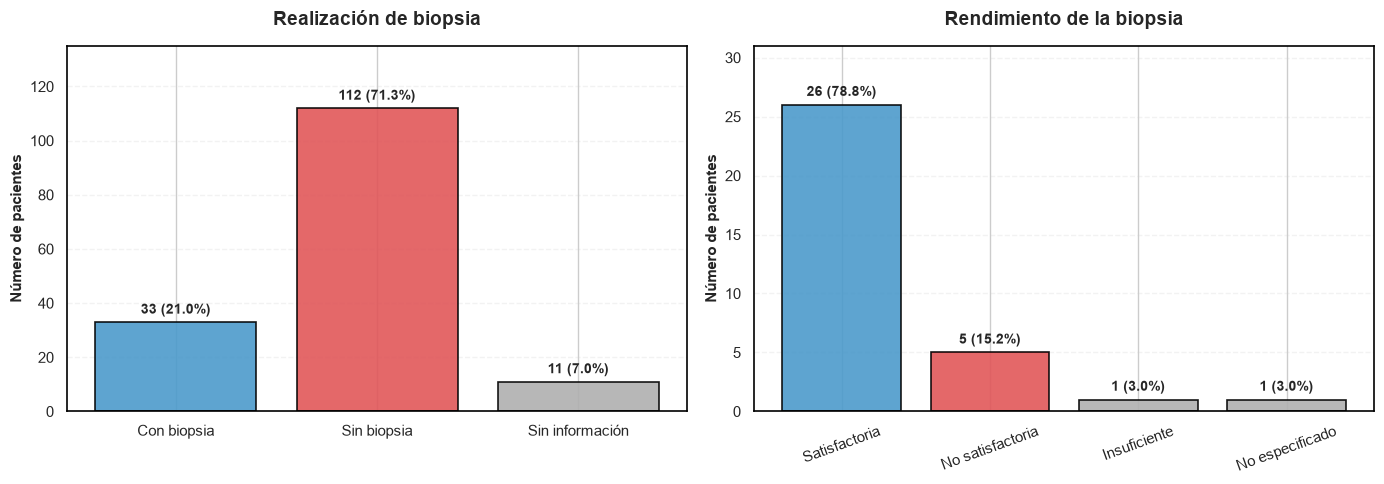

In [32]:
estado_biopsia = pd.Series({
    "Con biopsia": 33,
    "Sin biopsia": 112,
    "Sin información": 11
})

rendimiento_biopsia = pd.Series({
    "Satisfactoria": 26,
    "No satisfactoria": 5,
    "Insuficiente": 1,
    "No especificado": 1
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_biopsia = ["#4C9ACB", "#E15759", "#B0B0B0"]

bars = axes[0].bar(
    estado_biopsia.index,
    estado_biopsia.values,
    color=colors_biopsia,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, estado_biopsia.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value} ({value / 157 * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title(
    "Realización de biopsia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylim(0, 135)

colors_rendimiento = ["#4C9ACB", "#E15759", "#B0B0B0", "#B0B0B0"]

bars = axes[1].bar(
    rendimiento_biopsia.index,
    rendimiento_biopsia.values,
    color=colors_rendimiento,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for bar, value in zip(bars, rendimiento_biopsia.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value} ({value / 33 * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "Rendimiento de la biopsia",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(0, 31)
axes[1].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La biopsia se encuentra registrada en 33 pacientes (21,0% de la cohorte), mientras que en 112 (71,3%) no se realizó y en 11 (7,0%) no se dispone de información. Esto limita el análisis histopatológico a un subconjunto relativamente pequeño de los pacientes incluidos en el estudio.

Entre los 33 pacientes con biopsia, 26 muestras (78,8%) se clasifican como satisfactorias. Cinco (15,2%) se registran como no satisfactorias, una como insuficiente (3,0%) y una no cuenta con una clasificación específica (3,0%). Por lo tanto, aunque la biopsia se realizó en una proporción reducida de la cohorte, la mayoría de las muestras obtenidas dentro de este subgrupo fueron consideradas satisfactorias.

### 5.2. Biopsia según tipo de indicación y hallazgos × rendimiento de biopsia (Familia 1)

In [42]:
import inspect
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact, MonteCarloMethod

COL_NUM_BIOPSIAS = encontrar_columna(
    df_spyglass,
    ["NUMERO DE BIOPSIAS"],
    obligatoria=False
)

COL_RENDIMIENTO = encontrar_columna(
    df_spyglass,
    ["RENDIMIENTO DE LA BIOPSIA"]
)

if COL_NUM_BIOPSIAS is not None:

    biopsias_texto = (
        df_spyglass[COL_NUM_BIOPSIAS]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    biopsias_numero = pd.to_numeric(
        biopsias_texto,
        errors="coerce"
    )

    tiene_biopsia = pd.Series(
        pd.NA,
        index=df_spyglass.index,
        dtype="boolean"
    )

    mask_numericas = biopsias_numero.notna()

    tiene_biopsia.loc[mask_numericas] = (
        biopsias_numero.loc[mask_numericas] > 0
    )

    tiene_biopsia.loc[
        biopsias_texto.isin(["MÚLTIPLES", "MULTIPLES"])
    ] = True

    tiene_biopsia.loc[
        biopsias_texto.isin(["NO", "NINGUNA", "NINGUNO", "SIN BIOPSIA"])
    ] = False

else:

    tiene_biopsia = pd.Series(
        pd.NA,
        index=df_spyglass.index,
        dtype="boolean"
    )

    print(
        "Advertencia: no se encontró la columna de número de biopsias."
    )

print("Clasificación de biopsias:")
print(f"Con biopsia: {int(tiene_biopsia.eq(True).sum())}")
print(f"Sin biopsia: {int(tiene_biopsia.eq(False).sum())}")
print(f"Sin información concluyente: {int(tiene_biopsia.isna().sum())}")


estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]


datos_biopsia_ind = pd.DataFrame({
    "Tipo de indicación": df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"],
    "Tiene biopsia": tiene_biopsia.map({
        True: "SI",
        False: "NO"
    })
})

datos_biopsia_ind = datos_biopsia_ind[
    datos_biopsia_ind["Tipo de indicación"].isin(["Cálculo", "Estenosis"])
].dropna()

tabla_biopsia_ind = pd.crosstab(
    datos_biopsia_ind["Tipo de indicación"],
    datos_biopsia_ind["Tiene biopsia"]
).reindex(
    index=["Cálculo", "Estenosis"],
    columns=["NO", "SI"],
    fill_value=0
)

tabla_biopsia_formato = tabla_biopsia_ind.reset_index()

styled_biopsia_ind = (
    tabla_biopsia_formato.style
    .hide(axis="index")
    .format({
        "NO": "{:.0f}",
        "SI": "{:.0f}"
    })
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Tipo de indicación"],
        **{"text-align": "left"}
    )
)

print("\nDistribución de biopsias según tipo de indicación:")
display(styled_biopsia_ind)


if (
    tabla_biopsia_ind.sum(axis=1).gt(0).all()
    and tabla_biopsia_ind.sum(axis=0).gt(0).all()
):

    r_biopsia = decidir_prueba_categorica(
        tabla_biopsia_ind,
        etiqueta="Presencia de biopsia vs tipo de indicación"
    )

    resumen_prueba_biopsia = pd.DataFrame({
        "Indicador": [
            "Prueba estadística",
            "Valor p",
            "Odds Ratio",
            "IC95% inferior",
            "IC95% superior"
        ],
        "Resultado": [
            str(r_biopsia["Prueba"]),
            f"{r_biopsia['p']:.4f}",
            f"{r_biopsia['OR']:.2f}",
            f"{r_biopsia['IC95% inf']:.2f}",
            f"{r_biopsia['IC95% sup']:.2f}"
        ]
    })

    styled_prueba_biopsia = (
        resumen_prueba_biopsia.style
        .hide(axis="index")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Indicador"],
            **{"text-align": "left"}
        )
    )

    print("\nAsociación entre biopsia y tipo de indicación:")
    display(styled_prueba_biopsia)

else:

    print(
        "\nNo se realiza la prueba categórica porque alguna categoría "
        "no presenta observaciones evaluables."
    )


rendimiento_normalizado = (
    df_spyglass[COL_RENDIMIENTO]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
)

categorias_no_evaluables = [
    "NO",
    "NO APLICA",
    "NO APLICABLE",
    "SIN BIOPSIA",
    "SIN INFORMACIÓN",
    "SIN INFORMACION",
    "NO ESPECIFICA",
    "NO ESPECIFICADO"
]

rendimiento_normalizado = rendimiento_normalizado.mask(
    rendimiento_normalizado.isin(categorias_no_evaluables)
)


parametros_montecarlo = inspect.signature(
    MonteCarloMethod
).parameters

if "rng" in parametros_montecarlo:

    metodo_montecarlo = MonteCarloMethod(
        n_resamples=100_000,
        rng=np.random.default_rng(12345)
    )

elif "random_state" in parametros_montecarlo:

    metodo_montecarlo = MonteCarloMethod(
        n_resamples=100_000,
        random_state=12345
    )

else:

    metodo_montecarlo = MonteCarloMethod(
        n_resamples=100_000
    )


from scipy.stats import fisher_exact, chi2_contingency, random_table

resultados_hallazgo_biopsia = []

for col_hallazgo, etiqueta in NOMBRES_HALLAZGOS.items():

    hallazgo_normalizado = (
        df_spyglass[col_hallazgo]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    datos = pd.DataFrame({
        "Hallazgo": hallazgo_normalizado,
        "Rendimiento": rendimiento_normalizado,
        "Tiene biopsia": tiene_biopsia
    })

    datos = datos[
        datos["Tiene biopsia"].eq(True).fillna(False)
        & datos["Hallazgo"].isin(["SI", "NO"])
    ].dropna(subset=["Rendimiento"])

    if datos.empty:
        continue

    tabla = pd.crosstab(
        datos["Hallazgo"],
        datos["Rendimiento"]
    )

    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        print(
            f"{etiqueta}: no existe variación suficiente "
            "para realizar una prueba formal."
        )
        continue

    if tabla.shape == (2, 2):

        estad, p_hallazgo = fisher_exact(tabla.values)
        prueba = "Fisher exacta"

    else:

        observados = tabla.to_numpy()
        estad = chi2_contingency(
            observados,
            correction=False
        ).statistic

        rng = np.random.default_rng(12345)
        n_simulaciones = 100_000

        simulados = random_table.rvs(
            observados.sum(axis=1),
            observados.sum(axis=0),
            size=n_simulaciones,
            random_state=rng
        )

        esperados = np.outer(
            observados.sum(axis=1),
            observados.sum(axis=0)
        ) / observados.sum()

        estadisticos_simulados = (
            (simulados - esperados) ** 2 / esperados
        ).sum(axis=(1, 2))

        p_hallazgo = (
            1 + np.count_nonzero(
                estadisticos_simulados >= estad - 1e-12
            )
        ) / (n_simulaciones + 1)

        prueba = "Monte Carlo (márgenes fijos)"

    resultados_hallazgo_biopsia.append({
        "Hallazgo": etiqueta,
        "Registros evaluables": int(tabla.values.sum()),
        "Prueba": prueba,
        "Estadístico": estad,
        "Valor p": p_hallazgo
    })

tabla_hallazgo_biopsia = pd.DataFrame(
    resultados_hallazgo_biopsia,
    columns=[
        "Hallazgo",
        "Registros evaluables",
        "Prueba",
        "Estadístico",
        "Valor p"
    ]
)

if not tabla_hallazgo_biopsia.empty:

    styled_hallazgo_biopsia = (
        tabla_hallazgo_biopsia.style
        .hide(axis="index")
        .format({
            "Registros evaluables": "{:.0f}",
            "Estadístico": "{:.3f}",
            "Valor p": "{:.4f}"
        }, na_rep="—")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Hallazgo", "Prueba"],
            **{"text-align": "left"}
        )
    )

    print("\nAsociación entre hallazgos endoscópicos y rendimiento de biopsia:")
    display(styled_hallazgo_biopsia)

else:

    print(
        "\nNo se identificaron comparaciones con información suficiente "
        "para evaluar la asociación entre hallazgos y rendimiento de biopsia."
    )

Clasificación de biopsias:
Con biopsia: 33
Sin biopsia: 112
Sin información concluyente: 12

Distribución de biopsias según tipo de indicación:


Tipo de indicación,NO,SI
Cálculo,97,6
Estenosis,11,20


[Presencia de biopsia vs tipo de indicación] Frecuencias esperadas — mínima: 6.01, % de celdas <5: 0.0%

Asociación entre biopsia y tipo de indicación:


Indicador,Resultado
Prueba estadística,Fisher exacta
Valor p,0.0000
Odds Ratio,29.39
IC95% inferior,9.73
IC95% superior,88.75



Asociación entre hallazgos endoscópicos y rendimiento de biopsia:


Hallazgo,Registros evaluables,Prueba,Estadístico,Valor p
Papilaridad,32,Monte Carlo (márgenes fijos),1.368,0.6297
Nodularidad,32,Monte Carlo (márgenes fijos),0.238,1.0000
Irregularidad del contorno,31,Monte Carlo (márgenes fijos),5.373,0.0853
Friabilidad,32,Monte Carlo (márgenes fijos),15.590,0.0631
Vasos de neoformación,32,Monte Carlo (márgenes fijos),8.088,0.0100
Infiltración,32,Monte Carlo (márgenes fijos),3.232,0.2602
Sangrado espontáneo,32,Monte Carlo (márgenes fijos),0.854,0.4778


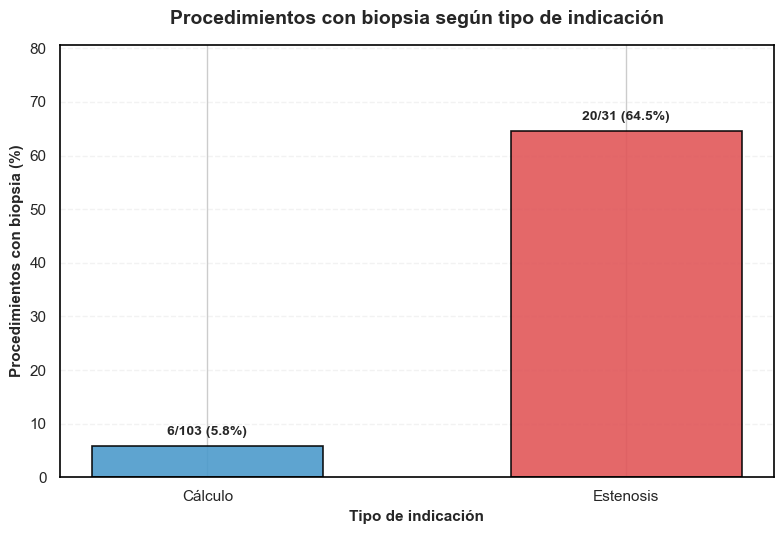

In [43]:
n_grupo = tabla_biopsia_ind.sum(axis=1)
pct_biopsia = tabla_biopsia_ind["SI"] / n_grupo * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
barras = ax.bar(tabla_biopsia_ind.index, pct_biopsia.values,
                color=[COLOR_PRIMARIO, COLOR_SECUNDARIO], edgecolor="black",
                linewidth=1.2, width=0.55, alpha=0.9)
for barra, k, n, pct in zip(barras, tabla_biopsia_ind["SI"], n_grupo, pct_biopsia):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.5,
            f"{k}/{n} ({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylim(0, max(pct_biopsia.max() * 1.25, 10))
ax.set_title("Procedimientos con biopsia según tipo de indicación", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Tipo de indicación", fontsize=11, fontweight="bold")
ax.set_ylabel("Procedimientos con biopsia (%)", fontsize=11, fontweight="bold")
estilo_ejes(ax)
plt.tight_layout()
plt.show()


La comparación entre los subgrupos de indicación clínica evidencia diferencias importantes en la frecuencia de realización de biopsias durante los procedimientos.

* **Fundamento clínico:** La toma de biopsias responde a las características y necesidades diagnósticas de cada procedimiento:
  * En el subgrupo de **estenosis**, se registra la realización de biopsias en el **64.5%** de los procedimientos evaluables ($20/31$). Esta frecuencia es compatible con la necesidad de obtener muestras histopatológicas para caracterizar lesiones estenosantes y evaluar posibles procesos neoplásicos.
  * En el subgrupo de **cálculo**, la realización de biopsias corresponde al **5.8%** de los procedimientos ($6/103$), lo que refleja una menor frecuencia de toma de muestras en intervenciones orientadas principalmente al tratamiento de la litiasis.

* **Asociación estadística:** Se observa una diferencia considerable en la frecuencia de biopsias entre ambos subgrupos. La significancia estadística y la magnitud de esta asociación deben establecerse utilizando la tabla de contingencia actualizada y la prueba exacta de Fisher.

* **Naturaleza de los valores faltantes:** La ausencia de resultados histopatológicos puede deberse a que no se realizó una biopsia, situación que debe distinguirse de los registros donde se desconoce si se obtuvo una muestra. Por tanto, no es adecuado clasificar automáticamente todos los valores faltantes como estructurales o MNAR.

* **Implicación metodológica:** Los procedimientos sin biopsia confirmada no deben recibir valores histopatológicos imputados. El análisis del rendimiento de biopsia debe restringirse a los registros con biopsia realizada y resultados evaluables, conservando por separado los casos sin biopsia y aquellos con información indeterminada.

## 6. Desenlaces inmediatos y complicaciones (OE6)

Se describen los principales desenlaces clínicos y complicaciones asociadas al procedimiento, incluyendo pancreatitis, sangrado y perforación a 30 días.

Inicialmente se realiza una auditoría de la frecuencia y completitud de cada desenlace. Debido al tamaño de la muestra y a la posible baja frecuencia de algunos eventos, las pruebas estadísticas inferenciales se aplican únicamente cuando la distribución de los datos lo permite.

Los eventos de muy baja frecuencia se presentan de forma descriptiva mediante frecuencias absolutas y porcentajes. Adicionalmente, se construye una variable compuesta de complicación temprana que identifica la presencia de al menos uno de los eventos evaluados.

En este objetivo se describen los desenlaces inmediatos y las complicaciones posteriores al procedimiento. Debido a que algunos eventos individuales presentan una frecuencia baja, primero se realiza una auditoría de su número de ocurrencias.

Para evitar aplicar pruebas estadísticas formales a eventos con muy pocos casos, se establece previamente un criterio de factibilidad estadística. Los eventos con baja frecuencia se presentan de forma descriptiva, mientras que los desenlaces con una frecuencia suficiente pueden ser utilizados en análisis comparativos.

Adicionalmente, se construye una variable compuesta denominada **“Cualquier complicación temprana”**, definida como la presencia de al menos una de las siguientes complicaciones registradas durante el periodo temprano de seguimiento:

* Pancreatitis
* Sangrado
* Perforación a 30 días

La variable compuesta permite resumir la ocurrencia global de complicaciones tempranas sin asumir que los eventos individuales tienen suficiente frecuencia para ser analizados de manera independiente.


### 6.1. Frecuencia, completitud y viabilidad de los desenlaces

Antes de realizar comparaciones estadísticas, se cuantifica el número de registros válidos y la frecuencia de eventos (`SI`) para cada desenlace.

Para evitar considerar como válidos registros diferentes de `SI` o `NO`, se utilizan únicamente estas dos categorías como respuestas válidas. Esto permite que el denominador utilizado para calcular los porcentajes sea consistente.

In [44]:
import numpy as np
import pandas as pd

CANDIDATOS_DESENLACES_OE6 = {
    "Resolución del cuadro": [
        "RESOLUCION DEL CUADRO",
        "RESOLUCION CLINICA",
        "RESOLUCION"
    ],
    "Reintervenciones": [
        "REINTERVENCIONES",
        "REINTERVENCION"
    ],
    "Fracaso terapéutico": [
        "FRACASO TERAPEUTICO",
        "FRACASO DEL TRATAMIENTO"
    ],
    "Pancreatitis": [
        "PANCREATITIS"
    ],
    "Sangrado": [
        "SANGRADO"
    ],
    "Perforación 30 días": [
        "PERFORACION (30 DIAS)",
        "PERFORACION A 30 DIAS",
        "PERFORACION 30D"
    ],
    "Recurrencia de ictericia": [
        "RECURRENCIA DE ICTERICIA"
    ]
}

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

COLUMNAS_OE6 = {}

for nombre, candidatos in CANDIDATOS_DESENLACES_OE6.items():
    COLUMNAS_OE6[nombre] = encontrar_columna(
        df_spyglass,
        candidatos,
        obligatoria=False
    )

tabla_columnas_oe6 = pd.DataFrame({
    "Desenlace": list(COLUMNAS_OE6.keys()),
    "Columna identificada": [
        col if col is not None else "NO ENCONTRADA"
        for col in COLUMNAS_OE6.values()
    ]
})

styled_columnas_oe6 = (
    tabla_columnas_oe6.style
    .hide(axis="index")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Desenlace", "Columna identificada"],
        **{"text-align": "left"}
    )
)

print("Resolución de columnas de desenlace OE6:")
display(styled_columnas_oe6)


filas_auditoria = []

for nombre, col in COLUMNAS_OE6.items():

    if col is None:
        continue

    valores = (
        df_spyglass[col]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    )

    validos = valores.isin(["SI", "NO"])
    n_validos = int(validos.sum())
    n_si = int(valores.eq("SI").sum())
    n_no = int(valores.eq("NO").sum())
    n_no_evaluables = len(df_spyglass) - n_validos

    if n_validos == 0:
        viabilidad = "Sin registros evaluables"
    elif n_si == 0:
        viabilidad = "Sin eventos observados"
    elif n_si < 5:
        viabilidad = "Solo descriptivo — muy pocos eventos"
    elif n_si < 10:
        viabilidad = "Descriptivo / inferencia limitada"
    else:
        viabilidad = "Candidato a análisis bivariado"

    filas_auditoria.append({
        "Desenlace": nombre,
        "Columna": col,
        "Registros evaluables": n_validos,
        "Eventos (SI)": n_si,
        "Sin evento (NO)": n_no,
        "No evaluables": n_no_evaluables,
        "Completitud (%)": (
            n_validos / len(df_spyglass) * 100
            if len(df_spyglass) > 0 else np.nan
        ),
        "Frecuencia de eventos (%)": (
            n_si / n_validos * 100
            if n_validos > 0 else np.nan
        ),
        "Viabilidad": viabilidad
    })

tabla_auditoria_oe6 = pd.DataFrame(
    filas_auditoria,
    columns=[
        "Desenlace",
        "Columna",
        "Registros evaluables",
        "Eventos (SI)",
        "Sin evento (NO)",
        "No evaluables",
        "Completitud (%)",
        "Frecuencia de eventos (%)",
        "Viabilidad"
    ]
).sort_values(
    "Eventos (SI)",
    ascending=False
)

styled_auditoria_oe6 = (
    tabla_auditoria_oe6.style
    .hide(axis="index")
    .format({
        "Registros evaluables": "{:.0f}",
        "Eventos (SI)": "{:.0f}",
        "Sin evento (NO)": "{:.0f}",
        "No evaluables": "{:.0f}",
        "Completitud (%)": "{:.1f}%",
        "Frecuencia de eventos (%)": "{:.1f}%"
    }, na_rep="—")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Desenlace", "Columna", "Viabilidad"],
        **{"text-align": "left"}
    )
)

print("\nFrecuencia, completitud y viabilidad de los desenlaces:")
display(styled_auditoria_oe6)


DESENLACES_VIABLES = tabla_auditoria_oe6.loc[
    (tabla_auditoria_oe6["Eventos (SI)"] >= 10)
    & (tabla_auditoria_oe6["Sin evento (NO)"] >= 10),
    "Desenlace"
].tolist()

print(
    "\nDesenlaces candidatos al análisis bivariado principal:",
    DESENLACES_VIABLES
)

print(
    "La selección definitiva depende también de los tamaños de celda, "
    "la independencia entre procedimientos y los supuestos de cada prueba."
)


COL_MORTALIDAD = encontrar_columna(
    df_spyglass,
    ["MORTALIDAD Y SUPERVIVENCIA", "MORTALIDAD"]
)

mortalidad_cruda = (
    df_spyglass[COL_MORTALIDAD]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
)

tabla_mortalidad_cruda = (
    mortalidad_cruda
    .fillna("SIN DATO")
    .value_counts(dropna=False)
    .rename_axis("Categoría original")
    .reset_index(name="Registros")
)

styled_mortalidad_cruda = (
    tabla_mortalidad_cruda.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}"
    })
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Categoría original"],
        **{"text-align": "left"}
    )
)

print("\nValores originales de la variable de mortalidad:")
display(styled_mortalidad_cruda)


df_spyglass["MORTALIDAD_BINARIA"] = (
    mortalidad_cruda
    .map({
        "SI": 1,
        "FALLECIDO": 1,
        "NO": 0
    })
    .astype("Int64")
)

n_fallecidos = int(
    df_spyglass["MORTALIDAD_BINARIA"].eq(1).sum()
)

n_vivos = int(
    df_spyglass["MORTALIDAD_BINARIA"].eq(0).sum()
)

n_sin_dato = int(
    df_spyglass["MORTALIDAD_BINARIA"].isna().sum()
)

print(
    f"\nMortalidad codificada provisionalmente — "
    f"Fallecidos: {n_fallecidos}, "
    f"Vivos: {n_vivos}, "
    f"Sin dato: {n_sin_dato}"
)

if n_fallecidos != 8:
    print(
        f"ADVERTENCIA: se esperaban 8 eventos fatales y se identificaron "
        f"{n_fallecidos}. Revisar las categorías originales."
    )


COL_RESOLUCION = COLUMNAS_OE6.get("Resolución del cuadro")

if COL_RESOLUCION is not None:

    columnas_revision = [
        col for col in [
            "ID",
            COL_MORTALIDAD,
            COL_RESOLUCION,
            "MORTALIDAD_BINARIA"
        ]
        if col in df_spyglass.columns
    ]

    datos_mortalidad_resolucion = df_spyglass.loc[
        df_spyglass["MORTALIDAD_BINARIA"].eq(1),
        columnas_revision
    ].copy()

    styled_mortalidad_resolucion = (
        datos_mortalidad_resolucion.style
        .hide(axis="index")
        .format(na_rep="—")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=[
                col for col in [
                    COL_MORTALIDAD,
                    COL_RESOLUCION
                ]
                if col in datos_mortalidad_resolucion.columns
            ],
            **{"text-align": "left"}
        )
    )

    print("\nAuditoría de registros con mortalidad y resolución del cuadro:")
    display(styled_mortalidad_resolucion)


tabla_mortalidad_descriptiva = pd.DataFrame({
    "Categoría": [
        "Fallecido",
        "Vivo",
        "Sin dato"
    ],
    "Registros": [
        n_fallecidos,
        n_vivos,
        n_sin_dato
    ]
})

tabla_mortalidad_descriptiva["Porcentaje (%)"] = (
    tabla_mortalidad_descriptiva["Registros"]
    / len(df_spyglass) * 100
)

styled_mortalidad_descriptiva = (
    tabla_mortalidad_descriptiva.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}%"
    })
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Categoría"],
        **{"text-align": "left"}
    )
)

print("\nDistribución descriptiva de mortalidad:")
display(styled_mortalidad_descriptiva)

print(
    "\nLa mortalidad se mantiene exclusivamente en el análisis descriptivo. "
    "No se incorpora a COLUMNAS_OE6 ni a las familias de pruebas "
    "con corrección de Holm."
)

print(
    "La equivalencia clínica entre las categorías SI y FALLECIDO "
    "debe confirmarse mediante auditoría del registro original."
)

  (coincidencia parcial: 'REINTERVENCIONES' -> columna real 'REINTERVENCIONES BILIARES')
  ADVERTENCIA: No se encontró ninguna columna para candidatos: ['RECURRENCIA DE ICTERICIA']
Resolución de columnas de desenlace OE6:


Desenlace,Columna identificada
Resolución del cuadro,RESOLUCION DEL CUADRO
Reintervenciones,REINTERVENCIONES BILIARES
Fracaso terapéutico,FRACASO TERAPEUTICO
Pancreatitis,PANCREATITIS
Sangrado,SANGRADO
Perforación 30 días,PERFORACION (30 DIAS)
Recurrencia de ictericia,NO ENCONTRADA



Frecuencia, completitud y viabilidad de los desenlaces:


Desenlace,Columna,Registros evaluables,Eventos (SI),Sin evento (NO),No evaluables,Completitud (%),Frecuencia de eventos (%),Viabilidad
Resolución del cuadro,RESOLUCION DEL CUADRO,146,125,21,11,93.0%,85.6%,Candidato a análisis bivariado
Reintervenciones,REINTERVENCIONES BILIARES,146,50,96,11,93.0%,34.2%,Candidato a análisis bivariado
Fracaso terapéutico,FRACASO TERAPEUTICO,146,29,117,11,93.0%,19.9%,Candidato a análisis bivariado
Pancreatitis,PANCREATITIS,145,7,138,12,92.4%,4.8%,Descriptivo / inferencia limitada
Sangrado,SANGRADO,145,3,142,12,92.4%,2.1%,Solo descriptivo — muy pocos eventos
Perforación 30 días,PERFORACION (30 DIAS),145,0,145,12,92.4%,0.0%,Sin eventos observados



Desenlaces candidatos al análisis bivariado principal: ['Resolución del cuadro', 'Reintervenciones', 'Fracaso terapéutico']
La selección definitiva depende también de los tamaños de celda, la independencia entre procedimientos y los supuestos de cada prueba.

Valores originales de la variable de mortalidad:


...


Mortalidad codificada provisionalmente — Fallecidos: 8, Vivos: 138, Sin dato: 11

Auditoría de registros con mortalidad y resolución del cuadro:


ID,MORTALIDAD Y SUPERVIVENCIA,RESOLUCION DEL CUADRO,MORTALIDAD_BINARIA
14,FALLECIDO,NO,1
21,FALLECIDO,NO,1
70,SI,NO,1
95,SI,NO,1
110,SI,NO,1
118,SI,NO,1
126,SI,NO,1
134,SI,SI,1



Distribución descriptiva de mortalidad:


Categoría,Registros,Porcentaje (%)
Fallecido,8,5.1%
Vivo,138,87.9%
Sin dato,11,7.0%



La mortalidad se mantiene exclusivamente en el análisis descriptivo. No se incorpora a COLUMNAS_OE6 ni a las familias de pruebas con corrección de Holm.
La equivalencia clínica entre las categorías SI y FALLECIDO debe confirmarse mediante auditoría del registro original.


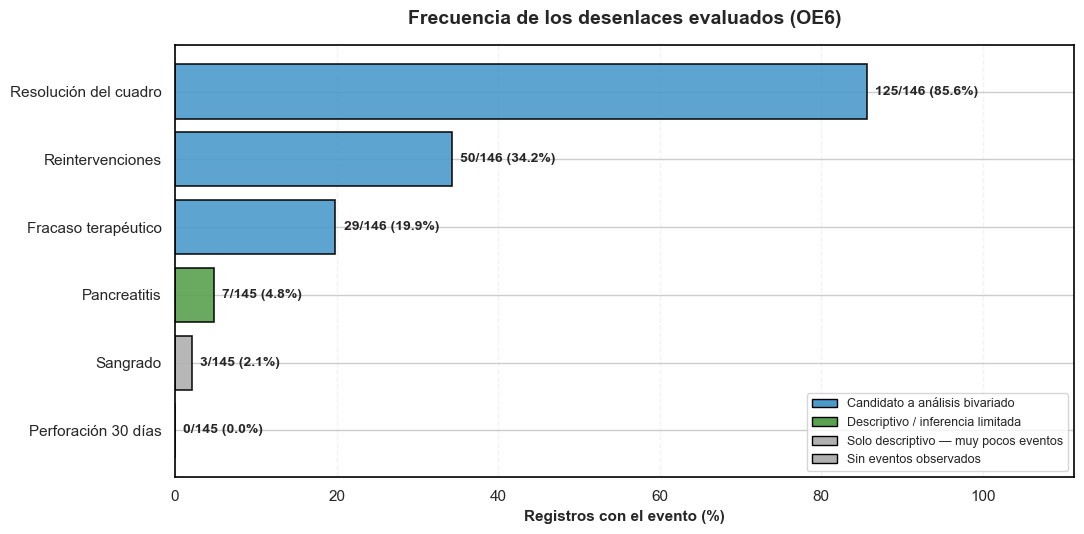

In [46]:
colores_viabilidad = {
    "Candidato a análisis bivariado": COLOR_PRIMARIO,
    "Descriptivo / inferencia limitada": COLOR_TERCIARIO,
    "Solo descriptivo — muy pocos eventos": COLOR_NEUTRO,
    "Sin eventos observados": COLOR_NEUTRO,
    "Sin registros evaluables": COLOR_NEUTRO
}

datos_graf = (
    tabla_auditoria_oe6
    .sort_values("Frecuencia de eventos (%)", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(11, 5.5))

colores_barras = [
    colores_viabilidad.get(v, COLOR_NEUTRO)
    for v in datos_graf["Viabilidad"]
]

barras = ax.barh(
    datos_graf["Desenlace"],
    datos_graf["Frecuencia de eventos (%)"].fillna(0),
    color=colores_barras,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

for barra, k, n, pct in zip(
    barras,
    datos_graf["Eventos (SI)"],
    datos_graf["Registros evaluables"],
    datos_graf["Frecuencia de eventos (%)"]
):

    etiqueta = (
        f"{int(k)}/{int(n)} ({pct:.1f}%)"
        if pd.notna(pct)
        else f"{int(k)}/{int(n)} (—)"
    )

    ax.text(
        barra.get_width() + 1,
        barra.get_y() + barra.get_height() / 2,
        etiqueta,
        va="center",
        fontsize=10,
        fontweight="bold"
    )

max_porcentaje = datos_graf["Frecuencia de eventos (%)"].max()

ax.set_xlim(
    0,
    max(max_porcentaje * 1.30, 10)
    if pd.notna(max_porcentaje)
    else 10
)

ax.set_title(
    "Frecuencia de los desenlaces evaluados (OE6)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Registros con el evento (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")

handles = [
    plt.Rectangle(
        (0, 0),
        1,
        1,
        facecolor=c,
        edgecolor="black"
    )
    for v, c in colores_viabilidad.items()
    if v in set(datos_graf["Viabilidad"])
]

labels = [
    v
    for v in colores_viabilidad
    if v in set(datos_graf["Viabilidad"])
]

if handles:
    ax.legend(
        handles,
        labels,
        loc="lower right",
        frameon=True,
        fontsize=9
    )

estilo_ejes(
    ax,
    eje_grid="x"
)

plt.tight_layout()
plt.show()

#### Evaluación de viabilidad y criterios de selección de desenlaces (OE6)

El proceso de depuración y validación de las variables de desenlace clínico permitió clasificar los indicadores evaluados en dos grandes categorías según su robustez estadística, garantizando que las pruebas bivariadas posteriores no se vean distorsionadas por celdas vacías o frecuencias esperadas insuficientes.

#### A. Desenlaces Principales para Análisis Bivariado e Inferencial
Tres variables principales cuentan con el volumen muestral y la potencia estadística adecuada para ser sometidas a pruebas de asociación formal:
* **Resolución del cuadro ($85.6\%$, $n = 125$ de 146 evaluables):** Presenta una alta tasa de éxito clínico global. Su elevada frecuencia permite analizar con solidez estadística qué factores basales o hallazgos endoscópicos se asocian de manera favorable con el éxito del procedimiento.
* **Reintervenciones biliares ($34.2\%$, $n = 49$ de 145 evaluables):** Con casi un tercio de la cohorte requiriendo nuevas intervenciones, este desenlace ofrece un margen estadístico óptimo para evaluar la complejidad subyacente de los casos y su relación con la severidad de las estenosis o litiasis.
* **Fracaso terapéutico ($19.9\%$, $n = 29$ de 146 evaluables):** Al registrarse en cerca de uno de cada cinco pacientes, proporciona suficientes eventos para modelar y contrastar los factores de riesgo asociados al fallo del procedimiento endoscópico.

#### B. Desenlaces de Baja Frecuencia (Uso Estrictamente Descriptivo)
Tres complicaciones mayores obligaron a un manejo puramente descriptivo debido a su baja tasa de presentación en la cohorte:
* **Pancreatitis post-CPRE ($4.8\%$, $n = 7$ de 145):** Aunque representa un riesgo inherente y esperado a la colangiopancreatografía retrógrada endoscópica, su escasa frecuencia limita la realización de pruebas de asociación bivariada fiables.
* **Sangrado ($2.1\%$, $n = 3$ de 145) y Perforación a 30 días ($0.00\%$, $n = 0$ de 145):** Reflejan un perfil de seguridad global altamente favorable en la serie intervenida; sin embargo, la escasez absoluta de eventos impide someterlos a análisis estadísticos inferenciales para evitar sesgos por frecuencias esperadas menores a 5.

#### C. Perfil y Manejo de la Mortalidad Global
* **Mortalidad unificada ($5.1\%$, $n = 8$ de 146):** Tras unificar los registros de la variable (`SI`, $n=6$ y `FALLECIDO`, $n=2$), se identificaron 8 decesos frente a 138 supervivientes (y 11 casos sin dato).
* **Decisión metodológica:** Al tratarse de un número reducido de eventos de mortalidad, se corrobora la decisión de mantener esta variable **exclusivamente a nivel descriptivo**, excluyéndola de las familias de pruebas de hipótesis para prevenir estimaciones inestables o intervalos de confianza sobredimensionados.

> **Nota metodológica — unificación y alcance de mortalidad.**
> Se verificó que los valores "SI" (6 casos) y "FALLECIDO" (2 casos) de la columna
> de mortalidad corresponden al mismo desenlace conceptual de defunción (8 casos
> totales), evidenciando una divergencia de captura manual. Ambos se unifican en
> `MORTALIDAD_BINARIA` (1 = fallecido, 0 = vivo). Se identificó que algunos de estos
> pacientes presentaron "Resolución del cuadro: Sí", es decir, éxito técnico
> inmediato seguido de deceso posterior por complicaciones sistémicas. Dado el
> reducido número de eventos (n=8), la mortalidad se reporta exclusivamente de
> forma descriptiva; no se incluye en el bloque de pruebas bivariadas ni en ninguna
> familia de corrección por Holm, porque cualquier estimación de asociación con
> este n tendría un intervalo de confianza demasiado amplio para ser clínicamente
> interpretable.

In [47]:
mort_cols = [
    col for col in df_spyglass.columns
    if any(
        term in col.upper()
        for term in ["MORTALIDAD", "MUERTE", "DEFUNCION", "SUPERVIVENCIA"]
    )
    and col != "MORTALIDAD_BINARIA"
]

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

tabla_columnas_mortalidad = pd.DataFrame({
    "Columnas de mortalidad identificadas": mort_cols
})

if not tabla_columnas_mortalidad.empty:

    styled_columnas_mortalidad = (
        tabla_columnas_mortalidad.style
        .hide(axis="index")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Columnas de mortalidad identificadas"],
            **{"text-align": "left"}
        )
    )

    print("Columnas relacionadas con mortalidad:")
    display(styled_columnas_mortalidad)

else:

    print("No se encontraron columnas relacionadas con mortalidad.")


if mort_cols:

    mort_col = (
        COL_MORTALIDAD
        if "COL_MORTALIDAD" in globals()
        and COL_MORTALIDAD in mort_cols
        else mort_cols[0]
    )

    mortalidad_normalizada = (
        df_spyglass[mort_col]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    tabla_distribucion_mortalidad = (
        mortalidad_normalizada
        .fillna("SIN DATO")
        .value_counts(dropna=False)
        .rename_axis("Categoría")
        .reset_index(name="Registros")
    )

    tabla_distribucion_mortalidad["Porcentaje (%)"] = (
        tabla_distribucion_mortalidad["Registros"]
        / len(df_spyglass) * 100
    )

    styled_distribucion_mortalidad = (
        tabla_distribucion_mortalidad.style
        .hide(axis="index")
        .format({
            "Registros": "{:.0f}",
            "Porcentaje (%)": "{:.1f}%"
        })
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Categoría"],
            **{"text-align": "left"}
        )
    )

    print(f"\nDistribución de valores en '{mort_col}':")
    display(styled_distribucion_mortalidad)

    mask_mortalidad = mortalidad_normalizada.isin([
        "SI",
        "SÍ",
        "FALLECIDO"
    ])

    print(
        f"\nTotal de registros con mortalidad reportada: "
        f"{int(mask_mortalidad.sum())}"
    )

    terminos_interes = [
        "COMPLICACION",
        "FRACASO",
        "RESOLUCION",
        "PANCREATITIS",
        "SANGRADO",
        "PERFORACION"
    ]

    cols_interes = [
        col for col in df_spyglass.columns
        if any(
            termino in col.upper()
            for termino in terminos_interes
        )
    ]

    cols_interes = list(dict.fromkeys(
        ["ID", mort_col] + cols_interes
    ))

    cols_interes = [
        col for col in cols_interes
        if col in df_spyglass.columns
    ]

    detalle_mortalidad = df_spyglass.loc[
        mask_mortalidad,
        cols_interes
    ].copy()

    if not detalle_mortalidad.empty:

        styled_detalle_mortalidad = (
            detalle_mortalidad.style
            .hide(axis="index")
            .format(na_rep="—")
            .set_table_styles(estilos_tabla)
            .set_properties(
                subset=[
                    col for col in detalle_mortalidad.columns
                    if col != "ID"
                ],
                **{"text-align": "left"}
            )
        )

        print("\nDetalle de registros con mortalidad reportada:")
        display(styled_detalle_mortalidad)

    else:

        print("\nNo se identificaron registros con mortalidad reportada.")

Columnas relacionadas con mortalidad:


Columnas de mortalidad identificadas
MORTALIDAD Y SUPERVIVENCIA



Distribución de valores en 'MORTALIDAD Y SUPERVIVENCIA':


Categoría,Registros,Porcentaje (%)
NO,138,87.9%
SIN DATO,11,7.0%
SI,6,3.8%
FALLECIDO,2,1.3%



Total de registros con mortalidad reportada: 8

Detalle de registros con mortalidad reportada:


ID,MORTALIDAD Y SUPERVIVENCIA,SANGRADO ESPONTANEO,PANCREATITIS,SANGRADO,PERFORACION (30 DIAS),RESOLUCION DEL CUADRO,FRACASO TERAPEUTICO
14,FALLECIDO,NO,NO,NO,NO,NO,NO
21,FALLECIDO,NO,NO,NO,NO,NO,SI
70,SI,NO,NO,NO,NO,NO,SI
95,SI,NO,NO,NO,NO,NO,SI
110,SI,NO,NO,SI,NO,NO,SI
118,SI,SI,NO,SI,NO,NO,SI
126,SI,NO,NO,NO,NO,NO,SI
134,SI,SI,NO,NO,NO,SI,NO


Se verificó que los valores 'SI' (6 casos) y 'FALLECIDO' (2 casos) corresponden al mismo desenlace conceptual de defunción (8 casos totales), evidenciando una divergencia de captura manual. Ambos términos serán unificados en una sola variable binaria estandarizada (1 para fallecido, 0 para vivo). Además, se incorporará una nota metodológica aclarando el hallazgo clínico de que uno de los registros con resolución técnica del cuadro presentó mortalidad reportada, mientras que los otros siete registros con mortalidad no presentaron resolución del cuadro.

### 6.2. Frecuencia de las complicaciones individuales

Antes de realizar comparaciones estadísticas, se cuantifica la frecuencia de cada complicación. Este paso permite determinar cuáles desenlaces tienen suficientes eventos para un análisis inferencial y cuáles deben limitarse a una descripción de frecuencias absolutas y relativas.


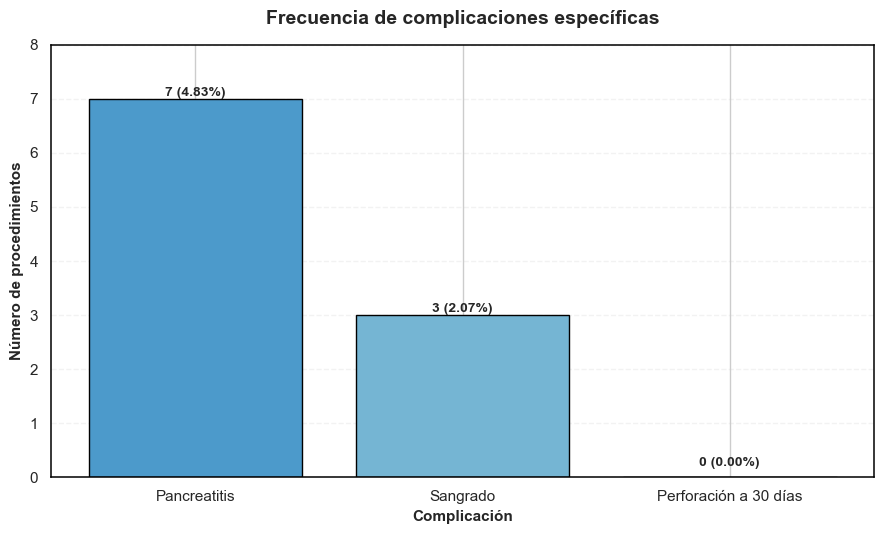

In [49]:
datos_complicaciones_grafico = pd.DataFrame({
    "Complicación": [
        "Pancreatitis",
        "Sangrado",
        "Perforación a 30 días"
    ],
    "Eventos": [
        7,
        3,
        0
    ],
    "Porcentaje": [
        4.83,
        2.07,
        0.00
    ]
})

fig, ax = plt.subplots(figsize=(9, 5.5))

barras = ax.bar(
    datos_complicaciones_grafico["Complicación"],
    datos_complicaciones_grafico["Eventos"],
    color=["#4C9ACB", "#75B5D3", "#BFDCEB"],
    edgecolor="black",
    linewidth=1
)

ax.set_title(
    "Frecuencia de complicaciones específicas",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Complicación",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Número de procedimientos",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for barra, porcentaje, eventos in zip(
    barras,
    datos_complicaciones_grafico["Porcentaje"],
    datos_complicaciones_grafico["Eventos"]
):
    altura = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        max(altura, 0.15),
        f"{eventos} ({porcentaje:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(0, 8)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

En el análisis de seguridad de la cohorte, conformada por 145 procedimientos evaluables, se observó una baja frecuencia de complicaciones específicas. La pancreatitis fue la complicación más frecuente, registrándose en 7 procedimientos (4.83%), seguida del sangrado, identificado en 3 procedimientos (2.07%). No se documentaron casos de perforación durante el seguimiento a 30 días (0.00%).

Estos resultados muestran que las complicaciones evaluadas fueron poco frecuentes, siendo la pancreatitis el evento adverso predominante. La ausencia de perforaciones constituye un hallazgo favorable dentro de esta serie, aunque debe interpretarse considerando el tamaño de la cohorte y las características clínicas de los procedimientos realizados.

En conjunto, se contabilizaron 10 registros de eventos adversos específicos, correspondientes a 7 casos de pancreatitis y 3 de sangrado. Sin embargo, para establecer la incidencia global de complicaciones es necesario verificar si ambos eventos se presentaron en procedimientos diferentes, evitando contabilizar dos veces aquellos registros con complicaciones simultáneas.

La construcción de un desenlace compuesto de complicaciones tempranas permitiría evaluar conjuntamente estos eventos y explorar su asociación con factores clínicos y procedimentales. No obstante, su viabilidad inferencial dependerá del número de procedimientos únicos con al menos una complicación, así como de la distribución de los eventos entre los grupos analizados.

## 7. Análisis bivariado de los desenlaces

Se explora la asociación entre seis características clínicas y procedimentales (edad, tiempo quirúrgico, sexo, dilatación de papila, número de procedimientos y uso de prótesis biliar) y la variable compuesta **cualquier complicación temprana** (pancreatitis, sangrado o perforación a 30 días), que dispone de 145 pacientes evaluables y 10 eventos.

Cada cruce sigue la misma secuencia: tabla, interpretación descriptiva, gráfico, interpretación visual, análisis inferencial e interpretación estadística. La selección de pruebas responde al reducido número de eventos:

* **Variables cuantitativas:** prueba U de Mann-Whitney, con la correlación biserial por rangos (*r*) como tamaño del efecto.
* **Variables dicotómicas:** prueba exacta de Fisher, con *Odds Ratio* (OR) e intervalo de confianza del 95 % (método de Woolf; corrección de Haldane si alguna celda vale 0).
* **Variables con más de dos categorías:** prueba exacta de Fisher R×C estimada por Monte Carlo (100.000 remuestreos).

Se utiliza un nivel de significación de 0,05 y, al final, se aplica la corrección de Holm por comparaciones múltiples. Los resultados son exploratorios y no permiten establecer causalidad.

### 7.0. Preparación del análisis

Se definen las funciones comunes a todos los cruces y se depura la variable de prótesis biliar, conservando únicamente las respuestas `SI` / `NO`.

In [51]:
import numpy as np
import pandas as pd

columnas_complicaciones = {
    "Pancreatitis": encontrar_columna(df_spyglass, ["PANCREATITIS"]),
    "Sangrado": encontrar_columna(df_spyglass, ["SANGRADO"]),
    "Perforación a 30 días": encontrar_columna(
        df_spyglass,
        ["PERFORACION (30 DIAS)", "PERFORACION A 30 DIAS", "PERFORACION 30D"]
    )
}

datos_complicaciones = pd.DataFrame({
    nombre: (
        df_spyglass[col]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace({"SÍ": "SI", "": pd.NA})
    )
    for nombre, col in columnas_complicaciones.items()
})

valores_validos = datos_complicaciones.isin(["SI", "NO"])
eventos_si = datos_complicaciones.eq("SI").fillna(False)

alguna_complicacion = eventos_si.any(axis=1)
todos_evaluables = valores_validos.all(axis=1)

df_spyglass["CUALQUIER_COMPLICACION"] = pd.Series(
    pd.NA,
    index=df_spyglass.index,
    dtype="string"
)

df_spyglass.loc[alguna_complicacion, "CUALQUIER_COMPLICACION"] = "SI"

df_spyglass.loc[
    ~alguna_complicacion & todos_evaluables,
    "CUALQUIER_COMPLICACION"
] = "NO"

n_si = int(df_spyglass["CUALQUIER_COMPLICACION"].eq("SI").sum())
n_no = int(df_spyglass["CUALQUIER_COMPLICACION"].eq("NO").sum())
n_faltantes = int(df_spyglass["CUALQUIER_COMPLICACION"].isna().sum())

n_evaluables = n_si + n_no
tasa_global = n_si / n_evaluables * 100 if n_evaluables else np.nan

n_eventos = int(eventos_si.sum().sum())
n_superpuestos = int(eventos_si.sum(axis=1).gt(1).sum())

resumen_complicaciones = pd.DataFrame({
    "Indicador": [
        "Procedimientos totales",
        "Procedimientos evaluables",
        "Con al menos una complicación",
        "Sin complicaciones registradas",
        "Información insuficiente",
        "Eventos específicos contabilizados",
        "Procedimientos con complicaciones simultáneas",
        "Frecuencia global (%)"
    ],
    "Resultado": [
        f"{len(df_spyglass)}",
        f"{n_evaluables}",
        f"{n_si}",
        f"{n_no}",
        f"{n_faltantes}",
        f"{n_eventos}",
        f"{n_superpuestos}",
        f"{tasa_global:.2f}%" if n_evaluables else "—"
    ]
})

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

styled_complicaciones = (
    resumen_complicaciones.style
    .hide(axis="index")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
)

display(styled_complicaciones)

Indicador,Resultado
Procedimientos totales,157
Procedimientos evaluables,145
Con al menos una complicación,10
Sin complicaciones registradas,135
Información insuficiente,12
Eventos específicos contabilizados,10
Procedimientos con complicaciones simultáneas,0
Frecuencia global (%),6.90%


In [53]:
from scipy.stats import mannwhitneyu, fisher_exact, chi2_contingency
from statsmodels.stats.multitest import multipletests

DESENLACE = "CUALQUIER_COMPLICACION"
ORDEN_DESENLACE = ["NO", "SI"]

COLOR_BARRA = "#4C9ACB"
COLORES_CAJA = ["#D9EAF7", "#4C9ACB"]

datos_desenlace = df_spyglass[DESENLACE]

n_evaluables = int(datos_desenlace.isin(ORDEN_DESENLACE).sum())
n_eventos = int(datos_desenlace.eq("SI").sum())

TASA_GLOBAL = (
    n_eventos / n_evaluables * 100
    if n_evaluables > 0
    else np.nan
)

resultados_bivariados = {}

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]


def formato_ejes(ax):
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.1)


def tabla_bivariada(datos, variable, orden):
    return (
        pd.crosstab(datos[variable], datos[DESENLACE])
        .reindex(
            index=orden,
            columns=ORDEN_DESENLACE,
            fill_value=0
        )
    )


def mostrar_tabla(tabla, nombre_variable, etiquetas=None):

    salida = tabla.copy()

    if etiquetas is not None:
        salida.index = etiquetas

    salida.loc["Total"] = salida.sum()
    salida["Total"] = salida.sum(axis=1)

    salida["Complicación (%)"] = (
        salida["SI"] / salida["Total"].replace(0, np.nan) * 100
    )

    salida = salida.rename(columns={
        "NO": "Sin complicación",
        "SI": "Con complicación"
    })

    salida.index.name = nombre_variable
    salida.columns.name = None
    salida = salida.reset_index()

    styled_salida = (
        salida.style
        .hide(axis="index")
        .format({
            "Sin complicación": "{:.0f}",
            "Con complicación": "{:.0f}",
            "Total": "{:.0f}",
            "Complicación (%)": "{:.1f}%"
        }, na_rep="—")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=[nombre_variable],
            **{"text-align": "left"}
        )
    )

    display(styled_salida)


def grafico_proporciones(tabla, titulo, etiqueta_x, etiquetas):

    n = tabla.sum(axis=1)

    pct_si = (
        tabla["SI"] / n.replace(0, np.nan) * 100
    )

    fig, ax = plt.subplots(figsize=(9, 5.5))

    ax.bar(
        range(len(etiquetas)),
        pct_si.fillna(0),
        color=COLOR_BARRA,
        edgecolor="black",
        linewidth=1,
        width=0.55
    )

    if pd.notna(TASA_GLOBAL):
        ax.axhline(
            TASA_GLOBAL,
            color="#E15759",
            linestyle="--",
            linewidth=1.5,
            label=f"Tasa global ({TASA_GLOBAL:.1f}%)"
        )

    ax.set_xticks(range(len(etiquetas)))

    ax.set_xticklabels([
        f"{e}\n(n = {k})"
        for e, k in zip(etiquetas, n)
    ])

    max_pct = pct_si.max()

    ax.set_ylim(
        0,
        max(20, max_pct * 1.4)
        if pd.notna(max_pct)
        else 20
    )

    ax.set_title(
        titulo,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        etiqueta_x,
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Procedimientos con complicación (%)",
        fontsize=11,
        fontweight="bold"
    )

    if pd.notna(TASA_GLOBAL):
        ax.legend(frameon=False)

    formato_ejes(ax)
    plt.tight_layout()
    plt.show()


def or_ic95(tabla_2x2):

    (a, b), (c, d) = np.asarray(
        tabla_2x2,
        dtype=float
    )

    if min(a, b, c, d) == 0:
        a, b, c, d = (
            a + 0.5,
            b + 0.5,
            c + 0.5,
            d + 0.5
        )

    or_ = (a * d) / (b * c)

    ee = np.sqrt(
        1 / a + 1 / b + 1 / c + 1 / d
    )

    ic_inf = np.exp(
        np.log(or_) - 1.96 * ee
    )

    ic_sup = np.exp(
        np.log(or_) + 1.96 * ee
    )

    return or_, ic_inf, ic_sup


def prueba_fisher_2x2(tabla, nombre_variable, comparacion):

    _, p = fisher_exact(tabla.values)

    or_, ic_inf, ic_sup = or_ic95(
        tabla.values
    )

    resultados_bivariados[nombre_variable] = {
        "Variable": nombre_variable,
        "Prueba": "Fisher exacta",
        "Estadístico": np.nan,
        "p": p,
        "OR": or_,
        "IC95% inf": ic_inf,
        "IC95% sup": ic_sup,
        "r": np.nan
    }

    tabla_resultado = pd.DataFrame([{
        "Prueba": "Fisher exacta (bilateral)",
        "Comparación": comparacion,
        "OR": or_,
        "IC95 %": f"{ic_inf:.2f} – {ic_sup:.2f}",
        "p": p
    }])

    styled_resultado = (
        tabla_resultado.style
        .hide(axis="index")
        .format({
            "OR": "{:.2f}",
            "p": "{:.4f}"
        })
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Prueba", "Comparación"],
            **{"text-align": "left"}
        )
    )

    display(styled_resultado)


def resumen_cuantitativo(variable):

    datos = df_spyglass[
        [variable, DESENLACE]
    ].dropna()

    resumen = (
        datos.groupby(DESENLACE)[variable]
        .agg(
            n="count",
            Mediana="median",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75),
            Mínimo="min",
            Máximo="max"
        )
        .reindex(ORDEN_DESENLACE)
    )

    resumen["RIC"] = (
        resumen["Q3"] - resumen["Q1"]
    )

    resumen.index = [
        "Sin complicación",
        "Con complicación"
    ]

    resumen.index.name = "Grupo"
    resumen = resumen.reset_index()

    styled_resumen = (
        resumen.style
        .hide(axis="index")
        .format({
            "n": "{:.0f}",
            "Mediana": "{:.2f}",
            "Q1": "{:.2f}",
            "Q3": "{:.2f}",
            "Mínimo": "{:.2f}",
            "Máximo": "{:.2f}",
            "RIC": "{:.2f}"
        }, na_rep="—")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Grupo"],
            **{"text-align": "left"}
        )
    )

    display(styled_resumen)


def grafico_caja(variable, titulo, etiqueta_y):

    datos = df_spyglass[
        [variable, DESENLACE]
    ].dropna()

    fig, ax = plt.subplots(figsize=(8, 5.5))

    sns.boxplot(
        data=datos,
        x=DESENLACE,
        y=variable,
        order=ORDEN_DESENLACE,
        hue=DESENLACE,
        hue_order=ORDEN_DESENLACE,
        palette=COLORES_CAJA,
        legend=False,
        width=0.55,
        linewidth=1.2,
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=datos,
        x=DESENLACE,
        y=variable,
        order=ORDEN_DESENLACE,
        color="black",
        alpha=0.35,
        size=3,
        jitter=0.15,
        ax=ax
    )

    ax.set_xticks([0, 1])

    ax.set_xticklabels([
        "Sin complicación",
        "Con complicación"
    ])

    ax.set_title(
        titulo,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Cualquier complicación temprana",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        etiqueta_y,
        fontsize=11,
        fontweight="bold"
    )

    formato_ejes(ax)
    plt.tight_layout()
    plt.show()


def prueba_mann_whitney(variable, nombre_variable):

    datos = df_spyglass[
        [variable, DESENLACE]
    ].dropna()

    grupo_no = datos.loc[
        datos[DESENLACE] == "NO",
        variable
    ]

    grupo_si = datos.loc[
        datos[DESENLACE] == "SI",
        variable
    ]

    u, p = mannwhitneyu(
        grupo_no,
        grupo_si,
        alternative="two-sided"
    )

    r = 1 - 2 * u / (
        len(grupo_no) * len(grupo_si)
    )

    resultados_bivariados[nombre_variable] = {
        "Variable": nombre_variable,
        "Prueba": "Mann-Whitney U",
        "Estadístico": u,
        "p": p,
        "OR": np.nan,
        "IC95% inf": np.nan,
        "IC95% sup": np.nan,
        "r": r
    }

    tabla_resultado = pd.DataFrame([{
        "Prueba": "Mann-Whitney U (bilateral)",
        "n sin compl.": len(grupo_no),
        "n con compl.": len(grupo_si),
        "U": u,
        "p": p,
        "r biserial por rangos": r
    }])

    styled_resultado = (
        tabla_resultado.style
        .hide(axis="index")
        .format({
            "n sin compl.": "{:.0f}",
            "n con compl.": "{:.0f}",
            "U": "{:.1f}",
            "p": "{:.4f}",
            "r biserial por rangos": "{:.3f}"
        })
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["Prueba"],
            **{"text-align": "left"}
        )
    )

    display(styled_resultado)


df_spyglass["NUMERO DE PROCEDIMIENTOS"] = pd.to_numeric(
    df_spyglass["NUMERO DE PROCEDIMIENTOS"],
    errors="coerce"
)

protesis_normalizada = (
    df_spyglass["USO DE PROTESIS BILIAR"]
    .astype("string")
    .str.strip()
    .str.upper()
)

es_si_no = protesis_normalizada.isin([
    "SI",
    "NO"
])

excluidos_protesis = df_spyglass.loc[
    ~es_si_no & protesis_normalizada.notna(),
    ["ID", "USO DE PROTESIS BILIAR", DESENLACE]
].copy()

print(
    "Registros excluidos del análisis de prótesis biliar "
    "(categoría no clasificable como SI/NO):"
)

if not excluidos_protesis.empty:

    styled_excluidos = (
        excluidos_protesis.style
        .hide(axis="index")
        .format(na_rep="—")
        .set_table_styles(estilos_tabla)
        .set_properties(
            subset=["USO DE PROTESIS BILIAR", DESENLACE],
            **{"text-align": "left"}
        )
    )

    display(styled_excluidos)

else:

    print("No se identificaron registros con categorías no clasificables.")

Registros excluidos del análisis de prótesis biliar (categoría no clasificable como SI/NO):


ID,USO DE PROTESIS BILIAR,CUALQUIER_COMPLICACION
15,PREVIA,NO
85,DREN PERCUTANEO A LIBRE DRENAJE,NO
97,"SI, PROTESIS PANCREATICA",NO


### 7.1. Edad según complicación temprana

In [54]:
resumen_cuantitativo("EDAD")

Grupo,n,Mediana,Q1,Q3,Mínimo,Máximo,RIC
Sin complicación,135,54.00,39.00,65.00,13.00,95.00,26.00
Con complicación,10,54.50,41.00,72.25,19.00,77.00,31.25


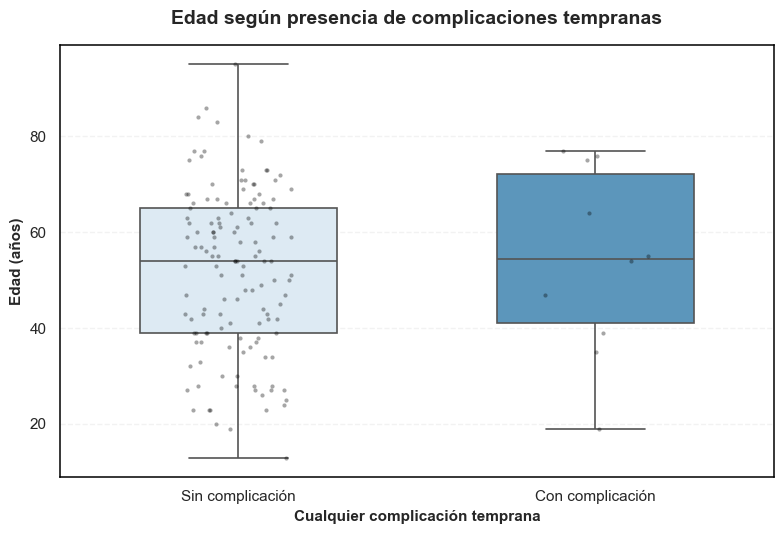

In [55]:
grafico_caja("EDAD", "Edad según presencia de complicaciones tempranas", "Edad (años)")

In [56]:
prueba_mann_whitney("EDAD", "Edad")

Prueba,n sin compl.,n con compl.,U,p,r biserial por rangos
Mann-Whitney U (bilateral),135,10,619.0,0.6649,0.083


En relación con la distribución de la edad según la presencia de complicaciones tempranas, se incluyeron 145 procedimientos evaluables, de los cuales 135 pertenecieron al grupo sin complicaciones y 10 al grupo con complicaciones. La mediana de edad fue de 54 años en los procedimientos sin complicaciones, con un rango intercuartílico de 39 a 65 años (RIC = 26 años), mientras que en el grupo con complicaciones la mediana fue de 54.5 años, con un rango intercuartílico de 41 a 72.25 años (RIC = 31.25 años). Estos resultados muestran medianas similares entre ambos grupos, con una diferencia de apenas 0.5 años. Sin embargo, el grupo con complicaciones presentó una mayor dispersión intercuartílica, aunque esta diferencia descriptiva debe interpretarse con cautela debido al reducido número de observaciones.

Para evaluar la asociación entre la edad y la presencia de complicaciones tempranas, se empleó la prueba no paramétrica de Mann-Whitney U, cuyo resultado no evidenció diferencias estadísticamente significativas entre las distribuciones de edad de ambos grupos ($U = 619.0$; $p = 0.6649$). Asimismo, se obtuvo una correlación biserial por rangos de $r = 0.083$, correspondiente a un tamaño del efecto muy pequeño. En conjunto, estos resultados no proporcionan evidencia estadística suficiente para establecer una asociación entre la edad y la aparición de complicaciones tempranas en esta cohorte. No obstante, la ausencia de significancia estadística no demuestra equivalencia entre los grupos, especialmente considerando el marcado desequilibrio en sus tamaños muestrales (135 frente a 10 procedimientos), que puede limitar la capacidad estadística para detectar diferencias de menor magnitud.

### 7.2. Tiempo quirúrgico según complicación temprana

In [57]:
resumen_cuantitativo("TIEMPO QUIRÚRGICO EN MINUTOS")

Grupo,n,Mediana,Q1,Q3,Mínimo,Máximo,RIC
Sin complicación,135,50.00,30.00,60.00,20.00,150.00,30.00
Con complicación,10,50.00,45.00,60.00,30.00,110.00,15.00


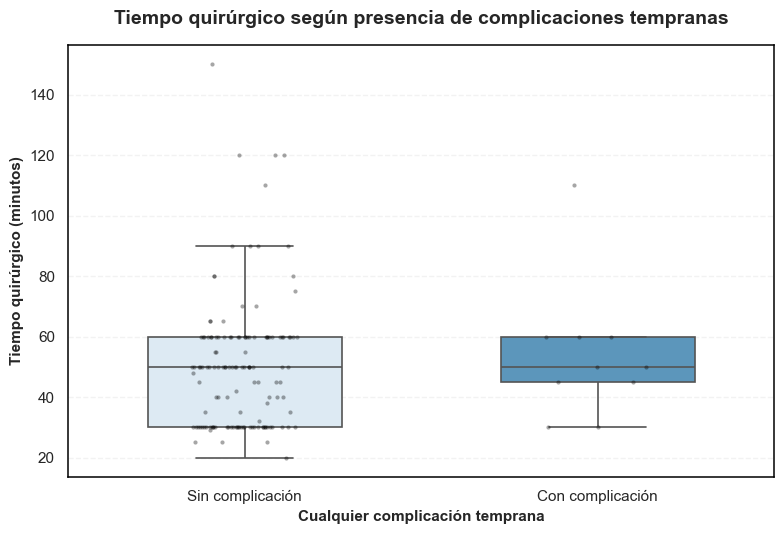

In [58]:
grafico_caja("TIEMPO QUIRÚRGICO EN MINUTOS",
             "Tiempo quirúrgico según presencia de complicaciones tempranas",
             "Tiempo quirúrgico (minutos)")

In [59]:
prueba_mann_whitney("TIEMPO QUIRÚRGICO EN MINUTOS", "Tiempo quirúrgico")

Prueba,n sin compl.,n con compl.,U,p,r biserial por rangos
Mann-Whitney U (bilateral),135,10,609.5,0.6052,0.097


En relación con la distribución del tiempo quirúrgico según la presencia de complicaciones tempranas, se analizaron 145 procedimientos evaluables, de los cuales 135 pertenecieron al grupo sin complicaciones y 10 al grupo con complicaciones. Ambos grupos presentaron una **mediana de 50 minutos**. En los procedimientos sin complicaciones, el rango intercuartílico se extendió de 30 a 60 minutos (RIC = 30 minutos), mientras que en aquellos con complicaciones se situó entre 45 y 60 minutos (RIC = 15 minutos). Estos resultados muestran una tendencia central idéntica, aunque con una menor dispersión intercuartílica en el grupo que presentó complicaciones. Asimismo, los tiempos quirúrgicos oscilaron entre 20 y 150 minutos en los procedimientos sin complicaciones, frente a un intervalo de 30 a 110 minutos en aquellos con complicaciones.

Para evaluar la asociación entre el tiempo quirúrgico y la presencia de complicaciones tempranas, se empleó la prueba no paramétrica de Mann-Whitney U, cuyo resultado no evidenció diferencias estadísticamente significativas entre las distribuciones de ambos grupos ($U = 609.5$; $p = 0.6052$). Asimismo, se obtuvo una correlación biserial por rangos de $r = 0.097$, correspondiente a un tamaño del efecto muy pequeño. En conjunto, estos resultados no proporcionan evidencia estadística suficiente para establecer una asociación entre la duración del procedimiento y la aparición de complicaciones tempranas en esta cohorte. No obstante, la ausencia de significancia estadística no demuestra equivalencia entre los grupos, especialmente considerando el marcado desequilibrio en sus tamaños muestrales (135 frente a 10 procedimientos), que puede limitar la capacidad estadística para detectar diferencias de menor magnitud.

### 7.3. Sexo según complicación temprana

Distribución de complicaciones tempranas según sexo:


Sexo,Sin complicación,Con complicación,Total,Complicación (%)
Femenino,87,5,92,5.4%
Masculino,48,5,53,9.4%
Total,135,10,145,6.9%


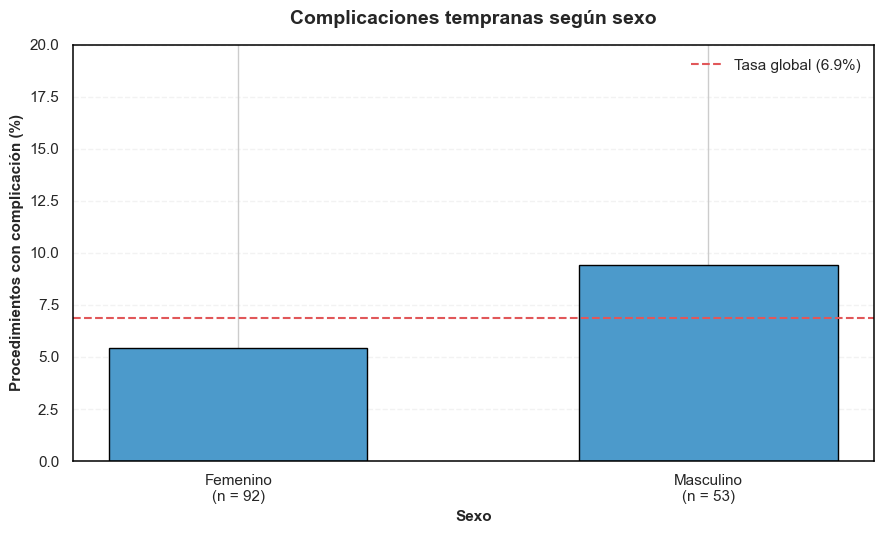

Prueba,Comparación,OR,IC95 %,p
Fisher exacta (bilateral),Masculino vs. Femenino (ref.),1.81,0.50 – 6.58,0.4977



Procedimientos incluidos en el análisis: 145
Procedimientos excluidos: 12


In [64]:
datos_sexo = df_spyglass[["SEXO", DESENLACE]].copy()

datos_sexo["SEXO"] = (
    datos_sexo["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

datos_sexo[DESENLACE] = (
    datos_sexo[DESENLACE]
    .astype("string")
    .str.strip()
    .str.upper()
)

datos_sexo = datos_sexo[
    datos_sexo["SEXO"].isin(["FEMENINO", "MASCULINO"])
    & datos_sexo[DESENLACE].isin(["NO", "SI"])
]

tabla_sexo = tabla_bivariada(
    datos_sexo,
    "SEXO",
    ["FEMENINO", "MASCULINO"]
)

print("Distribución de complicaciones tempranas según sexo:")

mostrar_tabla(
    tabla_sexo,
    "Sexo",
    etiquetas=["Femenino", "Masculino"]
)

grafico_proporciones(
    tabla_sexo,
    "Complicaciones tempranas según sexo",
    "Sexo",
    ["Femenino", "Masculino"]
)

prueba_fisher_2x2(
    tabla_sexo,
    "Sexo",
    "Masculino vs. Femenino (ref.)"
)

print(f"\nProcedimientos incluidos en el análisis: {len(datos_sexo)}")
print(f"Procedimientos excluidos: {len(df_spyglass) - len(datos_sexo)}")


En el análisis de las complicaciones tempranas según el sexo, se incluyeron 145 procedimientos evaluables, de los cuales 92 correspondieron a mujeres y 53 a hombres. Se registraron complicaciones en 5 procedimientos del grupo femenino (5.4%) y en 5 del masculino (9.4%), observándose una mayor frecuencia relativa de eventos en los hombres.

La prueba exacta de Fisher no evidenció una asociación estadísticamente significativa entre el sexo y la presencia de complicaciones tempranas ($p = 0.4977$). Aunque los hombres presentaron mayores odds de complicación respecto a las mujeres ($OR = 1.81$), el intervalo de confianza del 95% ($0.50 - 6.58$) incluye el valor de ausencia de asociación ($OR = 1$).

### 7.4. Dilatación de papila según complicación temprana

In [65]:
datos_papila = df_spyglass[["DILATACION DE PAPILA", DESENLACE]].dropna()
tabla_papila = tabla_bivariada(datos_papila, "DILATACION DE PAPILA", ["NO", "SI"])
mostrar_tabla(tabla_papila, "Dilatación de papila", etiquetas=["No", "Sí"])

Dilatación de papila,Sin complicación,Con complicación,Total,Complicación (%)
No,104,7,111,6.3%
Sí,31,3,34,8.8%
Total,135,10,145,6.9%


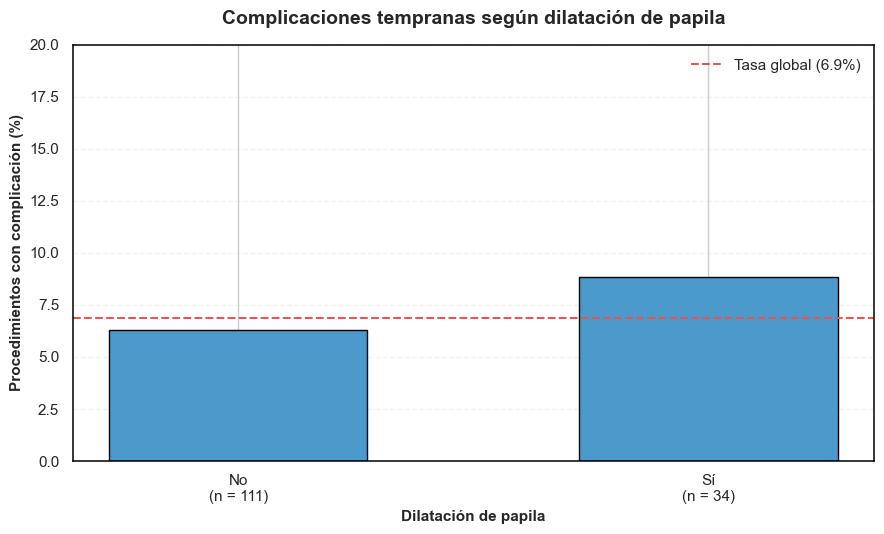

In [66]:
grafico_proporciones(tabla_papila, "Complicaciones tempranas según dilatación de papila",
                     "Dilatación de papila", ["No", "Sí"])

In [67]:
prueba_fisher_2x2(tabla_papila, "Dilatación de papila", "Sí vs. No (ref.)")

Prueba,Comparación,OR,IC95 %,p
Fisher exacta (bilateral),Sí vs. No (ref.),1.44,0.35 – 5.89,0.6995


En el análisis de las complicaciones tempranas según la dilatación de papila, se incluyeron 145 procedimientos evaluables. De los 111 procedimientos en los que no se realizó dilatación, 7 presentaron complicaciones (6.3%), mientras que en el grupo con dilatación se registraron 3 complicaciones entre 34 procedimientos (8.8%). Se observa una frecuencia ligeramente mayor de eventos en los procedimientos con dilatación, con una diferencia de 2.5 puntos porcentuales entre ambos grupos.

La prueba exacta de Fisher no evidenció una asociación estadísticamente significativa entre la dilatación de papila y la presencia de complicaciones tempranas ($p = 0.6995$). Aunque el grupo con dilatación presentó mayores odds de complicación ($OR = 1.44$), el intervalo de confianza del 95% ($0.35 - 5.89$) incluye el valor de ausencia de asociación ($OR = 1$). Por tanto, los resultados no muestran evidencia estadística suficiente para establecer una relación entre la dilatación de papila y la aparición de complicaciones tempranas en los procedimientos analizados.

### 7.5. Número de procedimientos según complicación temprana

In [68]:
datos_proc = df_spyglass[["NUMERO DE PROCEDIMIENTOS", DESENLACE]].dropna()
tabla_proc = tabla_bivariada(datos_proc, "NUMERO DE PROCEDIMIENTOS", [1.0, 2.0, 3.0])
mostrar_tabla(tabla_proc, "Número de procedimientos", etiquetas=["1", "2", "3"])

Número de procedimientos,Sin complicación,Con complicación,Total,Complicación (%)
1,119,8,127,6.3%
2,12,2,14,14.3%
3,4,0,4,0.0%
Total,135,10,145,6.9%


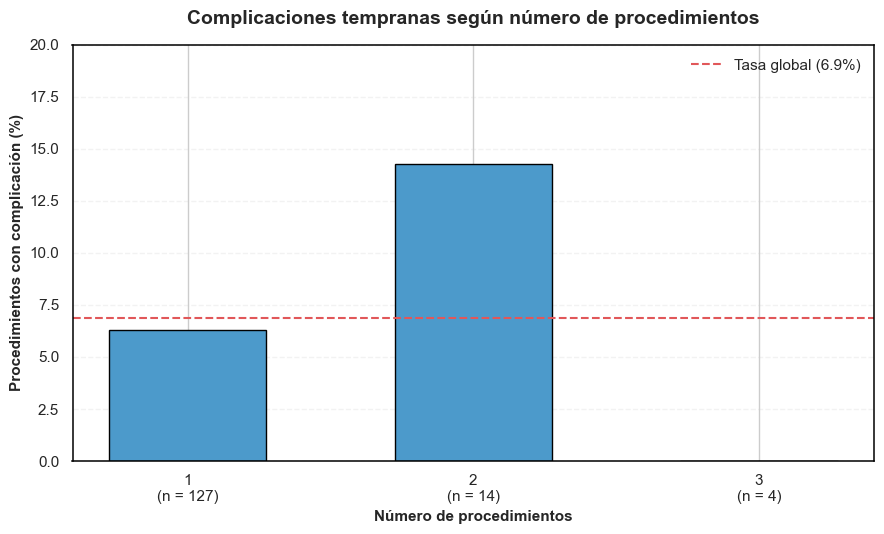

In [69]:
grafico_proporciones(tabla_proc, "Complicaciones tempranas según número de procedimientos",
                     "Número de procedimientos", ["1", "2", "3"])

En el análisis de las complicaciones tempranas según el número de procedimientos, se incluyeron 145 registros evaluables. De los 127 registros correspondientes a un procedimiento, 8 presentaron complicaciones (6.3%). En aquellos con dos procedimientos se identificaron 2 complicaciones entre 14 registros (14.3%), mientras que en los 4 registros correspondientes a tres procedimientos no se observaron eventos.

La mayor frecuencia relativa de complicaciones se presentó en el grupo de dos procedimientos, con una diferencia de 8 puntos porcentuales respecto al grupo de un procedimiento. Por su parte, el grupo de tres procedimientos no registró complicaciones, aunque estuvo conformado únicamente por 4 observaciones.

In [71]:
from scipy.stats import chi2_contingency, random_table
import numpy as np
import pandas as pd

observados = tabla_proc.to_numpy()

_, _, _, esperadas = chi2_contingency(
    observados,
    correction=False
)

tabla_esperadas = pd.DataFrame(
    esperadas,
    index=tabla_proc.index,
    columns=["Sin complicación", "Con complicación"]
)

tabla_esperadas.index.name = "Número de procedimientos"

estilos_tabla = [
    {
        "selector": "table",
        "props": [
            ("margin", "0 auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
]

styled_esperadas = (
    tabla_esperadas.reset_index().style
    .hide(axis="index")
    .format({
        "Sin complicación": "{:.2f}",
        "Con complicación": "{:.2f}"
    })
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Número de procedimientos"],
        **{"text-align": "left"}
    )
)

print("Frecuencias esperadas bajo independencia:")
display(styled_esperadas)

n_celdas_bajas = int((esperadas < 5).sum())

print(
    f"\nCeldas con frecuencia esperada < 5: "
    f"{n_celdas_bajas} de {esperadas.size} "
    f"(mínima = {esperadas.min():.2f})."
)

estadistico_observado = (
    (observados - esperadas) ** 2 / esperadas
).sum()

n_simulaciones = 100_000
rng = np.random.default_rng(12345)

simulados = random_table.rvs(
    observados.sum(axis=1),
    observados.sum(axis=0),
    size=n_simulaciones,
    random_state=rng
)

estadisticos_simulados = (
    (simulados - esperadas) ** 2 / esperadas
).sum(axis=(1, 2))

p_montecarlo = (
    1 + np.count_nonzero(
        estadisticos_simulados >= estadistico_observado - 1e-12
    )
) / (n_simulaciones + 1)

resultados_bivariados["Número de procedimientos"] = {
    "Variable": "Número de procedimientos",
    "Prueba": "Chi-cuadrado (Monte Carlo, márgenes fijos)",
    "Estadístico": estadistico_observado,
    "p": p_montecarlo,
    "OR": np.nan,
    "IC95% inf": np.nan,
    "IC95% sup": np.nan,
    "r": np.nan
}

tabla_resultado_proc = pd.DataFrame([{
    "Prueba": "Chi-cuadrado con Monte Carlo",
    "Estadístico": estadistico_observado,
    "Simulaciones": n_simulaciones,
    "p": p_montecarlo
}])

styled_resultado_proc = (
    tabla_resultado_proc.style
    .hide(axis="index")
    .format({
        "Estadístico": "{:.3f}",
        "Simulaciones": "{:.0f}",
        "p": "{:.4f}"
    })
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Prueba"],
        **{"text-align": "left"}
    )
)

print("\nPrueba de independencia mediante Monte Carlo:")
display(styled_resultado_proc)

Frecuencias esperadas bajo independencia:


Número de procedimientos,Sin complicación,Con complicación
1.000000,118.24,8.76
2.000000,13.03,0.97
3.000000,3.72,0.28



Celdas con frecuencia esperada < 5: 3 de 6 (mínima = 0.28).

Prueba de independencia mediante Monte Carlo:


Prueba,Estadístico,Simulaciones,p
Chi-cuadrado con Monte Carlo,1.557,100000,0.4445


Para evaluar la asociación entre el número de procedimientos y la presencia de complicaciones tempranas, se revisaron las frecuencias esperadas bajo la hipótesis de independencia. Se identificaron 3 de 6 celdas con frecuencias esperadas inferiores a 5, siendo el valor mínimo de 0.28. Debido a que no se cumplían los supuestos de la aproximación habitual de chi-cuadrado, se utilizó una prueba de independencia con simulación de Monte Carlo y márgenes fijos, mediante 100.000 simulaciones.

El análisis obtuvo un estadístico de chi-cuadrado de $1.557$ y un valor de $p = 0.4445$, por lo que no se encontró una asociación estadísticamente significativa entre el número de procedimientos y la presencia de complicaciones tempranas. Aunque descriptivamente se observó una mayor proporción de eventos en el grupo de dos procedimientos, esta diferencia no fue estadísticamente significativa.


### 7.6. Uso de prótesis biliar según complicación temprana

In [72]:
datos_protesis = df_spyglass.loc[es_si_no, ["USO DE PROTESIS BILIAR", DESENLACE]].dropna()
tabla_protesis = tabla_bivariada(datos_protesis, "USO DE PROTESIS BILIAR", ["NO", "SI"])
mostrar_tabla(tabla_protesis, "Uso de prótesis biliar", etiquetas=["No", "Sí"])

Uso de prótesis biliar,Sin complicación,Con complicación,Total,Complicación (%)
No,33,5,38,13.2%
Sí,99,5,104,4.8%
Total,132,10,142,7.0%


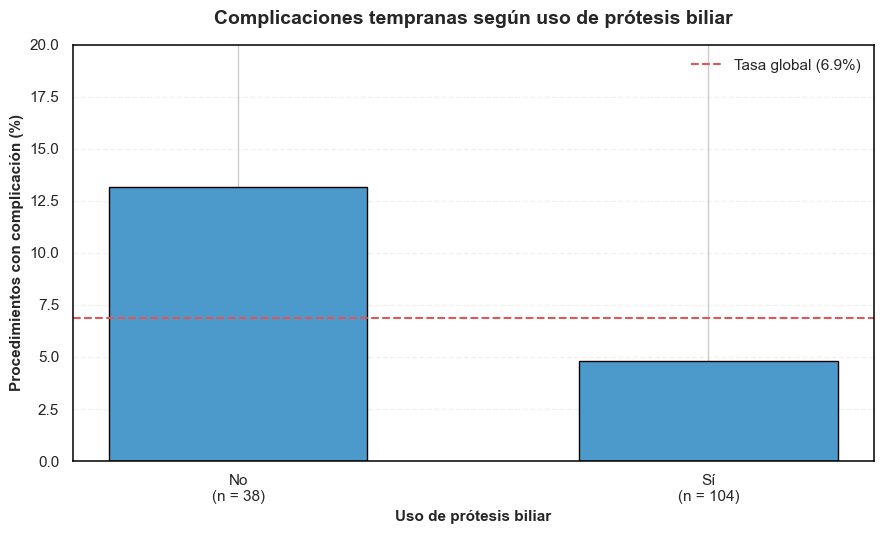

In [73]:
grafico_proporciones(tabla_protesis, "Complicaciones tempranas según uso de prótesis biliar",
                     "Uso de prótesis biliar", ["No", "Sí"])

En el análisis de las complicaciones tempranas según el uso de prótesis biliar, se incluyeron 142 procedimientos evaluables. De los 38 procedimientos en los que no se utilizó prótesis, 5 presentaron complicaciones (13.2%), mientras que en los 104 procedimientos con prótesis también se registraron 5 eventos (4.8%).

La frecuencia de complicaciones fue mayor en los procedimientos sin prótesis biliar, con una diferencia de 8.4 puntos porcentuales respecto al grupo en el que sí se utilizó. A pesar de registrar el mismo número de complicaciones, ambos grupos presentan proporciones diferentes debido a sus tamaños.

In [74]:
prueba_fisher_2x2(tabla_protesis, "Uso de prótesis biliar", "Sí vs. No (ref.)")

Prueba,Comparación,OR,IC95 %,p
Fisher exacta (bilateral),Sí vs. No (ref.),0.33,0.09 – 1.22,0.1318


Para evaluar la asociación entre el uso de prótesis biliar y la presencia de complicaciones tempranas, se aplicó la prueba exacta de Fisher. El análisis obtuvo un valor de $p = 0.1318$, sin evidenciar una asociación estadísticamente significativa entre ambas variables.

Los procedimientos con prótesis biliar presentaron menores odds de complicación respecto a aquellos sin prótesis ($OR = 0.33$). Sin embargo, el intervalo de confianza del 95% ($0.09 - 1.22$) incluye el valor de ausencia de asociación ($OR = 1$). Por tanto, aunque descriptivamente se observa una menor frecuencia de complicaciones en los procedimientos con prótesis, esta diferencia no alcanzó significancia estadística.

### 7.7. Resumen inferencial y corrección por comparaciones múltiples

Dado que se realizaron seis pruebas sobre el mismo desenlace, los valores p se ajustan mediante el método de Holm para controlar la tasa de error de tipo I global.

In [76]:
tabla_inferencial = pd.DataFrame(list(resultados_bivariados.values()))

_, p_holm, _, _ = multipletests(
    tabla_inferencial["p"],
    method="holm"
)

tabla_inferencial["p (Holm)"] = p_holm

styled_inferencial = (
    tabla_inferencial.style
    .hide(axis="index")
    .format({
        "Estadístico": "{:.4g}",
        "p": "{:.4f}",
        "p (Holm)": "{:.4f}",
        "OR": "{:.2f}",
        "IC95% inf": "{:.2f}",
        "IC95% sup": "{:.2f}",
        "r": "{:.3f}"
    }, na_rep="—")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Variable", "Prueba"],
        **{"text-align": "left"}
    )
)

print("Resumen de pruebas bivariadas con corrección de Holm:")
display(styled_inferencial)

Resumen de pruebas bivariadas con corrección de Holm:


Variable,Prueba,Estadístico,p,OR,IC95% inf,IC95% sup,r,p (Holm)
Edad,Mann-Whitney U,619,0.6649,—,—,—,0.083,1.0000
Tiempo quirúrgico,Mann-Whitney U,609.5,0.6052,—,—,—,0.097,1.0000
Sexo,Fisher exacta,—,0.4977,1.81,0.50,6.58,—,1.0000
Dilatación de papila,Fisher exacta,—,0.6995,1.44,0.35,5.89,—,1.0000
Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",1.557,0.4445,—,—,—,—,1.0000
Uso de prótesis biliar,Fisher exacta,—,0.1318,0.33,0.09,1.22,—,0.7907


En el análisis bivariado de las complicaciones tempranas se evaluaron seis variables clínicas y procedimentales. Ninguna presentó una asociación estadísticamente significativa, tanto con los valores de $p$ originales como después de aplicar la corrección de Holm por comparaciones múltiples. El menor valor ajustado correspondió al uso de prótesis biliar ($p_{\text{Holm}} = 0.7907$), mientras que las demás variables presentaron valores ajustados de $1.0000$.

Las pruebas realizadas no identificaron asociaciones estadísticamente significativas entre las variables evaluadas y la presencia de complicaciones tempranas en los 145 procedimientos analizados.

### 7.8. Desenlaces con potencia suficiente: resolución del cuadro, reintervenciones y fracaso terapéutico (Familia 2)

In [77]:
VARIABLES_CUANTITATIVAS_OE6 = {
    "Edad": encontrar_columna(df_spyglass, ["EDAD"]),
    "Tiempo quirúrgico": COL_TIEMPO,
}
VARIABLES_CATEGORICAS_OE6 = {
    "Sexo": (encontrar_columna(df_spyglass, ["SEXO"]), ["FEMENINO", "MASCULINO"]),
    "Dilatación de papila": (COL_PAPILA, ["NO", "SI"]),
    "Uso de prótesis biliar (de novo)": ("PROTESIS_DE_NOVO_BINARIA", ["NO", "SI"]),
}

In [80]:
VARIABLES_CATEGORICAS_OE6["Sexo"] = (
    "SEXO_OE6",
    ["FEMENINO", "MASCULINO"]
)

df_spyglass["SEXO_OE6"] = (
    df_spyglass["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Distribución de sexo normalizada:")

display(
    df_spyglass["SEXO_OE6"]
    .value_counts(dropna=False)
    .rename_axis("Sexo")
    .reset_index(name="Registros")
    .style
    .hide(axis="index")
    .set_table_styles(estilos_tabla)
    .set_properties(
        subset=["Sexo"],
        **{"text-align": "left"}
    )
)

Distribución de sexo normalizada:


Sexo,Registros
FEMENINO,100
MASCULINO,57


In [82]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, fisher_exact, chi2_contingency, random_table
from statsmodels.stats.multitest import multipletests

def decidir_prueba_categorica(tabla, etiqueta="", n_simulaciones=100_000):

    tabla = tabla.loc[
        tabla.sum(axis=1) > 0,
        tabla.sum(axis=0) > 0
    ]

    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return {
            "Prueba": "No aplicable",
            "Estadistico": np.nan,
            "p": np.nan,
            "OR": np.nan,
            "IC95% inf": np.nan,
            "IC95% sup": np.nan
        }

    observados = tabla.to_numpy(dtype=int)

    if tabla.shape == (2, 2):

        _, p_val = fisher_exact(
            observados,
            alternative="two-sided"
        )

        (a, b), (c, d) = observados.astype(float)

        if min(a, b, c, d) == 0:
            a += 0.5
            b += 0.5
            c += 0.5
            d += 0.5

        or_ = (a * d) / (b * c)

        ee = np.sqrt(
            1 / a + 1 / b + 1 / c + 1 / d
        )

        ic_inf = np.exp(
            np.log(or_) - 1.96 * ee
        )

        ic_sup = np.exp(
            np.log(or_) + 1.96 * ee
        )

        return {
            "Prueba": "Fisher exacta",
            "Estadistico": np.nan,
            "p": float(p_val),
            "OR": float(or_),
            "IC95% inf": float(ic_inf),
            "IC95% sup": float(ic_sup)
        }

    _, _, _, esperadas = chi2_contingency(
        observados,
        correction=False
    )

    estadistico = float(
        ((observados - esperadas) ** 2 / esperadas).sum()
    )

    rng = np.random.default_rng(12345)

    simulados = random_table.rvs(
        observados.sum(axis=1),
        observados.sum(axis=0),
        size=n_simulaciones,
        random_state=rng
    )

    estadisticos_simulados = (
        (simulados - esperadas) ** 2 / esperadas
    ).sum(axis=(1, 2))

    p_val = (
        1 + np.count_nonzero(
            estadisticos_simulados >= estadistico - 1e-12
        )
    ) / (n_simulaciones + 1)

    return {
        "Prueba": "Chi-cuadrado (Monte Carlo, márgenes fijos)",
        "Estadistico": estadistico,
        "p": float(p_val),
        "OR": np.nan,
        "IC95% inf": np.nan,
        "IC95% sup": np.nan
    }


def analizar_desenlace(df, columna_desenlace, nombre_desenlace):

    resultados = []

    for nombre_var, col_var in VARIABLES_CUANTITATIVAS_OE6.items():

        datos = df[[col_var, columna_desenlace]].copy()

        datos[col_var] = pd.to_numeric(
            datos[col_var],
            errors="coerce"
        )

        datos = datos.dropna()
        datos = datos[
            datos[columna_desenlace].isin(["SI", "NO"])
        ]

        g_no = datos.loc[
            datos[columna_desenlace] == "NO",
            col_var
        ]

        g_si = datos.loc[
            datos[columna_desenlace] == "SI",
            col_var
        ]

        if len(g_no) < 2 or len(g_si) < 2:
            continue

        u, p = mannwhitneyu(
            g_no,
            g_si,
            alternative="two-sided"
        )

        r_eff = 1 - 2 * u / (
            len(g_no) * len(g_si)
        )

        resultados.append({
            "Variable": nombre_var,
            "Prueba": "Mann-Whitney U",
            "n NO": len(g_no),
            "n SI": len(g_si),
            "Mediana NO": float(g_no.median()),
            "Mediana SI": float(g_si.median()),
            "Estadistico": float(u),
            "p": float(p),
            "OR": np.nan,
            "IC95% inf": np.nan,
            "IC95% sup": np.nan,
            "r (efecto)": float(r_eff)
        })

    for nombre_var, (col_var, orden) in VARIABLES_CATEGORICAS_OE6.items():

        datos = df[[col_var, columna_desenlace]].dropna()

        datos = datos[
            datos[columna_desenlace].isin(["SI", "NO"])
        ]

        tabla = pd.crosstab(
            datos[col_var],
            datos[columna_desenlace]
        ).reindex(
            index=orden,
            columns=["NO", "SI"],
            fill_value=0
        )

        if tabla.values.sum() == 0:
            continue

        r = decidir_prueba_categorica(
            tabla,
            etiqueta=f"{nombre_var} vs {nombre_desenlace}"
        )

        if pd.isna(r["p"]):
            continue

        resultados.append({
            "Variable": nombre_var,
            "Prueba": r["Prueba"],
            "n NO": int(tabla["NO"].sum()),
            "n SI": int(tabla["SI"].sum()),
            "Mediana NO": np.nan,
            "Mediana SI": np.nan,
            "Estadistico": r["Estadistico"],
            "p": r["p"],
            "OR": r["OR"],
            "IC95% inf": r["IC95% inf"],
            "IC95% sup": r["IC95% sup"],
            "r (efecto)": np.nan
        })

    datos_proc = df[
        [COL_NUM_PROCEDIMIENTOS, columna_desenlace]
    ].copy()

    datos_proc[COL_NUM_PROCEDIMIENTOS] = pd.to_numeric(
        datos_proc[COL_NUM_PROCEDIMIENTOS],
        errors="coerce"
    )

    datos_proc = datos_proc.dropna()

    datos_proc = datos_proc[
        datos_proc[columna_desenlace].isin(["SI", "NO"])
    ]

    tabla_proc = pd.crosstab(
        datos_proc[COL_NUM_PROCEDIMIENTOS],
        datos_proc[columna_desenlace]
    ).reindex(
        columns=["NO", "SI"],
        fill_value=0
    )

    if tabla_proc.shape[0] >= 2 and tabla_proc.values.sum() > 0:

        r = decidir_prueba_categorica(
            tabla_proc,
            etiqueta=f"Núm. procedimientos vs {nombre_desenlace}"
        )

        if pd.notna(r["p"]):

            resultados.append({
                "Variable": "Número de procedimientos",
                "Prueba": r["Prueba"],
                "n NO": int(tabla_proc["NO"].sum()),
                "n SI": int(tabla_proc["SI"].sum()),
                "Mediana NO": np.nan,
                "Mediana SI": np.nan,
                "Estadistico": r["Estadistico"],
                "p": r["p"],
                "OR": r["OR"],
                "IC95% inf": r["IC95% inf"],
                "IC95% sup": r["IC95% sup"],
                "r (efecto)": np.nan
            })

    datos_ind = df[
        ["TIPO_INDICACION_CALCULO_ESTENOSIS", columna_desenlace]
    ].dropna()

    datos_ind = datos_ind[
        datos_ind[columna_desenlace].isin(["SI", "NO"])
    ]

    datos_ind = datos_ind[
        datos_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"].isin([
            "Cálculo",
            "Estenosis"
        ])
    ]

    tabla_ind = pd.crosstab(
        datos_ind["TIPO_INDICACION_CALCULO_ESTENOSIS"],
        datos_ind[columna_desenlace]
    ).reindex(
        index=["Cálculo", "Estenosis"],
        columns=["NO", "SI"],
        fill_value=0
    )

    if tabla_ind.values.sum() > 0:

        r = decidir_prueba_categorica(
            tabla_ind,
            etiqueta=f"Indicación vs {nombre_desenlace}"
        )

        if pd.notna(r["p"]):

            resultados.append({
                "Variable": "Indicación (Cálculo vs. Estenosis)",
                "Prueba": r["Prueba"],
                "n NO": int(tabla_ind["NO"].sum()),
                "n SI": int(tabla_ind["SI"].sum()),
                "Mediana NO": np.nan,
                "Mediana SI": np.nan,
                "Estadistico": r["Estadistico"],
                "p": r["p"],
                "OR": r["OR"],
                "IC95% inf": r["IC95% inf"],
                "IC95% sup": r["IC95% sup"],
                "r (efecto)": np.nan
            })

    columnas_resultado = [
        "Desenlace",
        "Variable",
        "Prueba",
        "n NO",
        "n SI",
        "Mediana NO",
        "Mediana SI",
        "Estadistico",
        "p",
        "OR",
        "IC95% inf",
        "IC95% sup",
        "r (efecto)"
    ]

    tabla_final = pd.DataFrame(resultados)

    tabla_final.insert(
        0,
        "Desenlace",
        nombre_desenlace
    )

    return tabla_final.reindex(columns=columnas_resultado)


resultados_por_desenlace = {}

for nombre_desenlace in DESENLACES_VIABLES:

    col = COLUMNAS_OE6[nombre_desenlace]

    tabla = analizar_desenlace(
        df_spyglass,
        col,
        nombre_desenlace
    )

    if tabla.empty:
        continue

    tabla["p (Holm)"] = np.nan

    mask_p = tabla["p"].notna()

    if mask_p.any():

        tabla.loc[mask_p, "p (Holm)"] = multipletests(
            tabla.loc[mask_p, "p"],
            method="holm"
        )[1]

    resultados_por_desenlace[nombre_desenlace] = tabla


if resultados_por_desenlace:

    tabla_consolidada = pd.concat(
        resultados_por_desenlace.values(),
        ignore_index=True
    )

    styled_consolidada = (
        tabla_consolidada.style
        .hide(axis="index")
        .format({
            "n NO": "{:.0f}",
            "n SI": "{:.0f}",
            "Mediana NO": "{:.1f}",
            "Mediana SI": "{:.1f}",
            "Estadistico": "{:.3g}",
            "p": "{:.4f}",
            "p (Holm)": "{:.4f}",
            "OR": "{:.2f}",
            "IC95% inf": "{:.2f}",
            "IC95% sup": "{:.2f}",
            "r (efecto)": "{:.3f}"
        }, na_rep="—")
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("margin", "0 auto"),
                    ("width", "auto"),
                    ("border-collapse", "collapse")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("text-align", "center"),
                    ("background-color", "#f2f2f2"),
                    ("color", "black"),
                    ("font-weight", "bold"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            }
        ])
        .set_properties(
            subset=["Desenlace", "Variable", "Prueba"],
            **{"text-align": "left"}
        )
    )

    print("Resultados inferenciales consolidados del OE6:")
    display(styled_consolidada)

else:

    tabla_consolidada = pd.DataFrame()

    print(
        "No se obtuvieron resultados inferenciales evaluables."
    )          

Resultados inferenciales consolidados del OE6:


Desenlace,Variable,Prueba,n NO,n SI,Mediana NO,Mediana SI,Estadistico,p,OR,IC95% inf,IC95% sup,r (efecto),p (Holm)
Resolución del cuadro,Edad,Mann-Whitney U,21,125,53.0,54.0,1.15e+03,0.3574,—,—,—,0.126,1.0000
Resolución del cuadro,Tiempo quirúrgico,Mann-Whitney U,21,125,50.0,50.0,1.41e+03,0.5737,—,—,—,-0.076,1.0000
Resolución del cuadro,Sexo,Fisher exacta,21,125,—,—,—,0.0508,0.38,0.15,0.97,—,0.2538
Resolución del cuadro,Dilatación de papila,Fisher exacta,21,125,—,—,—,0.0277,7.17,0.93,55.58,—,0.1665
Resolución del cuadro,Uso de prótesis biliar (de novo),Fisher exacta,20,123,—,—,—,1.0000,0.91,0.31,2.70,—,1.0000
Resolución del cuadro,Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",21,125,—,—,3.09,0.2290,—,—,—,—,0.9158
Resolución del cuadro,Indicación (Cálculo vs. Estenosis),Fisher exacta,19,116,—,—,—,0.0005,0.16,0.06,0.45,—,0.0038
Reintervenciones,Edad,Mann-Whitney U,96,49,54.0,54.0,2.26e+03,0.7129,—,—,—,0.038,1.0000
Reintervenciones,Tiempo quirúrgico,Mann-Whitney U,96,49,50.0,50.0,2.04e+03,0.1819,—,—,—,0.134,0.9094
Reintervenciones,Sexo,Fisher exacta,96,49,—,—,—,0.7181,1.15,0.57,2.35,—,1.0000


El análisis inferencial de la resolución del cuadro clínico identificó una asociación estadísticamente significativa con el tipo de indicación del procedimiento. La resolución se alcanzó en el 92.2% de los procedimientos indicados por cálculo (95/103), frente al 65.6% de aquellos indicados por estenosis (21/32). Esta diferencia se mantuvo después de la corrección de Holm (p = 0.0038), lo que evidencia una mayor proporción de resolución clínica en los procedimientos realizados por cálculo.

La dilatación de papila también presentó una asociación inicial con la resolución del cuadro (OR = 7.17; p = 0.0277), aunque perdió significancia después del ajuste por comparaciones múltiples (p = 0.1665). Por su parte, el sexo mostró un resultado cercano al umbral convencional de significancia (OR = 0.38; p = 0.0508), sin mantenerse significativo tras la corrección (p = 0.2538). La edad y el tiempo quirúrgico tampoco presentaron diferencias estadísticamente significativas entre los procedimientos con y sin resolución.

En cuanto a las reintervenciones, se observaron dos asociaciones en el análisis sin ajustar. El tipo de indicación presentó un OR de 3.04 (IC95%: 1.34–6.88; p = 0.0096), mientras que el número de procedimientos mostró diferencias en su distribución según la necesidad de reintervención (χ² = 7.30; p = 0.0288). Sin embargo, ninguna de estas asociaciones conservó significancia después de aplicar Holm (p = 0.0675 y p = 0.1727, respectivamente). Las demás variables evaluadas tampoco mostraron asociaciones estadísticamente significativas con las reintervenciones.

Para el fracaso terapéutico, ninguna de las variables analizadas presentó asociaciones estadísticamente significativas, incluso antes del ajuste por comparaciones múltiples. El tiempo quirúrgico registró el menor valor p entre las variables cuantitativas (p = 0.0940), aunque ambos grupos presentaron una mediana de 50 minutos. Asimismo, el tipo de indicación mostró un OR de 2.15 (IC95%: 0.87–5.30; p = 0.1323), sin evidencia estadística suficiente para establecer una asociación con este desenlace.

Los resultados identifican al tipo de indicación clínica como la variable con mayor evidencia de asociación con la resolución del cuadro. Los procedimientos indicados por cálculo presentaron una proporción de resolución 26.6 puntos porcentuales superior a los indicados por estenosis. En contraste, las asociaciones inicialmente observadas con las reintervenciones no se mantuvieron después de la corrección por comparaciones múltiples, y no se identificaron asociaciones estadísticamente significativas con el fracaso terapéutico.

In [83]:
col = COLUMNAS_OE6["Resolución del cuadro"]

tabla_verificacion = pd.crosstab(
    df_spyglass["TIPO_INDICACION_CALCULO_ESTENOSIS"],
    df_spyglass[col]
).reindex(
    index=["Cálculo", "Estenosis"],
    columns=["NO", "SI"],
    fill_value=0
)

tabla_verificacion["Total"] = tabla_verificacion.sum(axis=1)

tabla_verificacion["Resolución (%)"] = (
    tabla_verificacion["SI"]
    / tabla_verificacion["Total"] * 100
)

display(
    tabla_verificacion.reset_index()
    .style.hide(axis="index")
    .format({"Resolución (%)": "{:.1f}%"})
    .set_table_styles(estilos_tabla)
)

TIPO_INDICACION_CALCULO_ESTENOSIS,NO,SI,Total,Resolución (%)
Cálculo,8,95,103,92.2%
Estenosis,11,21,32,65.6%


La resolución del cuadro clínico presentó diferencias según el tipo de indicación. En los procedimientos indicados por cálculo, el 92.2% alcanzó resolución (95/103), frente al 65.6% de aquellos indicados por estenosis (21/32). Esta asociación fue estadísticamente significativa incluso después de la corrección de Holm (p = 0.0038). Los resultados muestran una mayor proporción de resolución en los procedimientos indicados por cálculo, con una diferencia de 26.6 puntos porcentuales respecto a los indicados por estenosis.

In [85]:
resultados_por_desenlace = {}

for nombre_desenlace in DESENLACES_VIABLES:
    col = COLUMNAS_OE6[nombre_desenlace]

    print(f"\nDESENLACE: {nombre_desenlace.upper()}")

    tabla = analizar_desenlace(df_spyglass, col, nombre_desenlace)
    tabla_con_holm = aplicar_holm(tabla, columna_p="p")

    resultados_por_desenlace[nombre_desenlace] = tabla_con_holm

    display(
        tabla_con_holm.style
        .hide(axis="index")
        .format(
            {
                "n NO": "{:.0f}",
                "n SI": "{:.0f}",
                "Mediana NO": "{:.1f}",
                "Mediana SI": "{:.1f}",
                "Estadistico": "{:.4g}",
                "p": "{:.4f}",
                "OR": "{:.2f}",
                "IC95% inf": "{:.2f}",
                "IC95% sup": "{:.2f}",
                "r (efecto)": "{:.3f}",
                "p (Holm)": "{:.4f}"
            },
            na_rep="—"
        )
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#f2f2f2"),
                    ("color", "black"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("border", "1px solid black"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("width", "100%"),
                    ("margin", "15px 0")
                ]
            }
        ])
        .set_properties(
            subset=["Variable", "Prueba"],
            **{"text-align": "left"}
        )
    )

tabla_consolidada = pd.concat(
    resultados_por_desenlace.values(),
    ignore_index=True
)


DESENLACE: RESOLUCIÓN DEL CUADRO


Desenlace,Variable,Prueba,n NO,n SI,Mediana NO,Mediana SI,Estadistico,p,OR,IC95% inf,IC95% sup,r (efecto),p (Holm)
Resolución del cuadro,Edad,Mann-Whitney U,21,125,53.0,54.0,1147,0.3574,—,—,—,0.126,1.0000
Resolución del cuadro,Tiempo quirúrgico,Mann-Whitney U,21,125,50.0,50.0,1412,0.5737,—,—,—,-0.076,1.0000
Resolución del cuadro,Sexo,Fisher exacta,21,125,—,—,—,0.0508,0.38,0.15,0.97,—,0.2538
Resolución del cuadro,Dilatación de papila,Fisher exacta,21,125,—,—,—,0.0277,7.17,0.93,55.58,—,0.1665
Resolución del cuadro,Uso de prótesis biliar (de novo),Fisher exacta,20,123,—,—,—,1.0000,0.91,0.31,2.70,—,1.0000
Resolución del cuadro,Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",21,125,—,—,3.087,0.2290,—,—,—,—,0.9158
Resolución del cuadro,Indicación (Cálculo vs. Estenosis),Fisher exacta,19,116,—,—,—,0.0005,0.16,0.06,0.45,—,0.0038



DESENLACE: REINTERVENCIONES


Desenlace,Variable,Prueba,n NO,n SI,Mediana NO,Mediana SI,Estadistico,p,OR,IC95% inf,IC95% sup,r (efecto),p (Holm)
Reintervenciones,Edad,Mann-Whitney U,96,49,54.0,54.0,2264,0.7129,—,—,—,0.038,1.0000
Reintervenciones,Tiempo quirúrgico,Mann-Whitney U,96,49,50.0,50.0,2038,0.1819,—,—,—,0.134,0.9094
Reintervenciones,Sexo,Fisher exacta,96,49,—,—,—,0.7181,1.15,0.57,2.35,—,1.0000
Reintervenciones,Dilatación de papila,Fisher exacta,96,49,—,—,—,1.0000,0.92,0.41,2.08,—,1.0000
Reintervenciones,Uso de prótesis biliar (de novo),Fisher exacta,95,47,—,—,—,0.4204,1.47,0.64,3.36,—,1.0000
Reintervenciones,Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",96,49,—,—,7.298,0.0288,—,—,—,—,0.1727
Reintervenciones,Indicación (Cálculo vs. Estenosis),Fisher exacta,90,45,—,—,—,0.0096,3.04,1.34,6.88,—,0.0675



DESENLACE: FRACASO TERAPÉUTICO


Desenlace,Variable,Prueba,n NO,n SI,Mediana NO,Mediana SI,Estadistico,p,OR,IC95% inf,IC95% sup,r (efecto),p (Holm)
Fracaso terapéutico,Edad,Mann-Whitney U,117,29,54.0,55.0,1620,0.7111,—,—,—,0.045,1.0000
Fracaso terapéutico,Tiempo quirúrgico,Mann-Whitney U,117,29,50.0,50.0,1361,0.0940,—,—,—,0.198,0.6581
Fracaso terapéutico,Sexo,Fisher exacta,117,29,—,—,—,0.1981,1.80,0.79,4.09,—,0.9905
Fracaso terapéutico,Dilatación de papila,Fisher exacta,117,29,—,—,—,0.2242,0.46,0.15,1.44,—,0.9905
Fracaso terapéutico,Uso de prótesis biliar (de novo),Fisher exacta,115,28,—,—,—,0.8135,0.88,0.35,2.21,—,1.0000
Fracaso terapéutico,Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",117,29,—,—,2.565,0.3242,—,—,—,—,0.9905
Fracaso terapéutico,Indicación (Cálculo vs. Estenosis),Fisher exacta,107,28,—,—,—,0.1323,2.15,0.87,5.30,—,0.7936


**1. Resolución del cuadro clínico**

La resolución del cuadro clínico se registró en 125 de los 146 procedimientos evaluables (85.6%). El tipo de indicación presentó la asociación más importante: el 92.2% de los procedimientos indicados por cálculo alcanzó resolución (95/103), frente al 65.6% de los indicados por estenosis (21/32). Esta diferencia de 26.6 puntos porcentuales fue estadísticamente significativa después de la corrección de Holm (p = 0.0038).

La dilatación de papila presentó una asociación en el análisis sin ajustar (OR = 7.17; p = 0.0277), pero no conservó significancia después de Holm (p = 0.1665). El sexo mostró un OR de 0.38 (IC95%: 0.15–0.97), con un valor p de Fisher de 0.0508 y un valor ajustado de 0.2538. La edad presentó medianas de 53 y 54 años en los grupos sin y con resolución, respectivamente (p = 0.3574), mientras que el tiempo quirúrgico tuvo una mediana de 50 minutos en ambos grupos (p = 0.5737). El uso de prótesis biliar de novo y el número de procedimientos tampoco mostraron asociaciones significativas después del ajuste.

**2. Reintervenciones**

Se registraron reintervenciones en 49 de los 145 procedimientos evaluables (33.8%). El tipo de indicación presentó una asociación en el análisis sin ajustar (OR = 3.04; IC95%: 1.34–6.88; p = 0.0096), aunque esta no se mantuvo después de la corrección de Holm (p = 0.0675).

El número de procedimientos también mostró diferencias en su distribución según la presencia de reintervenciones (χ² = 7.298; p = 0.0288), pero perdió significancia tras el ajuste (p = 0.1727). La edad presentó una mediana de 54 años en ambos grupos (p = 0.7129), al igual que el tiempo quirúrgico, cuya mediana fue de 50 minutos (p = 0.1819). Tampoco se identificaron asociaciones significativas para sexo (p = 0.7181), dilatación de papila (p = 1.0000) o uso de prótesis biliar de novo (p = 0.4204).

**3. Fracaso terapéutico**

El fracaso terapéutico se registró en 29 de los 146 procedimientos evaluables (19.9%). Ninguna de las variables examinadas presentó asociaciones estadísticamente significativas, incluso antes de aplicar la corrección de Holm.

La edad mostró una mediana de 54 años en los procedimientos sin fracaso y de 55 años en aquellos con fracaso (p = 0.7111). El tiempo quirúrgico presentó una mediana de 50 minutos en ambos grupos, aunque registró el menor valor p entre las variables cuantitativas (p = 0.0940; r = 0.198).

Respecto a las variables categóricas, el tipo de indicación presentó un OR de 2.15 (IC95%: 0.87–5.30; p = 0.1323), seguido del sexo (OR = 1.80; p = 0.1981) y la dilatación de papila (OR = 0.46; p = 0.2242). El uso de prótesis biliar de novo y el número de procedimientos tampoco mostraron asociaciones significativas. Después de la corrección de Holm, todos los valores p permanecieron por encima de 0.05.

**Síntesis de los resultados**

El tipo de indicación clínica fue la única variable que mantuvo una asociación estadísticamente significativa después de la corrección por comparaciones múltiples, específicamente con la resolución del cuadro clínico. Los procedimientos indicados por cálculo presentaron una proporción de resolución 26.6 puntos porcentuales superior a los indicados por estenosis. En contraste, las asociaciones inicialmente observadas con las reintervenciones no conservaron significancia después del ajuste, mientras que para el fracaso terapéutico no se identificaron asociaciones estadísticamente significativas.

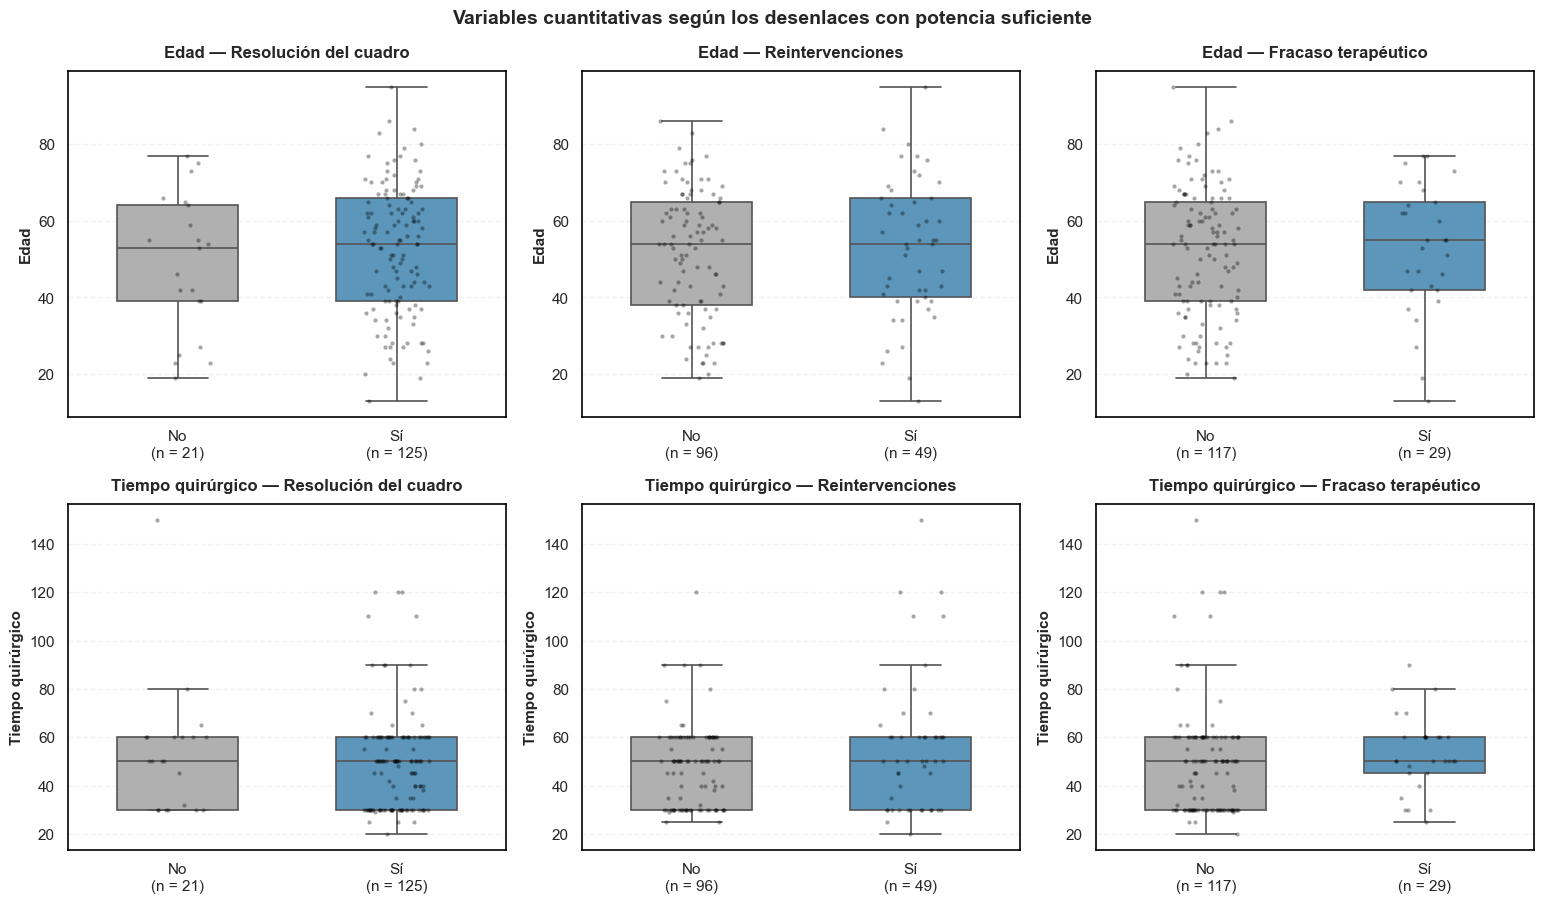

In [86]:
orden_des = ["NO", "SI"]
vars_cuant = list(VARIABLES_CUANTITATIVAS_OE6.items())
fig, axes = plt.subplots(len(vars_cuant), len(DESENLACES_VIABLES),
                         figsize=(5.2 * len(DESENLACES_VIABLES), 4.6 * len(vars_cuant)),
                         squeeze=False)

for i, (nombre_var, col_var) in enumerate(vars_cuant):
    for j, nombre_des in enumerate(DESENLACES_VIABLES):
        col_des = COLUMNAS_OE6[nombre_des]
        ax = axes[i, j]
        datos = df_spyglass[[col_var, col_des]].dropna()
        datos = datos[datos[col_des].isin(orden_des)]
        n_g = datos[col_des].value_counts().reindex(orden_des, fill_value=0)
        sns.boxplot(data=datos, x=col_des, y=col_var, order=orden_des,
                    hue=col_des, hue_order=orden_des,
                    palette=[COLOR_NEUTRO, COLOR_PRIMARIO], legend=False,
                    width=0.55, linewidth=1.2, showfliers=False, ax=ax)
        sns.stripplot(data=datos, x=col_des, y=col_var, order=orden_des,
                      color="black", alpha=0.35, size=3, jitter=0.15, ax=ax)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([f"No\n(n = {n_g['NO']})", f"Sí\n(n = {n_g['SI']})"])
        ax.set_title(f"{nombre_var} — {nombre_des}", fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel("")
        ax.set_ylabel(nombre_var, fontsize=11, fontweight="bold")
        estilo_ejes(ax)

fig.suptitle("Variables cuantitativas según los desenlaces con potencia suficiente",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


**Edad**

La distribución de la edad fue similar entre los procedimientos con y sin resolución del cuadro clínico. Las medianas fueron de 53 y 54 años, respectivamente, aunque el grupo con resolución presentó una mayor dispersión y edades comprendidas en un intervalo más amplio. Esta diferencia no fue estadísticamente significativa (p = 0.3574).

En las reintervenciones, ambos grupos registraron una mediana de 54 años y distribuciones considerablemente superpuestas. Aunque se observaron procedimientos correspondientes a edades más avanzadas y más jóvenes en ambos grupos, no se identificaron diferencias estadísticamente significativas (p = 0.7129).

Para el fracaso terapéutico, la mediana fue de 54 años en los procedimientos sin fracaso y de 55 años en aquellos con fracaso. Las distribuciones también mostraron un amplio solapamiento, sin diferencias estadísticamente significativas (p = 0.7111).

**Tiempo quirúrgico**

El tiempo quirúrgico presentó una mediana de 50 minutos tanto en los procedimientos con resolución del cuadro como en aquellos sin resolución. Las distribuciones fueron similares, aunque se observaron tiempos superiores a 100 minutos y un valor extremo cercano a 150 minutos. La comparación no mostró diferencias estadísticamente significativas (p = 0.5737).

En las reintervenciones, ambos grupos mantuvieron una mediana de 50 minutos. El grupo con reintervención presentó algunos procedimientos de duración prolongada, incluyendo valores superiores a 100 minutos, pero la diferencia entre las distribuciones no alcanzó significancia estadística (p = 0.1819).

Finalmente, en el fracaso terapéutico, ambos grupos registraron una mediana de 50 minutos. Sin embargo, los procedimientos sin fracaso mostraron una mayor dispersión y concentraron los tiempos quirúrgicos más elevados. Aunque esta comparación presentó el menor valor p entre las variables cuantitativas de este desenlace (p = 0.0940), no se identificó una diferencia estadísticamente significativa.

**Conclusión**

Los seis diagramas muestran un considerable solapamiento entre las distribuciones de edad y tiempo quirúrgico de los grupos comparados. Las medianas permanecieron prácticamente constantes en los tres desenlaces y ninguna de las seis comparaciones alcanzó significancia estadística. Por tanto, en esta cohorte no se identificaron diferencias estadísticamente significativas en la distribución de estas variables según la resolución del cuadro, las reintervenciones o el fracaso terapéutico.

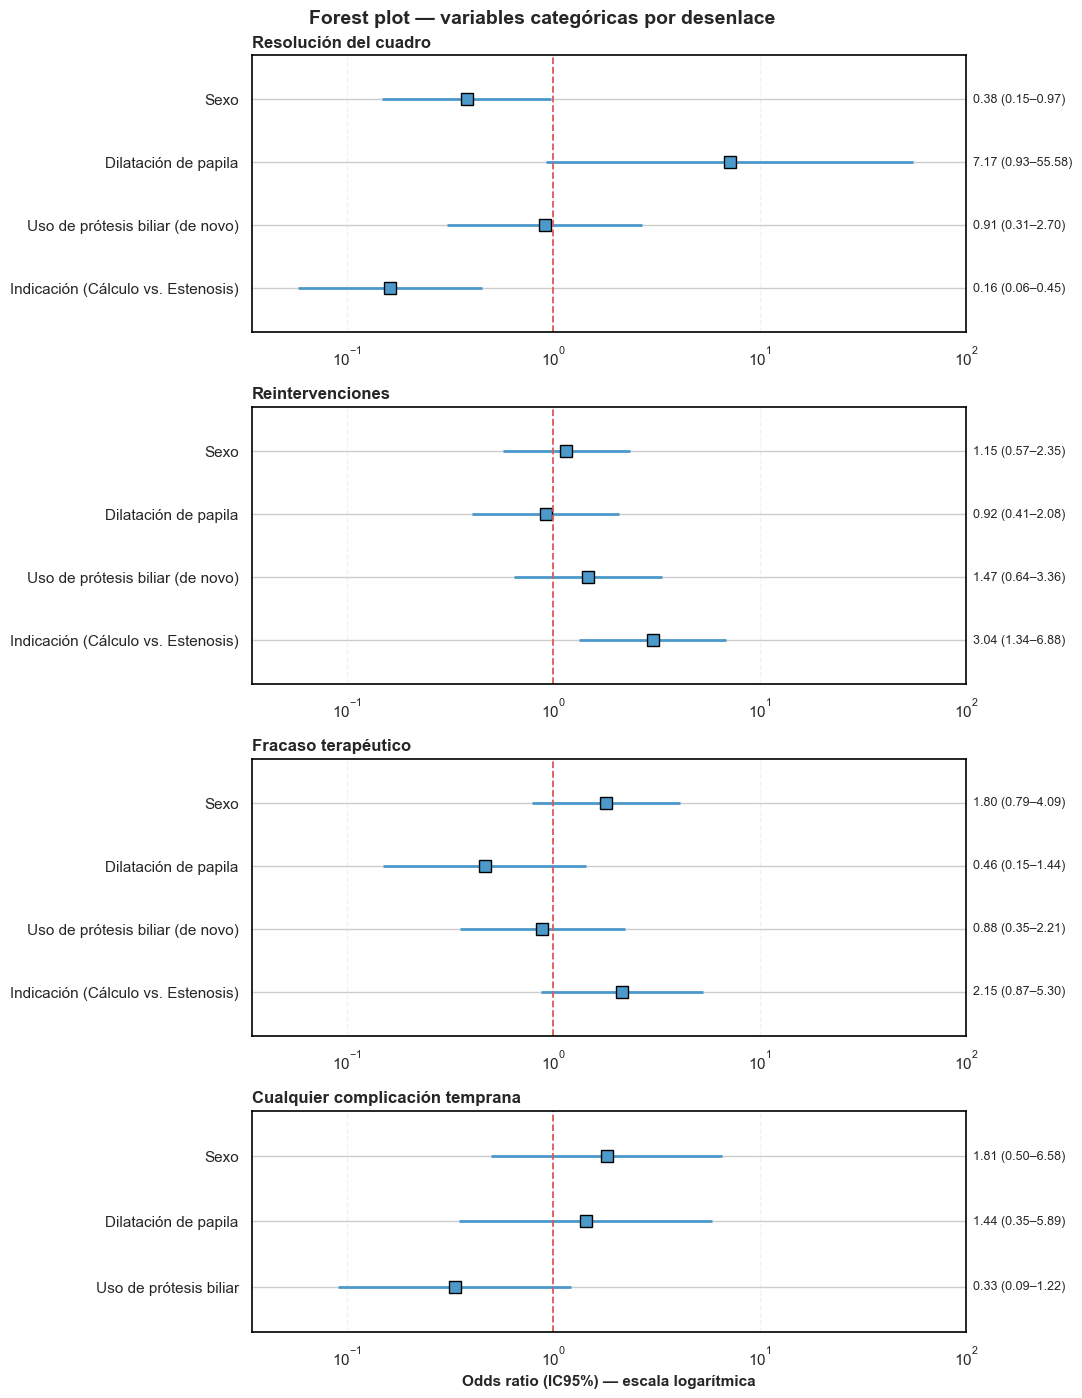

In [87]:
bloques_forest = []
for nombre_des in tabla_consolidada["Desenlace"].unique():
    sub = tabla_consolidada[(tabla_consolidada["Desenlace"] == nombre_des) & tabla_consolidada["OR"].notna()]
    bloques_forest.append((nombre_des, sub[["Variable", "OR", "IC95% inf", "IC95% sup"]]))
if "tabla_inferencial" in globals():
    sub = tabla_inferencial[tabla_inferencial["OR"].notna()]
    bloques_forest.append(("Cualquier complicación temprana", sub[["Variable", "OR", "IC95% inf", "IC95% sup"]]))

todos = pd.concat([b for _, b in bloques_forest])
x_min = max(min(todos["IC95% inf"].min(), todos["OR"].min()) * 0.6, 1e-3)
x_max = max(todos["IC95% sup"].max(), todos["OR"].max()) * 1.8

fig, axes = plt.subplots(len(bloques_forest), 1,
                         figsize=(11, sum(1.5 + 0.55 * len(b) for _, b in bloques_forest)),
                         gridspec_kw={"height_ratios": [max(len(b), 1) + 1 for _, b in bloques_forest]},
                         squeeze=False)
for ax, (nombre_des, bloque) in zip(axes[:, 0], bloques_forest):
    y = np.arange(len(bloque))[::-1]
    ax.hlines(y, bloque["IC95% inf"], bloque["IC95% sup"], color=COLOR_PRIMARIO, linewidth=2)
    ax.plot(bloque["OR"], y, "s", color=COLOR_PRIMARIO, markeredgecolor="black", markersize=8)
    ax.axvline(1, color=COLOR_SECUNDARIO, linestyle="--", linewidth=1.3)
    ax.set_xscale("log")
    ax.set_xlim(x_min, x_max)
    ax.set_yticks(y)
    ax.set_yticklabels(bloque["Variable"])
    ax.set_ylim(-0.7, len(bloque) - 0.3)
    for yi, (_, f) in zip(y, bloque.iterrows()):
        ax.text(1.01, yi, f"{f['OR']:.2f} ({f['IC95% inf']:.2f}–{f['IC95% sup']:.2f})",
                transform=ax.get_yaxis_transform(), va="center", fontsize=9)
    ax.set_title(nombre_des, fontsize=12, fontweight="bold", loc="left")
    estilo_ejes(ax, eje_grid="x")
axes[-1, 0].set_xlabel("Odds ratio (IC95%) — escala logarítmica", fontsize=11, fontweight="bold")
fig.suptitle("Forest plot — variables categóricas por desenlace", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


**1. Resolución del cuadro clínico**

El tipo de indicación presentó la asociación más marcada con la resolución del cuadro clínico (OR = 0.16; IC95%: 0.06–0.45). Su intervalo de confianza se encuentra completamente por debajo de 1, lo que indica una diferencia en las odds entre los procedimientos indicados por cálculo y aquellos indicados por estenosis. Esta asociación también se mantuvo estadísticamente significativa después de la corrección de Holm (p = 0.0038). En términos clínicos, la resolución se alcanzó en el 92.2% de los procedimientos indicados por cálculo, frente al 65.6% de los indicados por estenosis.

La dilatación de papila presentó el OR más elevado (7.17), pero también el intervalo de confianza más amplio (IC95%: 0.93–55.58), lo que refleja una estimación poco precisa. El sexo mostró un OR de 0.38 (IC95%: 0.15–0.97), mientras que el uso de prótesis biliar de novo presentó un OR cercano a la unidad (0.91; IC95%: 0.31–2.70). Ninguna de estas tres variables conservó significancia estadística después de la corrección de Holm.

**2. Reintervenciones**

El tipo de indicación mostró la asociación más destacada con las reintervenciones (OR = 3.04; IC95%: 1.34–6.88). Su intervalo de confianza se encuentra completamente por encima de 1, lo que indica una asociación en el análisis sin ajustar. Sin embargo, esta no conservó significancia después de la corrección de Holm (p = 0.0675).

El uso de prótesis biliar de novo presentó un OR de 1.47 (IC95%: 0.64–3.36), mientras que el sexo registró un OR de 1.15 (IC95%: 0.57–2.35). Por su parte, la dilatación de papila mostró un OR de 0.92 (IC95%: 0.41–2.08). Los intervalos de confianza de estas tres variables cruzan la línea de referencia OR = 1, sin mostrar asociaciones estadísticamente significativas.

**3. Fracaso terapéutico**

El tipo de indicación presentó el OR más elevado de este desenlace (2.15; IC95%: 0.87–5.30), seguido del sexo (OR = 1.80; IC95%: 0.79–4.09). Aunque ambas estimaciones se encuentran por encima de 1, sus intervalos de confianza incluyen la unidad.

La dilatación de papila presentó un OR de 0.46 (IC95%: 0.15–1.44), mientras que el uso de prótesis biliar de novo registró un OR de 0.88 (IC95%: 0.35–2.21). En ambos casos, los intervalos también incluyen 1. Ninguna de las cuatro variables presentó una asociación estadísticamente significativa con el fracaso terapéutico.

**4. Cualquier complicación temprana**

El uso de prótesis biliar presentó el OR más alejado de la unidad (0.33; IC95%: 0.09–1.22). En los datos evaluados, las complicaciones tempranas se registraron en el 4.8% de los procedimientos con uso de prótesis biliar (5/104), frente al 13.2% de aquellos sin prótesis (5/38). Aunque se observa una menor frecuencia de complicaciones en el primer grupo, el intervalo de confianza incluye 1 y la asociación no alcanzó significancia estadística (p = 0.1318).

El sexo presentó un OR de 1.81 (IC95%: 0.50–6.58), mientras que la dilatación de papila registró un OR de 1.44 (IC95%: 0.35–5.89). Ambos intervalos son amplios y atraviesan la línea de referencia, por lo que tampoco se identificaron asociaciones estadísticamente significativas. La amplitud de estos intervalos refleja la incertidumbre de las estimaciones, especialmente considerando que solamente se registraron 10 procedimientos con complicaciones tempranas entre los 145 evaluables.

**Conclusión**

Los forest plots muestran que el tipo de indicación clínica concentra las asociaciones más marcadas con los desenlaces de resolución del cuadro y reintervenciones. Sin embargo, únicamente la asociación con la resolución clínica conservó significancia después de la corrección de Holm. Para el fracaso terapéutico y las complicaciones tempranas, todos los intervalos de confianza incluyeron la unidad, sin evidencia estadística suficiente para establecer asociaciones con las variables categóricas evaluadas.

Las figuras permiten distinguir entre la magnitud de las asociaciones estimadas y su precisión. Los OR alejados de 1 no necesariamente representan resultados estadísticamente concluyentes, especialmente cuando sus intervalos de confianza son amplios o las asociaciones dejan de ser significativas después del ajuste por comparaciones múltiples.

## 8. Concordancia entre aspecto visual e histopatología (OE7)

### 8.1. Clasificación del aspecto visual

In [90]:
import pandas as pd
import numpy as np
import re
import unicodedata

COL_ASPECTO = encontrar_columna(
    df_spyglass,
    ["ASPECTO DE LA SUPERFICE", "ASPECTO DE LA SUPERFICIE"],
    obligatoria=True
)

def normalizar_aspecto(valor):
    if pd.isna(valor):
        return np.nan

    texto = str(valor).strip().upper()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caracter for caracter in texto
        if not unicodedata.combining(caracter)
    )
    texto = re.sub(r"\s+", " ", texto)

    if texto in ["", "NAN", "NONE", "NULL"]:
        return np.nan

    return texto

def clasificar_aspecto_visual(valor):
    if pd.isna(valor):
        return np.nan

    if valor in ["NO", "NO DESCRITO", "NO REPORTADO"]:
        return "Sin descripción específica"

    if valor in ["PAPILA DE ASPECTO NORMAL", "BLANDA", "FUSIFORME"]:
        return "Descripción sin sospecha explícita"

    patron_sospecha = (
        r"\bMALIGN\w*\b|"
        r"\bNEOPLAS\w*\b|"
        r"\bTUMOR\w*\b|"
        r"\bINFILTRANT\w*\b|"
        r"\bVEGETANT\w*\b"
    )

    if re.search(patron_sospecha, valor):
        return "Sospecha visual explícita"

    patron_inespecifico = (
        r"\bEDEMA\w*\b|"
        r"\bCONGEST\w*\b|"
        r"\bINFLAM\w*\b|"
        r"\bERITEMA\w*\b|"
        r"\bSANGRADO\b|"
        r"\bISQUEM\w*\b"
    )

    if re.search(patron_inespecifico, valor):
        return "Hallazgo inespecífico"

    return "Pendiente de revisión clínica"

estilos_tabla_aspecto = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("margin", "15px 0")
        ]
    }
]

df_spyglass["ASPECTO_VISUAL_NORMALIZADO"] = (
    df_spyglass[COL_ASPECTO].apply(normalizar_aspecto)
)

df_spyglass["ASPECTO_VISUAL_CATEGORIA"] = (
    df_spyglass["ASPECTO_VISUAL_NORMALIZADO"]
    .apply(clasificar_aspecto_visual)
)

tabla_aspecto = (
    df_spyglass["ASPECTO_VISUAL_CATEGORIA"]
    .fillna("Sin información")
    .value_counts()
    .rename_axis("Clasificación")
    .reset_index(name="Registros")
)

tabla_aspecto["Porcentaje (%)"] = (
    tabla_aspecto["Registros"] / len(df_spyglass) * 100
)

print("Distribución de la clasificación del aspecto visual:")

display(
    tabla_aspecto.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}"
    })
    .set_table_styles(estilos_tabla_aspecto)
    .set_properties(
        subset=["Clasificación"],
        **{"text-align": "left"}
    )
)

revision_aspecto = (
    df_spyglass.loc[
        df_spyglass["ASPECTO_VISUAL_CATEGORIA"].eq(
            "Pendiente de revisión clínica"
        ),
        [COL_ASPECTO, "ASPECTO_VISUAL_CATEGORIA"]
    ]
    .reset_index(drop=True)
    .rename(columns={
        COL_ASPECTO: "Descripción visual",
        "ASPECTO_VISUAL_CATEGORIA": "Clasificación"
    })
)

print("\nDescripciones pendientes de revisión clínica:")

display(
    revision_aspecto.style
    .hide(axis="index")
    .set_table_styles(estilos_tabla_aspecto)
    .set_properties(
        subset=["Descripción visual", "Clasificación"],
        **{
            "text-align": "left",
            "white-space": "normal",
            "max-width": "450px"
        }
    )
)

Distribución de la clasificación del aspecto visual:


Clasificación,Registros,Porcentaje (%)
Sin descripción específica,110,70.1
Sin información,19,12.1
Sospecha visual explícita,8,5.1
Pendiente de revisión clínica,8,5.1
Hallazgo inespecífico,8,5.1
Descripción sin sospecha explícita,4,2.5



Descripciones pendientes de revisión clínica:


Descripción visual,Clasificación
MUCOSA IRREGULAR INDURADA CON PROYECCIONES,Pendiente de revisión clínica
"MAMELONADA, ESTENOSANTE",Pendiente de revisión clínica
"VELLOSA, ENDOFITICA",Pendiente de revisión clínica
INDURADA,Pendiente de revisión clínica
"PETREA, PALIDA, CON FIBROSIS",Pendiente de revisión clínica
INDURADA,Pendiente de revisión clínica
INDURADA,Pendiente de revisión clínica
INDURADA,Pendiente de revisión clínica


De los 157 registros analizados, 110 (70.1%) presentaron el valor "NO" en la variable de aspecto de la superficie, por lo que se clasificaron como registros sin descripción específica. Adicionalmente, 19 registros (12.1%) no contaban con información. En conjunto, el 82.2% de los procedimientos no dispone de una descripción visual suficientemente detallada en esta variable para establecer una clasificación clínica.

Se identificaron 8 registros (5.1%) con expresiones explícitas de sospecha de malignidad, mientras que otros 8 (5.1%) describieron hallazgos inespecíficos, principalmente relacionados con cambios inflamatorios o alteraciones de la mucosa. Por su parte, 4 registros (2.5%) contenían descripciones sin sospecha explícita de malignidad.

Los 8 registros restantes (5.1%) quedaron pendientes de revisión clínica. Entre ellos se encontraron descripciones como "indurada", "mamelonada, estenosante", "vellosa, endofítica" y "mucosa irregular indurada con proyecciones". Estas características pueden tener distintas interpretaciones clínicas, por lo que no se asignaron automáticamente a una categoría de sospecha de malignidad.

La distribución evidencia una limitación importante para el análisis de concordancia visual e histopatológica: solamente 28 registros (17.8%) contienen una descripción visual específica, y parte de ellos requiere revisión clínica. Por tanto, la comparación con los resultados histopatológicos debe restringirse a los registros que cuenten con información visual interpretable y un resultado histopatológico correspondiente, sin asumir que la ausencia de descripción equivale a ausencia de malignidad.

### 8.2. Clasificación histopatológica e índice Kappa de Cohen

In [93]:
import pandas as pd
import numpy as np
import re
import unicodedata

COL_HISTOPATOLOGIA = encontrar_columna(
    df_spyglass,
    ["CORRELACION CLINICO PATOLOGICA", "RESULTADO HISTOPATOLOGICO"],
    obligatoria=True
)

def normalizar_histopatologia(valor):
    if pd.isna(valor):
        return np.nan

    texto = str(valor).strip().upper()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caracter for caracter in texto
        if not unicodedata.combining(caracter)
    )
    texto = re.sub(r"\s+", " ", texto)

    if texto in ["", "NAN", "NONE", "NULL"]:
        return np.nan

    return texto

def clasificar_histopatologia(valor):
    if pd.isna(valor):
        return "Sin información"

    if valor in ["NO", "NO APLICA", "SI", "SATISFACTORIA"]:
        return "Sin resultado evaluable"

    if re.search(r"\bADENOCARCINOMA\b|\bCARCINOMA\b", valor):
        return "Malignidad identificada"

    if re.search(r"\bADENOMA\b", valor):
        return "Lesión neoplásica no clasificada como maligna"

    patrones_negativos = [
        r"NEGATIVO PARA MALIGNIDAD",
        r"NO MALIGNIDAD",
        r"SIN EVIDENCIA DE LESION TUMORAL",
        r"SIN ATIPIAS",
        r"\bINFLAMACION\b",
        r"\bINFLAMATORIO\b",
        r"\bFIBROSIS\b",
        r"\bTEJIDO CONECTIVO\b",
        r"\bNORMAL\b"
    ]

    if any(re.search(p, valor) for p in patrones_negativos):
        return "Sin malignidad identificada"

    return "Pendiente de revisión clínica"

df_spyglass["HISTOPATOLOGIA_NORMALIZADA"] = (
    df_spyglass[COL_HISTOPATOLOGIA]
    .apply(normalizar_histopatologia)
)

df_spyglass["HISTOPATOLOGIA_CATEGORIA"] = (
    df_spyglass["HISTOPATOLOGIA_NORMALIZADA"]
    .apply(clasificar_histopatologia)
)

tabla_histopatologia = (
    df_spyglass["HISTOPATOLOGIA_CATEGORIA"]
    .value_counts()
    .rename_axis("Clasificación")
    .reset_index(name="Registros")
)

tabla_histopatologia["Porcentaje (%)"] = (
    tabla_histopatologia["Registros"] / len(df_spyglass) * 100
)

estilos_tabla_histo = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("margin", "15px 0")
        ]
    }
]

print("Distribución de la clasificación histopatológica:")

display(
    tabla_histopatologia.style
    .hide(axis="index")
    .format({
        "Registros": "{:.0f}",
        "Porcentaje (%)": "{:.1f}"
    })
    .set_table_styles(estilos_tabla_histo)
    .set_properties(
        subset=["Clasificación"],
        **{"text-align": "left"}
    )
)

revision_histopatologia = (
    df_spyglass.loc[
        df_spyglass["HISTOPATOLOGIA_CATEGORIA"].isin([
            "Pendiente de revisión clínica",
            "Lesión neoplásica no clasificada como maligna"
        ]),
        [COL_HISTOPATOLOGIA, "HISTOPATOLOGIA_CATEGORIA"]
    ]
    .reset_index(drop=True)
    .rename(columns={
        COL_HISTOPATOLOGIA: "Resultado histopatológico",
        "HISTOPATOLOGIA_CATEGORIA": "Clasificación"
    })
)

print("\nResultados que requieren revisión clínica:")

display(
    revision_histopatologia.style
    .hide(axis="index")
    .set_table_styles(estilos_tabla_histo)
    .set_properties(
        subset=["Resultado histopatológico", "Clasificación"],
        **{
            "text-align": "left",
            "white-space": "normal",
            "max-width": "450px"
        }
    )
)

Distribución de la clasificación histopatológica:


Clasificación,Registros,Porcentaje (%)
Sin resultado evaluable,113,72.0
Sin malignidad identificada,19,12.1
Sin información,11,7.0
Malignidad identificada,9,5.7
Pendiente de revisión clínica,4,2.5
Lesión neoplásica no clasificada como maligna,1,0.6



Resultados que requieren revisión clínica:


Resultado histopatológico,Clasificación
TEJIDO FIBRINOIDE,Pendiente de revisión clínica
MATERIAL NECROINFLAMATORIO,Pendiente de revisión clínica
TEJIDO FIBRINOIDE NO MALIGNO,Pendiente de revisión clínica
NEOPLASIA DE MORFOLOGIA PAPILAR,Pendiente de revisión clínica
ADENOMA MODERADAMENTE DIFERENCIADO INFILTRANTE,Lesión neoplásica no clasificada como maligna


De los 157 registros analizados, 113 (72.0%) fueron clasificados como sin resultado histopatológico evaluable y otros 11 (7.0%) no contaban con información. En conjunto, 124 registros (79.0%) no disponen de un resultado que permita establecer una clasificación histopatológica a partir de esta variable.

Entre los 33 registros restantes, se identificaron 19 (12.1% del total) con descripciones compatibles con ausencia de malignidad, principalmente relacionadas con procesos inflamatorios, fibrosis o resultados negativos para malignidad. Por otra parte, 9 registros (5.7%) contenían diagnósticos explícitos de malignidad, como adenocarcinoma.

Los cinco registros restantes requieren revisión clínica. Tres corresponden a descripciones de tejido fibrinoide o material necroinflamatorio, cuya interpretación debe considerar si el material obtenido permite descartar malignidad. Otro registro describe una neoplasia de morfología papilar, sin especificar su comportamiento histológico. Finalmente, se identificó un resultado de "adenoma moderadamente diferenciado infiltrante", cuya terminología requiere verificación, especialmente por la presencia del término "infiltrante".

Esta distribución muestra que la información histopatológica disponible es considerablemente menor que el número total de procedimientos. Por tanto, el análisis de concordancia con el aspecto visual debe realizarse únicamente sobre registros que cuenten con ambas valoraciones y con categorías diagnósticas suficientemente definidas.

In [95]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd
import numpy as np

mapa_visual = {
    "Sospecha visual explícita": 1,
    "Descripción sin sospecha explícita": 0
}

mapa_histopatologia = {
    "Malignidad identificada": 1,
    "Sin malignidad identificada": 0
}

datos_concordancia = df_spyglass[
    ["ASPECTO_VISUAL_CATEGORIA", "HISTOPATOLOGIA_CATEGORIA"]
].copy()

datos_concordancia["Visual"] = (
    datos_concordancia["ASPECTO_VISUAL_CATEGORIA"]
    .map(mapa_visual)
)

datos_concordancia["Histopatología"] = (
    datos_concordancia["HISTOPATOLOGIA_CATEGORIA"]
    .map(mapa_histopatologia)
)

datos_kappa = datos_concordancia[
    ["Visual", "Histopatología"]
].dropna()

n_kappa = len(datos_kappa)

print(f"Registros con ambas clasificaciones disponibles: {n_kappa}")

tabla_confusion = pd.crosstab(
    datos_kappa["Visual"],
    datos_kappa["Histopatología"]
).reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

tabla_confusion.index = [
    "Sin sospecha visual explícita",
    "Con sospecha visual explícita"
]

tabla_confusion.columns = [
    "Sin malignidad identificada",
    "Malignidad identificada"
]

display(
    tabla_confusion.reset_index()
    .rename(columns={"index": "Clasificación visual"})
    .style
    .hide(axis="index")
    .set_table_styles(estilos_tabla_histo)
    .set_properties(
        subset=["Clasificación visual"],
        **{"text-align": "left"}
    )
)

if n_kappa >= 10 and datos_kappa["Visual"].nunique() == 2 and datos_kappa["Histopatología"].nunique() == 2:
    kappa = cohen_kappa_score(
        datos_kappa["Visual"],
        datos_kappa["Histopatología"]
    )

    print(f"Kappa de Cohen: {kappa:.3f}")
else:
    print(
        "No se calcula Kappa: tamaño muestral reducido "
        "o categorías insuficientemente representadas."
    )


Registros con ambas clasificaciones disponibles: 5


Clasificación visual,Sin malignidad identificada,Malignidad identificada
Sin sospecha visual explícita,1,0
Con sospecha visual explícita,1,3


No se calcula Kappa: tamaño muestral reducido o categorías insuficientemente representadas.


La comparación entre el aspecto visual endoscópico y los resultados histopatológicos permitió identificar únicamente 5 registros con ambas clasificaciones disponibles, equivalentes al 3.2% de los 157 procedimientos analizados.

De estos registros, 3 presentaron sospecha visual explícita de malignidad y confirmación histopatológica de malignidad. Un registro mostró sospecha visual sin malignidad identificada en el resultado histopatológico, mientras que otro presentó una descripción sin sospecha explícita y ausencia de malignidad identificada.

Aunque se observó coincidencia entre las categorías exploratorias en 4 de los 5 registros, la disponibilidad limitada de información emparejada y la naturaleza preliminar de la clasificación visual impiden establecer una estimación clínicamente sólida de concordancia diagnóstica.

Por esta razón, no se reportó el índice Kappa de Cohen como medida inferencial de concordancia. El análisis se limitó a describir las coincidencias y discrepancias observadas entre ambas valoraciones, sin extrapolar estos resultados al conjunto de procedimientos.

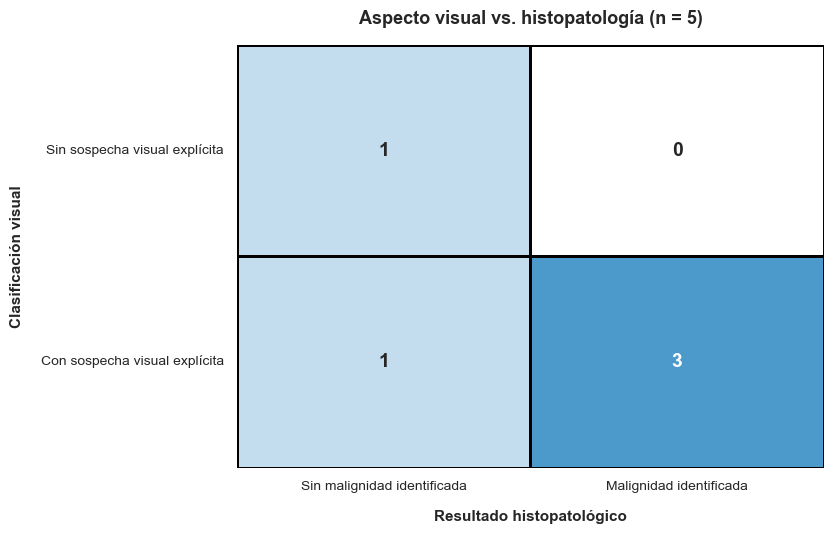

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

if "tabla_confusion" in globals() and n_kappa > 0:
    fig, ax = plt.subplots(figsize=(8.5, 5.5))

    sns.heatmap(
        tabla_confusion,
        annot=True,
        fmt="d",
        cmap=CMAP_SECUENCIAL,
        linewidths=1,
        linecolor="black",
        cbar=False,
        annot_kws={
            "fontsize": 14,
            "fontweight": "bold"
        },
        ax=ax
    )

    ax.set_title(
        f"Aspecto visual vs. histopatología (n = {n_kappa})",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Resultado histopatológico",
        fontsize=11,
        fontweight="bold",
        labelpad=12
    )

    ax.set_ylabel(
        "Clasificación visual",
        fontsize=11,
        fontweight="bold",
        labelpad=12
    )

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0,
        ha="center",
        fontsize=10
    )

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

else:
    print("No hay registros emparejados disponibles para graficar.")

### Concordancia exploratoria entre aspecto visual endoscópico e histopatología

La comparación entre el aspecto visual durante la colangioscopia y los resultados histopatológicos permitió identificar 5 procedimientos con ambas clasificaciones disponibles, equivalentes al 3.2% de los 157 registros analizados.

De estos, 3 procedimientos presentaron sospecha visual explícita de malignidad y un resultado histopatológico positivo para malignidad. Un procedimiento mostró sospecha visual sin malignidad identificada en la histopatología, mientras que otro presentó una descripción sin sospecha visual explícita y un resultado sin malignidad identificada. No se registraron casos con malignidad histopatológica identificada dentro del grupo sin sospecha visual explícita.

La matriz muestra coincidencia entre las categorías exploratorias en 4 de los 5 procedimientos (80.0%). Sin embargo, este porcentaje no debe interpretarse como una medida de precisión diagnóstica, ya que la clasificación visual se construyó a partir de descripciones textuales y la ausencia de sospecha explícita no equivale necesariamente a un resultado endoscópico negativo.

Debido al reducido número de registros emparejados y a las limitaciones de la clasificación visual, no se reportó el índice Kappa de Cohen. En consecuencia, el análisis se limitó a describir las coincidencias y discrepancias observadas, sin establecer conclusiones sobre la concordancia diagnóstica entre la evaluación endoscópica y la histopatología.

## 9. Estratificaciones transversales (Familia 3)

In [99]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, fisher_exact

COL_EDAD = encontrar_columna(
    df_spyglass,
    ["EDAD"],
    obligatoria=True
)

COL_TIEMPO = encontrar_columna(
    df_spyglass,
    ["TIEMPO QUIRURGICO", "TIEMPO", "DURACION"],
    obligatoria=True
)

COL_INDICACION = "TIPO_INDICACION_CALCULO_ESTENOSIS"
COL_COMPLICACION = "CUALQUIER_COMPLICACION"

df_ind_valida = df_spyglass.loc[
    df_spyglass[COL_INDICACION].isin(["Cálculo", "Estenosis"])
].copy()

resultados_familia_3 = []

for nombre_var, col_var in [
    ("Edad", COL_EDAD),
    ("Tiempo quirúrgico", COL_TIEMPO)
]:
    datos = df_ind_valida[
        [col_var, COL_INDICACION]
    ].copy()

    datos[col_var] = pd.to_numeric(
        datos[col_var],
        errors="coerce"
    )

    datos = datos.dropna()

    g_calculo = datos.loc[
        datos[COL_INDICACION] == "Cálculo",
        col_var
    ]

    g_estenosis = datos.loc[
        datos[COL_INDICACION] == "Estenosis",
        col_var
    ]

    if len(g_calculo) >= 3 and len(g_estenosis) >= 3:
        u, p = mannwhitneyu(
            g_calculo,
            g_estenosis,
            alternative="two-sided"
        )

        resultados_familia_3.append({
            "Estratificación": f"{nombre_var} según indicación",
            "Prueba": "Mann-Whitney U",
            "n Cálculo": len(g_calculo),
            "n Estenosis": len(g_estenosis),
            "Mediana Cálculo": g_calculo.median(),
            "Mediana Estenosis": g_estenosis.median(),
            "Estadistico": u,
            "p": p,
            "OR": np.nan
        })

datos_comp_ind = df_ind_valida[
    [COL_INDICACION, COL_COMPLICACION]
].dropna()

datos_comp_ind = datos_comp_ind.loc[
    datos_comp_ind[COL_COMPLICACION].isin(["SI", "NO"])
]

tabla_comp_ind = pd.crosstab(
    datos_comp_ind[COL_INDICACION],
    datos_comp_ind[COL_COMPLICACION]
).reindex(
    index=["Cálculo", "Estenosis"],
    columns=["NO", "SI"],
    fill_value=0
)

if (
    tabla_comp_ind.sum(axis=1).gt(0).all()
    and tabla_comp_ind.values.sum() > 0
):
    odds_ratio, p = fisher_exact(tabla_comp_ind.values)

    resultados_familia_3.append({
        "Estratificación": "Complicaciones según indicación",
        "Prueba": "Fisher exacta",
        "n Cálculo": int(tabla_comp_ind.loc["Cálculo"].sum()),
        "n Estenosis": int(tabla_comp_ind.loc["Estenosis"].sum()),
        "Mediana Cálculo": np.nan,
        "Mediana Estenosis": np.nan,
        "Estadistico": np.nan,
        "p": p,
        "OR": odds_ratio
    })

tabla_familia_3 = pd.DataFrame(resultados_familia_3)

estilos_familia_3 = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("margin", "15px 0")
        ]
    }
]

print("FAMILIA 3 — Estratificaciones transversales")

display(
    tabla_familia_3.style
    .hide(axis="index")
    .format({
        "n Cálculo": "{:.0f}",
        "n Estenosis": "{:.0f}",
        "Mediana Cálculo": "{:.1f}",
        "Mediana Estenosis": "{:.1f}",
        "Estadistico": "{:.4g}",
        "p": "{:.4f}",
        "OR": "{:.2f}"
    }, na_rep="—")
    .set_table_styles(estilos_familia_3)
    .set_properties(
        subset=["Estratificación", "Prueba"],
        **{"text-align": "left"}
    )
)

print("\nDistribución de complicaciones según indicación:")

display(
    tabla_comp_ind.reset_index()
    .style
    .hide(axis="index")
    .set_table_styles(estilos_familia_3)
    .set_properties(
        subset=[COL_INDICACION],
        **{"text-align": "left"}
    )
)

  (coincidencia parcial: 'TIEMPO QUIRURGICO' -> columna real 'TIEMPO QUIRÚRGICO EN MINUTOS')
FAMILIA 3 — Estratificaciones transversales


Estratificación,Prueba,n Cálculo,n Estenosis,Mediana Cálculo,Mediana Estenosis,Estadistico,p,OR
Edad según indicación,Mann-Whitney U,103,32,51.0,58.5,1280,0.0572,—
Tiempo quirúrgico según indicación,Mann-Whitney U,103,32,50.0,50.0,1768,0.5292,—
Complicaciones según indicación,Fisher exacta,102,32,—,—,—,0.2165,2.77



Distribución de complicaciones según indicación:


TIPO_INDICACION_CALCULO_ESTENOSIS,NO,SI
Cálculo,97,5
Estenosis,28,4


La comparación de las características clínicas según el tipo de indicación mostró diferencias descriptivas en la edad. Los procedimientos indicados por cálculo presentaron una mediana de 51 años (n = 103), mientras que aquellos indicados por estenosis registraron una mediana de 58.5 años (n = 32). Aunque la diferencia fue de 7.5 años, la prueba de Mann-Whitney no alcanzó significancia estadística (p = 0.0572).

El tiempo quirúrgico presentó una mediana de 50 minutos en ambos grupos, sin diferencias estadísticamente significativas entre las indicaciones por cálculo y estenosis (p = 0.5292).

Respecto a las complicaciones tempranas, se registraron 5 eventos entre los 102 procedimientos evaluables indicados por cálculo (4.9%) y 4 entre los 32 indicados por estenosis (12.5%). Aunque la frecuencia observada fue mayor en los procedimientos por estenosis, la prueba exacta de Fisher no mostró una asociación estadísticamente significativa (p = 0.2165).

En conjunto, las estratificaciones muestran que los procedimientos indicados por estenosis correspondieron a registros con mayor mediana de edad y mayor proporción observada de complicaciones tempranas. Sin embargo, ninguna de las tres comparaciones alcanzó significancia estadística en el análisis sin ajustar.

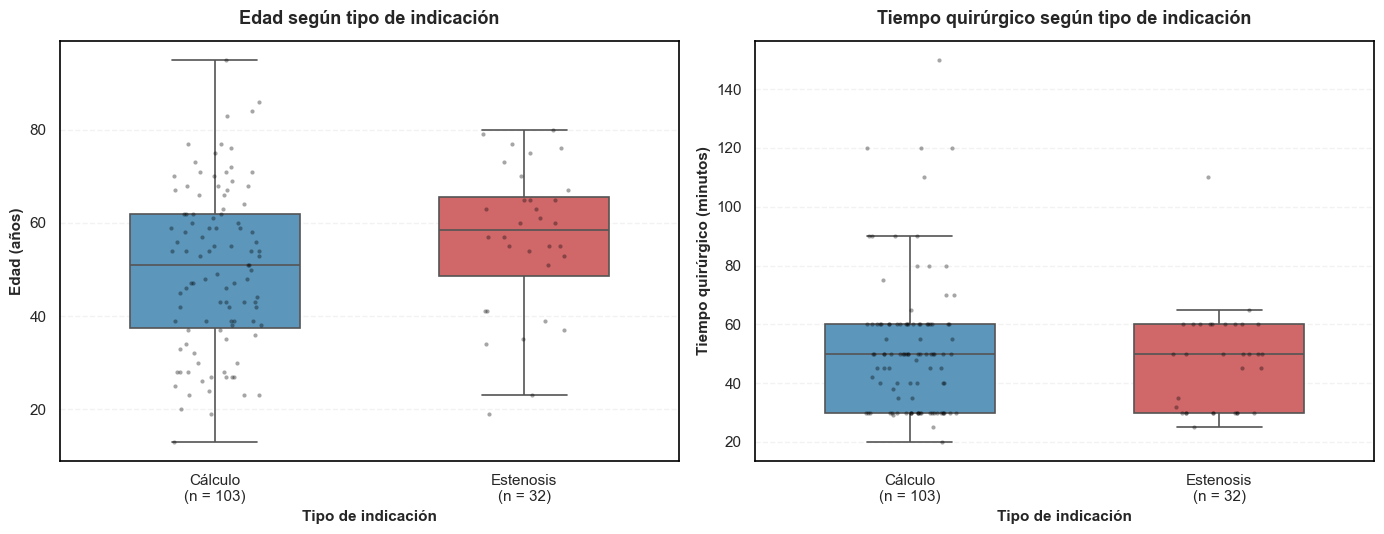

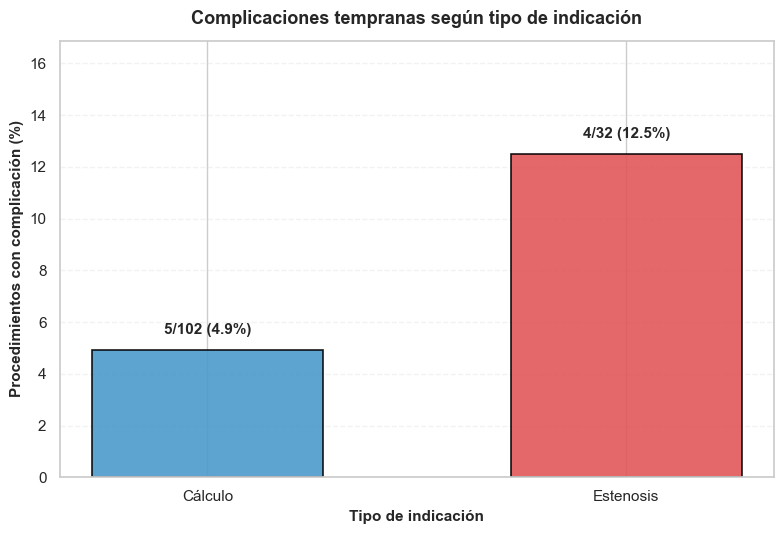

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

orden_ind = ["Cálculo", "Estenosis"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

variables = [
    ("Edad (años)", COL_EDAD),
    ("Tiempo quirúrgico (minutos)", COL_TIEMPO)
]

for ax, (nombre_var, col_var) in zip(axes, variables):
    datos = df_ind_valida[
        [col_var, "TIPO_INDICACION_CALCULO_ESTENOSIS"]
    ].copy()

    datos[col_var] = pd.to_numeric(datos[col_var], errors="coerce")
    datos = datos.dropna()

    n_g = (
        datos["TIPO_INDICACION_CALCULO_ESTENOSIS"]
        .value_counts()
        .reindex(orden_ind, fill_value=0)
    )

    sns.boxplot(
        data=datos,
        x="TIPO_INDICACION_CALCULO_ESTENOSIS",
        y=col_var,
        order=orden_ind,
        hue="TIPO_INDICACION_CALCULO_ESTENOSIS",
        hue_order=orden_ind,
        palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO],
        legend=False,
        width=0.55,
        linewidth=1.2,
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=datos,
        x="TIPO_INDICACION_CALCULO_ESTENOSIS",
        y=col_var,
        order=orden_ind,
        color="black",
        alpha=0.35,
        size=3,
        jitter=0.15,
        ax=ax
    )

    ax.set_xticks(range(len(orden_ind)))
    ax.set_xticklabels(
        [f"{g}\n(n = {k})" for g, k in zip(orden_ind, n_g)]
    )

    ax.set_title(
        f"{nombre_var.split(' (')[0]} según tipo de indicación",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Tipo de indicación",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        nombre_var,
        fontsize=11,
        fontweight="bold"
    )

    estilo_ejes(ax)

plt.tight_layout()
plt.show()

tabla_grafica = tabla_comp_ind.reindex(
    index=orden_ind,
    columns=["NO", "SI"],
    fill_value=0
)

n_fila = tabla_grafica.sum(axis=1)
porcentajes = tabla_grafica["SI"] / n_fila * 100

fig, ax = plt.subplots(figsize=(8, 5.5))

barras = ax.bar(
    orden_ind,
    porcentajes.values,
    color=[COLOR_PRIMARIO, COLOR_SECUNDARIO],
    edgecolor="black",
    linewidth=1.2,
    width=0.55,
    alpha=0.9
)

for barra, eventos, total, porcentaje in zip(
    barras,
    tabla_grafica["SI"],
    n_fila,
    porcentajes
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        f"{eventos}/{total} ({porcentaje:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylim(0, max(porcentajes.max() * 1.35, 10))

ax.set_title(
    "Complicaciones tempranas según tipo de indicación",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Tipo de indicación",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Procedimientos con complicación (%)",
    fontsize=11,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Edad según tipo de indicación**

Los procedimientos indicados por cálculo presentaron una mediana de edad de 51 años (n = 103), mientras que aquellos indicados por estenosis registraron una mediana de 58.5 años (n = 32). Esta diferencia de 7.5 años también se aprecia en los diagramas de caja, donde el grupo de estenosis presenta una distribución desplazada hacia edades mayores. Sin embargo, la comparación mediante Mann-Whitney no alcanzó significancia estadística (U = 1280; p = 0.0572).

**Tiempo quirúrgico según tipo de indicación**

El tiempo quirúrgico presentó una mediana de 50 minutos en ambos grupos. Los procedimientos indicados por cálculo mostraron una mayor dispersión de los tiempos prolongados, incluyendo registros superiores a 100 minutos y un valor extremo cercano a 150 minutos. En contraste, los procedimientos indicados por estenosis se concentraron principalmente entre 30 y 60 minutos. A pesar de estas diferencias descriptivas, la prueba de Mann-Whitney no identificó diferencias estadísticamente significativas (U = 1768; p = 0.5292).

**Complicaciones tempranas según tipo de indicación**

Las complicaciones tempranas se registraron en 5 de los 102 procedimientos evaluables indicados por cálculo (4.9%) y en 4 de los 32 indicados por estenosis (12.5%). La proporción observada fue 7.6 puntos porcentuales mayor en el grupo de estenosis.

La prueba exacta de Fisher no identificó una asociación estadísticamente significativa entre el tipo de indicación y la presencia de complicaciones tempranas (p = 0.2165). Aunque la frecuencia fue mayor en los procedimientos indicados por estenosis, los resultados no permiten establecer una diferencia estadísticamente concluyente entre ambos grupos.

**Consideraciones metodológicas**

La estratificación según el carácter diagnóstico o terapéutico del procedimiento se excluyó debido a que el dataset no dispone de una variable clínica explícita que permita establecer esta clasificación. Asimismo, no se realizó una estratificación por naturaleza benigna o maligna de la indicación, dado que no se dispone de una clasificación diagnóstica confirmada y consistente para todos los registros.

**Síntesis**

Los procedimientos indicados por estenosis presentaron una mayor mediana de edad y una proporción observada de complicaciones tempranas superior a los indicados por cálculo. Por su parte, el tiempo quirúrgico mostró medianas idénticas entre ambos grupos, aunque con diferencias en la dispersión de los valores. Ninguna de las tres comparaciones alcanzó significancia estadística antes de aplicar la corrección por comparaciones múltiples.

## 10. Corrección por multiplicidad — las 4 familias de Holm

In [104]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests

def aplicar_holm_seguro(tabla, columna_p="p"):
    resultado = tabla.copy()

    if columna_p not in resultado.columns:
        raise KeyError(
            f"No se encontró '{columna_p}'. Columnas disponibles: {list(resultado.columns)}"
        )

    valores_p = pd.to_numeric(resultado[columna_p], errors="coerce")
    validos = valores_p.notna() & valores_p.between(0, 1)

    resultado["p (Holm)"] = np.nan

    if validos.any():
        resultado.loc[validos, "p (Holm)"] = multipletests(
            valores_p.loc[validos],
            method="holm"
        )[1]

    resultado["Significativo (Holm)"] = np.where(
        resultado["p (Holm)"].notna(),
        np.where(resultado["p (Holm)"] < 0.05, "Sí", "No"),
        "No evaluable"
    )

    return resultado

estilos_holm = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("margin", "15px 0")
        ]
    }
]

def mostrar_tabla_holm(tabla):
    formatos = {}

    for columna in tabla.columns:
        if columna in ["p", "Valor p", "p (Holm)"]:
            formatos[columna] = "{:.4f}"
        elif columna in ["OR", "IC95% inf", "IC95% sup"]:
            formatos[columna] = "{:.2f}"
        elif columna in ["r (efecto)", "Cramer V"]:
            formatos[columna] = "{:.3f}"
        elif columna in ["Estadistico", "Estadístico"]:
            formatos[columna] = "{:.4f}"
        elif columna.startswith("Mediana"):
            formatos[columna] = "{:.1f}"
        elif columna.startswith("n ") or columna in [
            "Registros",
            "Registros evaluables",
            "Pruebas ajustadas",
            "Asociaciones significativas"
        ]:
            formatos[columna] = "{:.0f}"

    columnas_texto = [
        columna for columna in tabla.columns
        if columna in [
            "Familia",
            "Análisis",
            "Desenlace",
            "Variable",
            "Prueba",
            "Estratificación",
            "Hallazgo",
            "Clasificación",
            "Estado",
            "Significativo (Holm)"
        ]
    ]

    estilo = (
        tabla.style
        .hide(axis="index")
        .format(formatos, na_rep="—")
        .set_table_styles(estilos_holm)
    )

    if columnas_texto:
        estilo = estilo.set_properties(
            subset=columnas_texto,
            **{"text-align": "left"}
        )

    display(estilo)

resumen_familias = []

print("FAMILIA 1 — Hallazgos endoscópicos y rendimiento de biopsia")

familia_1 = aplicar_holm_seguro(
    tabla_hallazgo_biopsia,
    columna_p="Valor p"
)

mostrar_tabla_holm(familia_1)

resumen_familias.append({
    "Familia": "1",
    "Análisis": "Hallazgos endoscópicos × rendimiento de biopsia",
    "Pruebas ajustadas": int(familia_1["p (Holm)"].notna().sum()),
    "Asociaciones significativas": int(
        (familia_1["Significativo (Holm)"] == "Sí").sum()
    ),
    "Estado": "Holm aplicado"
})

print("\nFAMILIA 2 — Variables basales y desenlaces clínicos")

familia_2 = {}

for nombre_desenlace, tabla in resultados_por_desenlace.items():
    tabla_ajustada = aplicar_holm_seguro(
        tabla,
        columna_p="p"
    )

    familia_2[nombre_desenlace] = tabla_ajustada

    print(f"\nDESENLACE: {nombre_desenlace.upper()}")

    mostrar_tabla_holm(tabla_ajustada)

    resumen_familias.append({
        "Familia": "2",
        "Análisis": nombre_desenlace,
        "Pruebas ajustadas": int(
            tabla_ajustada["p (Holm)"].notna().sum()
        ),
        "Asociaciones significativas": int(
            (tabla_ajustada["Significativo (Holm)"] == "Sí").sum()
        ),
        "Estado": "Holm por desenlace"
    })

print("\nFAMILIA 3 — Estratificaciones transversales")

familia_3_holm = aplicar_holm_seguro(
    tabla_familia_3,
    columna_p="p"
)

mostrar_tabla_holm(familia_3_holm)

resumen_familias.append({
    "Familia": "3",
    "Análisis": "Estratificaciones transversales",
    "Pruebas ajustadas": int(
        familia_3_holm["p (Holm)"].notna().sum()
    ),
    "Asociaciones significativas": int(
        (familia_3_holm["Significativo (Holm)"] == "Sí").sum()
    ),
    "Estado": "Holm aplicado"
})

tabla_resumen_holm = pd.DataFrame(resumen_familias)

print("\nRESUMEN GENERAL — CORRECCIÓN POR MULTIPLICIDAD")

mostrar_tabla_holm(tabla_resumen_holm)

tablas_significativas = []

for nombre, tabla in [
    ("Familia 1", familia_1),
    *[
        (f"Familia 2 — {nombre}", tabla)
        for nombre, tabla in familia_2.items()
    ],
    ("Familia 3", familia_3_holm)
]:
    significativas = tabla.loc[
        tabla["Significativo (Holm)"] == "Sí"
    ].copy()

    if not significativas.empty:
        significativas.insert(0, "Familia / Desenlace", nombre)

        if "Valor p" in significativas.columns:
            significativas = significativas.rename(
                columns={"Valor p": "p"}
            )

        columnas = [
            columna for columna in [
                "Familia / Desenlace",
                "Hallazgo",
                "Variable",
                "Estratificación",
                "p",
                "p (Holm)"
            ]
            if columna in significativas.columns
        ]

        tablas_significativas.append(
            significativas[columnas]
        )

print("\nASOCIACIONES QUE CONSERVAN SIGNIFICANCIA DESPUÉS DE HOLM")

if tablas_significativas:
    tabla_significativas_holm = pd.concat(
        tablas_significativas,
        ignore_index=True
    )

    mostrar_tabla_holm(tabla_significativas_holm)
else:
    tabla_significativas_holm = pd.DataFrame()
    print("No se identificaron asociaciones significativas después de Holm.")

print(
    "\nOE7: comparación visual e histopatológica descriptiva (n = 5). "
    "No se incluye en las familias de corrección por multiplicidad."
)

FAMILIA 1 — Hallazgos endoscópicos y rendimiento de biopsia


Hallazgo,Registros evaluables,Prueba,Estadístico,Valor p,p (Holm),Significativo (Holm)
Papilaridad,32,Monte Carlo (márgenes fijos),1.3675,0.6297,1.0000,No
Nodularidad,32,Monte Carlo (márgenes fijos),0.2382,1.0000,1.0000,No
Irregularidad del contorno,31,Monte Carlo (márgenes fijos),5.3733,0.0853,0.4263,No
Friabilidad,32,Monte Carlo (márgenes fijos),15.5897,0.0631,0.3788,No
Vasos de neoformación,32,Monte Carlo (márgenes fijos),8.0879,0.0100,0.0699,No
Infiltración,32,Monte Carlo (márgenes fijos),3.2321,0.2602,1.0000,No
Sangrado espontáneo,32,Monte Carlo (márgenes fijos),0.8545,0.4778,1.0000,No



FAMILIA 2 — Variables basales y desenlaces clínicos

DESENLACE: RESOLUCIÓN DEL CUADRO


Desenlace,Variable,Prueba,n NO,n SI,Mediana NO,Mediana SI,Estadistico,p,OR,IC95% inf,IC95% sup,r (efecto),p (Holm),Significativo (Holm)
Resolución del cuadro,Edad,Mann-Whitney U,21,125,53.0,54.0,1147.0000,0.3574,—,—,—,0.126,1.0000,No
Resolución del cuadro,Tiempo quirúrgico,Mann-Whitney U,21,125,50.0,50.0,1412.0000,0.5737,—,—,—,-0.076,1.0000,No
Resolución del cuadro,Sexo,Fisher exacta,21,125,—,—,—,0.0508,0.38,0.15,0.97,—,0.2538,No
Resolución del cuadro,Dilatación de papila,Fisher exacta,21,125,—,—,—,0.0277,7.17,0.93,55.58,—,0.1665,No
Resolución del cuadro,Uso de prótesis biliar (de novo),Fisher exacta,20,123,—,—,—,1.0000,0.91,0.31,2.70,—,1.0000,No
Resolución del cuadro,Número de procedimientos,"Chi-cuadrado (Monte Carlo, márgenes fijos)",21,125,—,—,3.0867,0.2290,—,—,—,—,0.9158,No
Resolución del cuadro,Indicación (Cálculo vs. Estenosis),Fisher exacta,19,116,—,—,—,0.0005,0.16,0.06,0.45,—,0.0038,Sí



DESENLACE: REINTERVENCIONES


...


RESUMEN GENERAL — CORRECCIÓN POR MULTIPLICIDAD


Familia,Análisis,Pruebas ajustadas,Asociaciones significativas,Estado
1,Hallazgos endoscópicos × rendimiento de biopsia,7,0,Holm aplicado
2,Resolución del cuadro,7,1,Holm por desenlace
2,Reintervenciones,7,0,Holm por desenlace
2,Fracaso terapéutico,7,0,Holm por desenlace
3,Estratificaciones transversales,3,0,Holm aplicado



ASOCIACIONES QUE CONSERVAN SIGNIFICANCIA DESPUÉS DE HOLM


Familia / Desenlace,Variable,p,p (Holm)
Familia 2 — Resolución del cuadro,Indicación (Cálculo vs. Estenosis),0.0005,0.0038



OE7: comparación visual e histopatológica descriptiva (n = 5). No se incluye en las familias de corrección por multiplicidad.


La corrección por el método de Holm se aplicó a 31 contrastes estadísticos, organizados en tres familias de análisis. El ajuste se realizó dentro de cada familia y, para los desenlaces clínicos de la Familia 2, de manera independiente para resolución del cuadro, reintervenciones y fracaso terapéutico.

**Familia 1. Hallazgos endoscópicos y rendimiento de biopsia**

Se evaluaron siete hallazgos endoscópicos frente al rendimiento de la biopsia, con entre 31 y 32 registros evaluables por comparación. La presencia de vasos de neoformación presentó el menor valor p sin ajustar (p = 0.0100), seguida de friabilidad (p = 0.0631) e irregularidad del contorno (p = 0.0853).

Después de aplicar Holm, ninguna de las siete asociaciones conservó significancia estadística. En particular, el valor p ajustado para vasos de neoformación aumentó a 0.0699, mientras que friabilidad e irregularidad del contorno registraron valores ajustados de 0.3788 y 0.4263, respectivamente. Por tanto, no se identificó una asociación estadísticamente significativa entre los hallazgos endoscópicos evaluados y el rendimiento de la biopsia después del ajuste.

**Familia 2. Variables basales y desenlaces clínicos**

En el análisis de resolución del cuadro, la indicación clínica fue la única variable que conservó significancia estadística después de Holm (p = 0.0005; p ajustado = 0.0038). Los procedimientos indicados por cálculo presentaron una resolución del 92.2% (95/103), frente al 65.6% (21/32) de aquellos indicados por estenosis, una diferencia de 26.6 puntos porcentuales.

Otras asociaciones inicialmente destacadas, como la dilatación de papila (p = 0.0277) y el sexo (p = 0.0508), no conservaron significancia después del ajuste, con valores p corregidos de 0.1665 y 0.2538, respectivamente.

En el análisis de reintervenciones, la indicación clínica presentó un OR de 3.04 (IC95%: 1.34–6.88; p = 0.0096), mientras que el número de procedimientos registró un valor p de 0.0288. Sin embargo, ambas asociaciones dejaron de ser significativas después de Holm, con valores ajustados de 0.0675 y 0.1727, respectivamente.

Para el fracaso terapéutico, ninguna de las siete variables evaluadas presentó asociaciones estadísticamente significativas después de la corrección. El tiempo quirúrgico mostró un valor p de 0.0940, que aumentó a 0.6581 después del ajuste.

**Familia 3. Estratificaciones transversales**

Las comparaciones según el tipo de indicación tampoco identificaron asociaciones significativas después de Holm. Los procedimientos indicados por estenosis presentaron una mediana de edad superior a los indicados por cálculo (58.5 frente a 51 años), pero la diferencia no alcanzó significancia estadística (p ajustado = 0.1715).

El tiempo quirúrgico presentó una mediana de 50 minutos en ambos grupos (p ajustado = 0.5292). Por su parte, las complicaciones tempranas se registraron en el 12.5% de los procedimientos indicados por estenosis y en el 4.9% de los indicados por cálculo, sin una asociación estadísticamente significativa después de la corrección (p ajustado = 0.4330).

**Síntesis de los resultados**

De los 31 contrastes realizados, únicamente la asociación entre el tipo de indicación clínica y la resolución del cuadro conservó significancia estadística después de aplicar Holm. Los procedimientos indicados por cálculo presentaron una mayor proporción de resolución que aquellos indicados por estenosis.

Los demás contrastes no conservaron significancia estadística después del ajuste, incluidos los hallazgos endoscópicos frente al rendimiento de biopsia, las asociaciones con reintervenciones y fracaso terapéutico, y las estratificaciones transversales.

En consecuencia, la indicación clínica constituye la principal variable asociada con la resolución del cuadro dentro de los análisis bivariados realizados. Esta asociación no permite establecer causalidad ni descartar la influencia de otras características clínicas de los procedimientos.

## 11. Control de calidad (QC) final

In [107]:
import pandas as pd
import numpy as np

def checklist_qc_final(df, resultados_por_desenlace, familia_1, familia_2, familia_3_holm):

    estilos_qc = [
        {
            "selector": "th",
            "props": [
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("margin", "15px 0")
            ]
        }
    ]

    def mostrar_qc(tabla, columnas_texto=None, formatos=None):
        estilo = (
            tabla.style
            .hide(axis="index")
            .format(formatos or {}, na_rep="—")
            .set_table_styles(estilos_qc)
        )

        if columnas_texto:
            estilo = estilo.set_properties(
                subset=columnas_texto,
                **{
                    "text-align": "left",
                    "white-space": "normal"
                }
            )

        display(estilo)

    verificaciones = []

    n_filas, n_columnas = df.shape

    verificaciones.append({
        "Verificación": "Número de registros",
        "Resultado": f"{n_filas} registros",
        "Estado": "OK" if n_filas == 157 else "Revisar"
    })

    verificaciones.append({
        "Verificación": "Estructura del dataset",
        "Resultado": f"{n_columnas} columnas actuales; incluye variables derivadas",
        "Estado": "Informativo"
    })

    columnas_clave = [
        "TIPO_INDICACION_CALCULO_ESTENOSIS",
        "USO DE PROTESIS BILIAR",
        "DILATACION DE PAPILA",
        "TIEMPO QUIRÚRGICO EN MINUTOS",
        "NUMERO DE PROCEDIMIENTOS"
    ]

    columnas_disponibles = [
        columna for columna in columnas_clave
        if columna in df.columns
    ]

    tabla_completitud = pd.DataFrame({
        "Variable": columnas_disponibles,
        "Registros evaluables": [
            int(df[columna].notna().sum())
            for columna in columnas_disponibles
        ],
        "Valores faltantes": [
            int(df[columna].isna().sum())
            for columna in columnas_disponibles
        ],
        "Faltantes (%)": [
            df[columna].isna().mean() * 100
            for columna in columnas_disponibles
        ]
    })

    verificaciones.append({
        "Verificación": "Disponibilidad de variables clave",
        "Resultado": f"{len(columnas_disponibles)}/{len(columnas_clave)} columnas disponibles",
        "Estado": "OK" if len(columnas_disponibles) == len(columnas_clave) else "Revisar"
    })

    tablas_desenlaces = []

    for nombre, tabla in resultados_por_desenlace.items():
        if {"n NO", "n SI"}.issubset(tabla.columns):
            n_no = pd.to_numeric(tabla["n NO"], errors="coerce")
            n_si = pd.to_numeric(tabla["n SI"], errors="coerce")

            tabla_auxiliar = pd.DataFrame({
                "Desenlace": nombre,
                "Variable": tabla["Variable"].values,
                "n NO": n_no.values,
                "n SI": n_si.values,
                "Total evaluable": (n_no + n_si).values
            })

            tablas_desenlaces.append(tabla_auxiliar)

    if tablas_desenlaces:
        tabla_qc_desenlaces = pd.concat(
            tablas_desenlaces,
            ignore_index=True
        )

        grupos_pequenos = (
            (tabla_qc_desenlaces["n NO"] < 5) |
            (tabla_qc_desenlaces["n SI"] < 5)
        )

        verificaciones.append({
            "Verificación": "Tamaños de grupo en OE6",
            "Resultado": f"{int(grupos_pequenos.sum())} comparaciones con grupos menores de 5",
            "Estado": "Revisar" if grupos_pequenos.any() else "OK"
        })
    else:
        tabla_qc_desenlaces = pd.DataFrame()

        verificaciones.append({
            "Verificación": "Tamaños de grupo en OE6",
            "Resultado": "Sin tablas verificables",
            "Estado": "Revisar"
        })

    tablas_holm = {
        "Familia 1": familia_1,
        **{
            f"Familia 2 — {nombre}": tabla
            for nombre, tabla in familia_2.items()
        },
        "Familia 3": familia_3_holm
    }

    resumen_holm = []
    total_pruebas = 0
    total_significativas = 0
    valores_invalidos = 0

    for nombre, tabla in tablas_holm.items():
        columna_p = "Valor p" if "Valor p" in tabla.columns else "p"

        p_original = pd.to_numeric(
            tabla[columna_p],
            errors="coerce"
        )

        p_ajustado = pd.to_numeric(
            tabla["p (Holm)"],
            errors="coerce"
        )

        validos = (
            p_original.notna() &
            p_ajustado.notna() &
            p_original.between(0, 1) &
            p_ajustado.between(0, 1) &
            (p_ajustado >= p_original - 1e-12)
        )

        invalidos = int((~validos).sum())
        significativas = int((p_ajustado[validos] < 0.05).sum())

        total_pruebas += int(validos.sum())
        total_significativas += significativas
        valores_invalidos += invalidos

        resumen_holm.append({
            "Familia": nombre,
            "Pruebas válidas": int(validos.sum()),
            "Significativas": significativas,
            "Inconsistencias": invalidos
        })

    tabla_qc_holm = pd.DataFrame(resumen_holm)

    verificaciones.append({
        "Verificación": "Corrección por multiplicidad",
        "Resultado": f"{total_pruebas} contrastes válidos; {total_significativas} significativos",
        "Estado": "OK" if valores_invalidos == 0 and total_pruebas == 31 else "Revisar"
    })

    columnas_oe7 = [
        "ASPECTO_VISUAL_CATEGORIA",
        "HISTOPATOLOGIA_CATEGORIA"
    ]

    if all(columna in df.columns for columna in columnas_oe7):
        visual_valido = df["ASPECTO_VISUAL_CATEGORIA"].isin([
            "Sospecha visual explícita",
            "Descripción sin sospecha explícita"
        ])

        histo_valido = df["HISTOPATOLOGIA_CATEGORIA"].isin([
            "Malignidad identificada",
            "Sin malignidad identificada"
        ])

        n_emparejados = int((visual_valido & histo_valido).sum())

        verificaciones.append({
            "Verificación": "Disponibilidad de concordancia OE7",
            "Resultado": f"{n_emparejados} registros emparejados; análisis descriptivo",
            "Estado": "OK" if n_emparejados == 5 else "Revisar"
        })
    else:
        verificaciones.append({
            "Verificación": "Disponibilidad de concordancia OE7",
            "Resultado": "Faltan variables clasificadas",
            "Estado": "Revisar"
        })

    tabla_checklist = pd.DataFrame(verificaciones)

    print("11.1. Resumen del control de calidad")

    mostrar_qc(
        tabla_checklist,
        columnas_texto=["Verificación", "Resultado", "Estado"]
    )

    print("\n11.2. Completitud de variables clave")

    mostrar_qc(
        tabla_completitud,
        columnas_texto=["Variable"],
        formatos={
            "Registros evaluables": "{:.0f}",
            "Valores faltantes": "{:.0f}",
            "Faltantes (%)": "{:.1f}"
        }
    )

    print("\n11.3. Verificación de los ajustes de Holm")

    mostrar_qc(
        tabla_qc_holm,
        columnas_texto=["Familia"],
        formatos={
            "Pruebas válidas": "{:.0f}",
            "Significativas": "{:.0f}",
            "Inconsistencias": "{:.0f}"
        }
    )

    print("\n11.4. Verificación de tamaños de grupo por desenlace")

    if not tabla_qc_desenlaces.empty:
        mostrar_qc(
            tabla_qc_desenlaces,
            columnas_texto=["Desenlace", "Variable"],
            formatos={
                "n NO": "{:.0f}",
                "n SI": "{:.0f}",
                "Total evaluable": "{:.0f}"
            }
        )

    return {
        "checklist": tabla_checklist,
        "completitud": tabla_completitud,
        "holm": tabla_qc_holm,
        "desenlaces": tabla_qc_desenlaces
    }

resultados_qc = checklist_qc_final(
    df_spyglass,
    resultados_por_desenlace,
    familia_1,
    familia_2,
    familia_3_holm
)

11.1. Resumen del control de calidad


Verificación,Resultado,Estado
Número de registros,157 registros,OK
Estructura del dataset,57 columnas actuales; incluye variables derivadas,Informativo
Disponibilidad de variables clave,5/5 columnas disponibles,OK
Tamaños de grupo en OE6,0 comparaciones con grupos menores de 5,OK
Corrección por multiplicidad,31 contrastes válidos; 1 significativos,OK
Disponibilidad de concordancia OE7,5 registros emparejados; análisis descriptivo,OK



11.2. Completitud de variables clave


Variable,Registros evaluables,Valores faltantes,Faltantes (%)
TIPO_INDICACION_CALCULO_ESTENOSIS,146,11,7.0
USO DE PROTESIS BILIAR,146,11,7.0
DILATACION DE PAPILA,146,11,7.0
TIEMPO QUIRÚRGICO EN MINUTOS,146,11,7.0
NUMERO DE PROCEDIMIENTOS,146,11,7.0



11.3. Verificación de los ajustes de Holm


Familia,Pruebas válidas,Significativas,Inconsistencias
Familia 1,7,0,0
Familia 2 — Resolución del cuadro,7,1,0
Familia 2 — Reintervenciones,7,0,0
Familia 2 — Fracaso terapéutico,7,0,0
Familia 3,3,0,0



11.4. Verificación de tamaños de grupo por desenlace


Desenlace,Variable,n NO,n SI,Total evaluable
Resolución del cuadro,Edad,21,125,146
Resolución del cuadro,Tiempo quirúrgico,21,125,146
Resolución del cuadro,Sexo,21,125,146
Resolución del cuadro,Dilatación de papila,21,125,146
Resolución del cuadro,Uso de prótesis biliar (de novo),20,123,143
Resolución del cuadro,Número de procedimientos,21,125,146
Resolución del cuadro,Indicación (Cálculo vs. Estenosis),19,116,135
Reintervenciones,Edad,96,49,145
Reintervenciones,Tiempo quirúrgico,96,49,145
Reintervenciones,Sexo,96,49,145




El control de calidad confirmó que el dataset conserva sus 157 registros y cuenta con 57 columnas, incluyendo las variables derivadas durante el procesamiento. Las cinco variables clave evaluadas están disponibles y presentan 11 valores faltantes cada una (7.0%), por lo que disponen de 146 registros con información.

En los análisis del OE6, ninguna de las 21 comparaciones presentó grupos de desenlace con menos de cinco registros. Sin embargo, los tamaños muestrales variaron según la disponibilidad de información, con un mínimo de 135 registros evaluables en las comparaciones por indicación clínica. Esta verificación corresponde a los tamaños globales de los grupos y no descarta frecuencias pequeñas en categorías específicas.

La revisión de la corrección por multiplicidad confirmó 31 contrastes estadísticos válidos, sin inconsistencias detectadas en los valores p originales y ajustados. Únicamente la asociación entre la indicación clínica y la resolución del cuadro conservó significancia estadística después de aplicar Holm (p ajustado = 0.0038).

Por otra parte, la comparación entre el aspecto visual endoscópico y los resultados histopatológicos contó con cinco registros emparejados, lo que respalda la decisión de mantener este análisis exclusivamente descriptivo.

Las verificaciones realizadas no identificaron inconsistencias en las dimensiones del dataset, la disponibilidad de las variables clave ni los ajustes estadísticos revisados. No obstante, estos controles automáticos no sustituyen la validación clínica de los registros ni la comprobación de independencia entre procedimientos.